# Questionnaire (NMS) models - main results

Questionnaire-only baselines, the primary NMS-XGB model (Model J: ablation, SHAP, subgroups), calibration/decision-curve/referral (Model K), questionnaire reduction (Model L), paired bootstrap, variants and repeated-seed stability.

Part of the code for *Robust Non-Motor Symptom Modeling for Parkinson's Disease Differential Diagnosis*. See the repository README for the run order.

In [ ]:
# Exact reproduction requires XGBoost 3.3.0 (restart the runtime after installing)
!pip install -q xgboost==3.3.0

## Questionnaire-only baselines

In [ ]:
# ==================================================================================================
# SELF-CONTAINED QUESTIONNAIRE-ONLY BASELINES — FAIR LEAKAGE-FREE COMPARISON
#
# Input:
#   - Same 30 individual NMS questionnaire items
#   - Same PD-vs-DD cohort
#   - Same fixed five patient-level outer folds as Model J
#
# Models:
#   1. Logistic Regression
#   2. RBF-SVM
#   3. Random Forest
#   4. CatBoost
#   5. XGBoost baseline
#
# Fair validation:
#   - Outer test fold NEVER used for preprocessing, tuning or threshold selection
#   - 5-fold stratified INNER CV inside each outer-training fold
#   - Median imputation fitted on training partitions only
#   - Scaling only for LR and SVM
#   - Hyperparameters selected by inner OOF balanced accuracy
#   - Threshold selected using inner OOF probabilities only
#   - Balanced class handling during training only
#   - One untouched OOF prediction for every participant
#
# Run this ONE cell after the PADS dataset has been extracted under /content.
# ==================================================================================================

import os
import gc
import sys
import ast
import json
import random
import warnings
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

# --------------------------------------------------------------------------------------------------
# INSTALL / IMPORT
# --------------------------------------------------------------------------------------------------

try:
    import xgboost as xgb
except ImportError:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "xgboost"
    ])
    import xgboost as xgb

try:
    from catboost import CatBoostClassifier
except ImportError:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "catboost"
    ])
    from catboost import CatBoostClassifier

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    brier_score_loss
)

print("=" * 120)
print("QUESTIONNAIRE-ONLY BASELINES — FAIR LEAKAGE-FREE 5×5 NESTED VALIDATION")
print("=" * 120)

# ==================================================================================================
# 1. CONFIGURATION
# ==================================================================================================

GLOBAL_SEED = 42
INNER_FOLDS = 5

THRESHOLD_GRID = np.arange(
    0.20,
    0.801,
    0.005
)

random.seed(GLOBAL_SEED)
np.random.seed(GLOBAL_SEED)

# ==================================================================================================
# 2. LOCATE PADS DATASET
# ==================================================================================================

candidate_base_dirs = [
    Path(
        "/content/pads_dataset/"
        "pads-parkinsons-disease-smartwatch-dataset-1.0.0"
    ),
    Path(
        "/content/"
        "pads-parkinsons-disease-smartwatch-dataset-1.0.0"
    )
]

BASE_DIR = None

for candidate in candidate_base_dirs:
    if candidate.exists():
        BASE_DIR = candidate
        break

if BASE_DIR is None:
    possible = list(
        Path("/content").rglob(
            "pads-parkinsons-disease-smartwatch-dataset-1.0.0"
        )
    )

    if possible:
        BASE_DIR = possible[0]

if BASE_DIR is None:
    raise FileNotFoundError(
        "PADS dataset folder nahi mila. "
        "Dataset ko /content mein extract karein."
    )

PROJECT_DIR = (
    BASE_DIR
    / "project_ready_data"
)

FEATURE_FILE = (
    PROJECT_DIR
    / "feature_engineering"
    / "pads_engineered_features.csv"
)

FIXED_SPLIT_FILE = (
    PROJECT_DIR
    / "baseline_results"
    / "logistic_regression_5fold"
    / "fixed_outer_5fold_splits.csv"
)

QUESTIONNAIRE_DIR = (
    BASE_DIR
    / "questionnaire"
)

OUTPUT_DIR = (
    PROJECT_DIR
    / "baseline_results"
    / "questionnaire_only_baselines_nested"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


def locate_file(expected_path, filename):

    if expected_path.exists():
        return expected_path

    matches = list(
        BASE_DIR.rglob(filename)
    )

    if not matches:
        raise FileNotFoundError(
            f"Required file nahi mili: {filename}"
        )

    return matches[0]


FEATURE_FILE = locate_file(
    FEATURE_FILE,
    "pads_engineered_features.csv"
)

FIXED_SPLIT_FILE = locate_file(
    FIXED_SPLIT_FILE,
    "fixed_outer_5fold_splits.csv"
)

if not QUESTIONNAIRE_DIR.exists():

    questionnaire_matches = list(
        BASE_DIR.rglob(
            "questionnaire_response_*.json"
        )
    )

    if not questionnaire_matches:
        raise FileNotFoundError(
            "Questionnaire JSON files nahi milin."
        )

    QUESTIONNAIRE_DIR = (
        questionnaire_matches[0].parent
    )

print("\nDataset            :", BASE_DIR)
print("Feature file       :", FEATURE_FILE)
print("Fixed folds        :", FIXED_SPLIT_FILE)
print("Questionnaire path :", QUESTIONNAIRE_DIR)
print("Output directory   :", OUTPUT_DIR)

# ==================================================================================================
# 3. LOAD EXACT COHORT AND LABELS
# ==================================================================================================

data = pd.read_csv(
    FEATURE_FILE
)

PATIENT_ID_COLUMN = next(
    (
        column
        for column in [
            "patient_id",
            "id",
            "patient",
            "Patient_ID"
        ]
        if column in data.columns
    ),
    None
)

TARGET_COLUMN = next(
    (
        column
        for column in [
            "y",
            "label",
            "target",
            "condition_2class",
            "diagnostic_group"
        ]
        if column in data.columns
    ),
    None
)

if PATIENT_ID_COLUMN is None:
    raise ValueError(
        "Patient-ID column nahi mili."
    )

if TARGET_COLUMN is None:
    raise ValueError(
        "Target column nahi mila."
    )

data[PATIENT_ID_COLUMN] = (
    data[PATIENT_ID_COLUMN]
    .astype(str)
    .str.replace(
        ".0",
        "",
        regex=False
    )
    .str.zfill(3)
)

# --------------------------------------------------------------------------------------------------
# Encode target exactly as Model J
# --------------------------------------------------------------------------------------------------

if pd.api.types.is_numeric_dtype(
    data[TARGET_COLUMN]
):

    target_numeric = pd.to_numeric(
        data[TARGET_COLUMN],
        errors="coerce"
    )

    unique_values = set(
        target_numeric
        .dropna()
        .unique()
    )

    if unique_values.issubset(
        {0, 1}
    ):
        y = (
            target_numeric
            .astype(int)
            .to_numpy()
        )

    elif unique_values.issubset(
        {1, 2}
    ):
        y = (
            target_numeric == 1
        ).astype(int).to_numpy()

    else:
        raise ValueError(
            f"Unexpected target values: "
            f"{sorted(unique_values)}"
        )

else:

    normalized_target = (
        data[TARGET_COLUMN]
        .astype(str)
        .str.lower()
        .str.strip()
    )

    target_mapping = {
        "pd": 1,
        "parkinson": 1,
        "parkinsons": 1,
        "parkinson's": 1,
        "1": 1,

        "dd": 0,
        "differential diagnosis": 0,
        "differential-diagnosis": 0,
        "other movement disorders": 0,
        "0": 0
    }

    mapped_target = (
        normalized_target
        .map(target_mapping)
    )

    if mapped_target.isna().any():
        raise ValueError(
            "Unknown target labels: "
            + str(
                sorted(
                    normalized_target[
                        mapped_target.isna()
                    ].unique()
                )
            )
        )

    y = (
        mapped_target
        .astype(int)
        .to_numpy()
    )

patient_ids = (
    data[PATIENT_ID_COLUMN]
    .to_numpy()
)

N_PATIENTS = len(
    patient_ids
)

patient_to_index = {
    patient_id: index
    for index, patient_id
    in enumerate(patient_ids)
}

if len(
    np.unique(patient_ids)
) != N_PATIENTS:

    raise RuntimeError(
        "Duplicate patient IDs detected."
    )

print("\nCohort")
print("------")
print("Total :", N_PATIENTS)
print("PD    :", int(np.sum(y == 1)))
print("DD    :", int(np.sum(y == 0)))

if N_PATIENTS != 390:
    print(
        "⚠️ Warning: expected analytical cohort "
        "size was 390."
    )

# ==================================================================================================
# 4. PARSE EXACT 30 NMS ITEMS — SAME LOGIC AS MODEL J
# ==================================================================================================

questionnaire_files = sorted(
    QUESTIONNAIRE_DIR.glob(
        "questionnaire_response_*.json"
    )
)

if not questionnaire_files:

    questionnaire_files = sorted(
        BASE_DIR.rglob(
            "questionnaire_response_*.json"
        )
    )

questionnaire_rows = []

for questionnaire_file in questionnaire_files:

    try:

        raw_object = json.loads(
            questionnaire_file.read_text(
                encoding="utf-8"
            )
        )

        if isinstance(
            raw_object,
            list
        ):

            raw_rows = raw_object

        elif isinstance(
            raw_object,
            dict
        ):

            if isinstance(
                raw_object.get("item"),
                list
            ):
                raw_rows = (
                    raw_object["item"]
                )

            elif isinstance(
                raw_object.get("items"),
                list
            ):
                raw_rows = (
                    raw_object["items"]
                )

            elif isinstance(
                raw_object.get("entry"),
                list
            ):
                raw_rows = (
                    raw_object["entry"]
                )

            else:
                raw_rows = [
                    raw_object
                ]

        else:
            continue

        subject_id = None
        patient_row = {}

        for raw_row in raw_rows:

            if not isinstance(
                raw_row,
                dict
            ):
                continue

            if subject_id is None:

                subject_candidate = (
                    raw_row.get(
                        "subject_id"
                    )
                    or raw_row.get(
                        "patient_id"
                    )
                    or raw_row.get(
                        "participant_id"
                    )
                )

                if (
                    subject_candidate
                    is not None
                ):

                    subject_id = (
                        str(subject_candidate)
                        .replace(
                            ".0",
                            ""
                        )
                        .zfill(3)
                    )

            item = raw_row.get(
                "item",
                raw_row
            )

            if isinstance(
                item,
                str
            ):

                try:
                    item = (
                        ast.literal_eval(
                            item
                        )
                    )

                except Exception:

                    try:
                        item = (
                            json.loads(
                                item
                            )
                        )

                    except Exception:
                        continue

            if not isinstance(
                item,
                dict
            ):
                continue

            link_id = (
                item.get("link_id")
                or item.get("linkId")
                or item.get("id")
            )

            answer = item.get(
                "answer"
            )

            if link_id is None:
                continue

            link_id = (
                str(link_id)
                .zfill(2)
            )

            if isinstance(
                answer,
                bool
            ):

                numeric_answer = int(
                    answer
                )

            elif answer is None:

                numeric_answer = np.nan

            elif isinstance(
                answer,
                (int, float)
            ):

                numeric_answer = float(
                    answer
                )

            else:

                answer_mapping = {
                    "true": 1,
                    "yes": 1,
                    "1": 1,
                    "present": 1,

                    "false": 0,
                    "no": 0,
                    "0": 0,
                    "absent": 0
                }

                numeric_answer = (
                    answer_mapping.get(
                        str(answer)
                        .strip()
                        .lower(),
                        np.nan
                    )
                )

            patient_row[
                f"nms_{link_id}"
            ] = numeric_answer

        if subject_id is None:

            subject_id = (
                questionnaire_file
                .stem
                .replace(
                    "questionnaire_response_",
                    ""
                )
                .zfill(3)
            )

        patient_row[
            "patient_id"
        ] = subject_id

        questionnaire_rows.append(
            patient_row
        )

    except Exception as error:

        print(
            "Could not parse:",
            questionnaire_file.name,
            "|",
            str(error)[:100]
        )

questionnaire_df = pd.DataFrame(
    questionnaire_rows
)

questionnaire_df[
    "patient_id"
] = (
    questionnaire_df[
        "patient_id"
    ]
    .astype(str)
    .str.replace(
        ".0",
        "",
        regex=False
    )
    .str.zfill(3)
)

questionnaire_df = (
    questionnaire_df
    .drop_duplicates(
        subset=[
            "patient_id"
        ],
        keep="last"
    )
    .set_index(
        "patient_id"
    )
)

NMS_COLUMNS = [
    f"nms_{index:02d}"
    for index in range(
        1,
        31
    )
]

for column in NMS_COLUMNS:

    if column not in (
        questionnaire_df.columns
    ):
        questionnaire_df[
            column
        ] = np.nan

questionnaire_df = (
    questionnaire_df[
        NMS_COLUMNS
    ]
    .apply(
        pd.to_numeric,
        errors="coerce"
    )
)

matched_patients = len(
    set(patient_ids).intersection(
        questionnaire_df.index
    )
)

print(
    "\nQuestionnaire files:",
    len(questionnaire_files)
)

print(
    "Matched patients:",
    f"{matched_patients}/{N_PATIENTS}"
)

if matched_patients != N_PATIENTS:

    raise RuntimeError(
        "Questionnaire matching complete nahi hui."
    )

X = (
    questionnaire_df
    .reindex(patient_ids)
    .reset_index(drop=True)
)

print(
    "Questionnaire matrix:",
    X.shape
)

print(
    "Missing responses:",
    int(X.isna().sum().sum())
)

# ==================================================================================================
# 5. LOAD AND VERIFY SAME FIXED OUTER FOLDS
# ==================================================================================================

fixed_splits = pd.read_csv(
    FIXED_SPLIT_FILE,
    dtype={
        "patient_id": str
    }
)

fixed_splits[
    "patient_id"
] = (
    fixed_splits[
        "patient_id"
    ]
    .astype(str)
    .str.replace(
        ".0",
        "",
        regex=False
    )
    .str.zfill(3)
)

fixed_splits[
    "fold"
] = pd.to_numeric(
    fixed_splits["fold"],
    errors="raise"
).astype(int)

fixed_splits[
    "role"
] = (
    fixed_splits[
        "role"
    ]
    .astype(str)
    .str.lower()
    .str.strip()
)

AVAILABLE_FOLDS = sorted(
    fixed_splits[
        "fold"
    ].unique()
)

if AVAILABLE_FOLDS != [
    1, 2, 3, 4, 5
]:

    raise RuntimeError(
        "Expected fixed folds 1--5."
    )

if set(
    fixed_splits["patient_id"]
) != set(patient_ids):

    raise RuntimeError(
        "Fixed-fold IDs and cohort IDs do not match."
    )

test_frequency = (
    fixed_splits.loc[
        fixed_splits[
            "role"
        ] == "test"
    ]
    .groupby(
        "patient_id"
    )
    .size()
)

if (
    len(test_frequency)
    != N_PATIENTS
    or not (
        test_frequency == 1
    ).all()
):

    raise RuntimeError(
        "Every patient must appear "
        "exactly once as outer test."
    )

print(
    "\n✅ Same fixed five patient-level "
    "outer folds verified."
)

# ==================================================================================================
# 6. METRIC HELPERS
# ==================================================================================================

def expected_calibration_error(
    y_true,
    probability,
    n_bins=10
):

    y_true = np.asarray(
        y_true,
        dtype=int
    )

    probability = np.asarray(
        probability,
        dtype=float
    )

    edges = np.linspace(
        0,
        1,
        n_bins + 1
    )

    ece = 0.0

    for i in range(
        n_bins
    ):

        lower = edges[i]
        upper = edges[i + 1]

        if i == n_bins - 1:

            mask = (
                (probability >= lower)
                &
                (probability <= upper)
            )

        else:

            mask = (
                (probability >= lower)
                &
                (probability < upper)
            )

        if not np.any(mask):
            continue

        observed = np.mean(
            y_true[mask]
        )

        predicted = np.mean(
            probability[mask]
        )

        ece += (
            np.mean(mask)
            *
            abs(
                observed
                - predicted
            )
        )

    return float(ece)


def select_threshold(
    labels,
    probability
):

    rows = []

    for threshold in (
        THRESHOLD_GRID
    ):

        prediction = (
            probability
            >= threshold
        ).astype(int)

        rows.append({
            "threshold":
                float(threshold),

            "ba":
                balanced_accuracy_score(
                    labels,
                    prediction
                ),

            "macro_f1":
                f1_score(
                    labels,
                    prediction,
                    average="macro",
                    zero_division=0
                ),

            "distance_05":
                abs(
                    threshold
                    - 0.50
                )
        })

    table = pd.DataFrame(
        rows
    )

    best = (
        table
        .sort_values(
            [
                "ba",
                "macro_f1",
                "distance_05"
            ],
            ascending=[
                False,
                False,
                True
            ]
        )
        .iloc[0]
    )

    return float(
        best["threshold"]
    )


def calculate_metrics(
    labels,
    probability,
    prediction
):

    tn, fp, fn, tp = (
        confusion_matrix(
            labels,
            prediction,
            labels=[0, 1]
        )
        .ravel()
    )

    return {

        "Accuracy":
            accuracy_score(
                labels,
                prediction
            ),

        "BA":
            balanced_accuracy_score(
                labels,
                prediction
            ),

        "Macro-F1":
            f1_score(
                labels,
                prediction,
                average="macro",
                zero_division=0
            ),

        "Sensitivity":
            tp / (
                tp + fn
            ),

        "Specificity":
            tn / (
                tn + fp
            ),

        "ROC-AUC":
            roc_auc_score(
                labels,
                probability
            ),

        "PR-AUC":
            average_precision_score(
                labels,
                probability
            ),

        "Brier":
            brier_score_loss(
                labels,
                probability
            ),

        "ECE":
            expected_calibration_error(
                labels,
                probability,
                n_bins=10
            ),

        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp)
    }

# ==================================================================================================
# 7. FAIR MODEL SEARCH SPACES
#
# These are intentionally modest baseline grids.
# Every candidate is selected ONLY from inner training folds.
# ==================================================================================================

MODEL_GRIDS = {

    "Logistic Regression": [
        {
            "C": 0.1
        },
        {
            "C": 1.0
        },
        {
            "C": 10.0
        }
    ],

    "RBF-SVM": [
        {
            "C": 0.5,
            "gamma": "scale"
        },
        {
            "C": 1.0,
            "gamma": "scale"
        },
        {
            "C": 2.0,
            "gamma": "scale"
        }
    ],

    "Random Forest": [
        {
            "n_estimators": 300,
            "max_depth": None,
            "min_samples_leaf": 1
        },
        {
            "n_estimators": 500,
            "max_depth": 6,
            "min_samples_leaf": 2
        },
        {
            "n_estimators": 500,
            "max_depth": 10,
            "min_samples_leaf": 2
        }
    ],

    "CatBoost": [
        {
            "iterations": 300,
            "depth": 3,
            "learning_rate": 0.03,
            "l2_leaf_reg": 3.0
        },
        {
            "iterations": 400,
            "depth": 4,
            "learning_rate": 0.03,
            "l2_leaf_reg": 5.0
        },
        {
            "iterations": 500,
            "depth": 5,
            "learning_rate": 0.02,
            "l2_leaf_reg": 7.0
        }
    ],

    "XGBoost Baseline": [
        {
            "n_estimators": 250,
            "max_depth": 2,
            "learning_rate": 0.03,
            "min_child_weight": 4,
            "subsample": 0.85,
            "colsample_bytree": 0.85,
            "reg_alpha": 0.0,
            "reg_lambda": 1.0
        },
        {
            "n_estimators": 400,
            "max_depth": 3,
            "learning_rate": 0.025,
            "min_child_weight": 5,
            "subsample": 0.80,
            "colsample_bytree": 0.80,
            "reg_alpha": 0.25,
            "reg_lambda": 2.0
        },
        {
            "n_estimators": 500,
            "max_depth": 3,
            "learning_rate": 0.015,
            "min_child_weight": 7,
            "subsample": 0.80,
            "colsample_bytree": 0.70,
            "reg_alpha": 0.50,
            "reg_lambda": 4.0
        }
    ]
}

# ==================================================================================================
# 8. MODEL FACTORY
# ==================================================================================================

def build_model(
    model_name,
    parameters,
    seed
):

    if (
        model_name
        == "Logistic Regression"
    ):

        return Pipeline([
            (
                "imputer",
                SimpleImputer(
                    strategy="median"
                )
            ),
            (
                "scaler",
                StandardScaler()
            ),
            (
                "classifier",
                LogisticRegression(
                    C=parameters["C"],
                    class_weight="balanced",
                    solver="liblinear",
                    max_iter=5000,
                    random_state=seed
                )
            )
        ])

    if (
        model_name
        == "RBF-SVM"
    ):

        return Pipeline([
            (
                "imputer",
                SimpleImputer(
                    strategy="median"
                )
            ),
            (
                "scaler",
                StandardScaler()
            ),
            (
                "classifier",
                SVC(
                    C=parameters["C"],
                    gamma=parameters[
                        "gamma"
                    ],
                    kernel="rbf",
                    probability=True,
                    class_weight="balanced",
                    random_state=seed
                )
            )
        ])

    if (
        model_name
        == "Random Forest"
    ):

        return Pipeline([
            (
                "imputer",
                SimpleImputer(
                    strategy="median"
                )
            ),
            (
                "classifier",
                RandomForestClassifier(
                    n_estimators=
                        parameters[
                            "n_estimators"
                        ],

                    max_depth=
                        parameters[
                            "max_depth"
                        ],

                    min_samples_leaf=
                        parameters[
                            "min_samples_leaf"
                        ],

                    class_weight=
                        "balanced",

                    random_state=seed,
                    n_jobs=-1
                )
            )
        ])

    if (
        model_name
        == "CatBoost"
    ):

        model = (
            CatBoostClassifier(
                iterations=
                    parameters[
                        "iterations"
                    ],

                depth=
                    parameters[
                        "depth"
                    ],

                learning_rate=
                    parameters[
                        "learning_rate"
                    ],

                l2_leaf_reg=
                    parameters[
                        "l2_leaf_reg"
                    ],

                loss_function=
                    "Logloss",

                random_seed=seed,
                verbose=False,
                thread_count=-1,
                allow_writing_files=False
            )
        )

        return Pipeline([
            (
                "imputer",
                SimpleImputer(
                    strategy="median"
                )
            ),
            (
                "classifier",
                model
            )
        ])

    if (
        model_name
        == "XGBoost Baseline"
    ):

        model = xgb.XGBClassifier(
            **parameters,
            objective=
                "binary:logistic",
            eval_metric=
                "logloss",
            tree_method=
                "hist",
            random_state=
                seed,
            n_jobs=2,
            verbosity=0
        )

        return Pipeline([
            (
                "imputer",
                SimpleImputer(
                    strategy="median"
                )
            ),
            (
                "classifier",
                model
            )
        ])

    raise ValueError(
        model_name
    )

# ==================================================================================================
# 9. FIT HELPER
# ==================================================================================================

def fit_model(
    pipeline,
    model_name,
    X_train,
    y_train
):

    # LR, SVM and RF already use class_weight="balanced".
    # CatBoost and XGBoost receive equivalent balanced sample weights.

    if model_name in [
        "CatBoost",
        "XGBoost Baseline"
    ]:

        weights = (
            compute_sample_weight(
                class_weight=
                    "balanced",
                y=y_train
            )
        )

        pipeline.fit(
            X_train,
            y_train,
            classifier__sample_weight=
                weights
        )

    else:

        pipeline.fit(
            X_train,
            y_train
        )

    return pipeline

# ==================================================================================================
# 10. NESTED OUTER-FOLD EXPERIMENT
# ==================================================================================================

MODEL_NAMES = list(
    MODEL_GRIDS.keys()
)

oof_probabilities = {
    model_name:
        np.full(
            N_PATIENTS,
            np.nan,
            dtype=float
        )
    for model_name
    in MODEL_NAMES
}

oof_predictions = {
    model_name:
        np.full(
            N_PATIENTS,
            -1,
            dtype=int
        )
    for model_name
    in MODEL_NAMES
}

selection_rows = []
fold_rows = []

for outer_fold in (
    AVAILABLE_FOLDS
):

    print(
        "\n"
        + "=" * 120
    )

    print(
        f"OUTER FOLD "
        f"{outer_fold}/5"
    )

    print(
        "=" * 120
    )

    fold_table = (
        fixed_splits.loc[
            fixed_splits[
                "fold"
            ] == outer_fold
        ]
    )

    train_ids = (
        fold_table.loc[
            fold_table[
                "role"
            ] == "train",
            "patient_id"
        ]
        .tolist()
    )

    test_ids = (
        fold_table.loc[
            fold_table[
                "role"
            ] == "test",
            "patient_id"
        ]
        .tolist()
    )

    train_indices = np.array(
        [
            patient_to_index[
                patient_id
            ]
            for patient_id
            in train_ids
        ],
        dtype=int
    )

    test_indices = np.array(
        [
            patient_to_index[
                patient_id
            ]
            for patient_id
            in test_ids
        ],
        dtype=int
    )

    X_train = (
        X.iloc[
            train_indices
        ]
        .reset_index(
            drop=True
        )
    )

    X_test = (
        X.iloc[
            test_indices
        ]
        .reset_index(
            drop=True
        )
    )

    y_train = y[
        train_indices
    ]

    y_test = y[
        test_indices
    ]

    inner_cv = (
        StratifiedKFold(
            n_splits=
                INNER_FOLDS,

            shuffle=True,

            random_state=
                GLOBAL_SEED
                + outer_fold * 1000
        )
    )

    inner_splits = list(
        inner_cv.split(
            X_train,
            y_train
        )
    )

    for model_number, model_name in enumerate(
        MODEL_NAMES
    ):

        print(
            "\nModel:",
            model_name
        )

        candidate_results = []

        # ------------------------------------------------------------------------------------------
        # HYPERPARAMETER SEARCH — INNER CV ONLY
        # ------------------------------------------------------------------------------------------

        for parameter_index, parameters in enumerate(
            MODEL_GRIDS[
                model_name
            ]
        ):

            candidate_oof_probability = (
                np.full(
                    len(y_train),
                    np.nan,
                    dtype=float
                )
            )

            for inner_fold, (
                inner_train_idx,
                inner_val_idx
            ) in enumerate(
                inner_splits,
                start=1
            ):

                seed = (
                    GLOBAL_SEED
                    + outer_fold * 10000
                    + model_number * 1000
                    + parameter_index * 100
                    + inner_fold
                )

                pipeline = (
                    build_model(
                        model_name,
                        parameters,
                        seed
                    )
                )

                pipeline = fit_model(
                    pipeline,
                    model_name,
                    X_train.iloc[
                        inner_train_idx
                    ],
                    y_train[
                        inner_train_idx
                    ]
                )

                candidate_oof_probability[
                    inner_val_idx
                ] = (
                    pipeline.predict_proba(
                        X_train.iloc[
                            inner_val_idx
                        ]
                    )[:, 1]
                )

                del pipeline
                gc.collect()

            if np.isnan(
                candidate_oof_probability
            ).any():

                raise RuntimeError(
                    "Incomplete inner OOF "
                    f"predictions: {model_name}"
                )

            candidate_threshold = (
                select_threshold(
                    y_train,
                    candidate_oof_probability
                )
            )

            candidate_prediction = (
                candidate_oof_probability
                >= candidate_threshold
            ).astype(int)

            candidate_ba = (
                balanced_accuracy_score(
                    y_train,
                    candidate_prediction
                )
            )

            candidate_f1 = (
                f1_score(
                    y_train,
                    candidate_prediction,
                    average="macro",
                    zero_division=0
                )
            )

            candidate_auc = (
                roc_auc_score(
                    y_train,
                    candidate_oof_probability
                )
            )

            candidate_results.append({
                "parameter_index":
                    parameter_index,

                "parameters":
                    parameters,

                "threshold":
                    candidate_threshold,

                "balanced_accuracy":
                    candidate_ba,

                "macro_f1":
                    candidate_f1,

                "roc_auc":
                    candidate_auc
            })

        candidate_table = (
            pd.DataFrame(
                candidate_results
            )
        )

        # Balanced accuracy primary,
        # Macro-F1 secondary,
        # ROC-AUC tertiary.
        candidate_table = (
            candidate_table.sort_values(
                [
                    "balanced_accuracy",
                    "macro_f1",
                    "roc_auc"
                ],
                ascending=[
                    False,
                    False,
                    False
                ]
            )
        )

        best = (
            candidate_table.iloc[0]
        )

        best_parameters = (
            best["parameters"]
        )

        best_threshold = float(
            best["threshold"]
        )

        print(
            "  selected params:",
            best_parameters
        )

        print(
            f"  inner BA="
            f"{best['balanced_accuracy']:.4f}"
            f" | threshold="
            f"{best_threshold:.3f}"
        )

        # ------------------------------------------------------------------------------------------
        # REFIT SELECTED MODEL ON COMPLETE OUTER-TRAINING DATA
        # ------------------------------------------------------------------------------------------

        final_seed = (
            GLOBAL_SEED
            + outer_fold * 100000
            + model_number
        )

        final_pipeline = (
            build_model(
                model_name,
                best_parameters,
                final_seed
            )
        )

        final_pipeline = (
            fit_model(
                final_pipeline,
                model_name,
                X_train,
                y_train
            )
        )

        test_probability = (
            final_pipeline.predict_proba(
                X_test
            )[:, 1]
        )

        test_prediction = (
            test_probability
            >= best_threshold
        ).astype(int)

        oof_probabilities[
            model_name
        ][test_indices] = (
            test_probability
        )

        oof_predictions[
            model_name
        ][test_indices] = (
            test_prediction
        )

        outer_metrics = (
            calculate_metrics(
                y_test,
                test_probability,
                test_prediction
            )
        )

        print(
            f"  outer BA="
            f"{outer_metrics['BA']:.4f}"
            f" | F1="
            f"{outer_metrics['Macro-F1']:.4f}"
        )

        selection_rows.append({
            "outer_fold":
                outer_fold,

            "model":
                model_name,

            "selected_parameters":
                json.dumps(
                    best_parameters
                ),

            "selected_threshold":
                best_threshold,

            "inner_balanced_accuracy":
                float(
                    best[
                        "balanced_accuracy"
                    ]
                ),

            "inner_macro_f1":
                float(
                    best[
                        "macro_f1"
                    ]
                ),

            "inner_roc_auc":
                float(
                    best[
                        "roc_auc"
                    ]
                )
        })

        fold_rows.append({
            "outer_fold":
                outer_fold,

            "model":
                model_name,

            **outer_metrics
        })

        del final_pipeline
        gc.collect()

# ==================================================================================================
# 11. VERIFY TRUE OOF COMPLETENESS
# ==================================================================================================

for model_name in MODEL_NAMES:

    if np.isnan(
        oof_probabilities[
            model_name
        ]
    ).any():

        raise RuntimeError(
            f"Missing OOF probability "
            f"for {model_name}"
        )

    if (
        oof_predictions[
            model_name
        ] < 0
    ).any():

        raise RuntimeError(
            f"Missing OOF prediction "
            f"for {model_name}"
        )

print(
    "\n✅ All models produced exactly "
    "one untouched OOF prediction "
    "per patient."
)

# ==================================================================================================
# 12. FINAL POOLED RESULTS
# ==================================================================================================

result_rows = []

for model_name in MODEL_NAMES:

    metrics = calculate_metrics(
        y,
        oof_probabilities[
            model_name
        ],
        oof_predictions[
            model_name
        ]
    )

    result_rows.append({
        "Model":
            model_name,

        **metrics
    })

results_df = (
    pd.DataFrame(
        result_rows
    )
    .sort_values(
        "BA",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)

# ==================================================================================================
# 13. SAVE PATIENT-LEVEL OOF PREDICTIONS
# ==================================================================================================

patient_results = pd.DataFrame({
    "patient_id":
        patient_ids,

    "true_label":
        y
})

for model_name in MODEL_NAMES:

    safe_name = (
        model_name
        .lower()
        .replace(
            " ",
            "_"
        )
        .replace(
            "-",
            "_"
        )
    )

    patient_results[
        f"{safe_name}_probability"
    ] = (
        oof_probabilities[
            model_name
        ]
    )

    patient_results[
        f"{safe_name}_prediction"
    ] = (
        oof_predictions[
            model_name
        ]
    )

results_df.to_csv(
    OUTPUT_DIR
    / "questionnaire_baseline_pooled_results.csv",
    index=False
)

pd.DataFrame(
    selection_rows
).to_csv(
    OUTPUT_DIR
    / "questionnaire_baseline_inner_selections.csv",
    index=False
)

pd.DataFrame(
    fold_rows
).to_csv(
    OUTPUT_DIR
    / "questionnaire_baseline_fold_results.csv",
    index=False
)

patient_results.to_csv(
    OUTPUT_DIR
    / "questionnaire_baseline_patient_oof_predictions.csv",
    index=False
)

# ==================================================================================================
# 14. DISPLAY PUBLICATION TABLE
# ==================================================================================================

publication_columns = [
    "Model",
    "Accuracy",
    "BA",
    "Macro-F1",
    "Sensitivity",
    "Specificity",
    "ROC-AUC",
    "PR-AUC",
    "Brier",
    "ECE"
]

print(
    "\n"
    + "=" * 120
)

print(
    "FINAL POOLED QUESTIONNAIRE-ONLY "
    "BASELINE RESULTS"
)

print(
    "=" * 120
)

display(
    results_df[
        publication_columns
    ].round(4)
)

print(
    "\nConfusion counts:"
)

display(
    results_df[
        [
            "Model",
            "TN",
            "FP",
            "FN",
            "TP"
        ]
    ]
)

print(
    "\n✅ Results saved to:"
)

print(
    OUTPUT_DIR
)

print(
    "\nIMPORTANT:"
    "\nDo NOT interpret these numbers until "
    "all five outer folds finish successfully."
)

QUESTIONNAIRE-ONLY BASELINES — FAIR LEAKAGE-FREE 5×5 NESTED VALIDATION

Dataset            : /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0
Feature file       : /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/feature_engineering/pads_engineered_features.csv
Fixed folds        : /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/baseline_results/logistic_regression_5fold/fixed_outer_5fold_splits.csv
Questionnaire path : /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/questionnaire
Output directory   : /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/baseline_results/questionnaire_only_baselines_nested

Cohort
------
Total : 390
PD    : 276
DD    : 114

Questionnaire files: 469
Matched patients: 390/390
Questionnaire matrix: (390, 30)
Missing responses: 0

✅ Same fixed five patient-level outer folds verified.

OUTER FOLD 

,Model,Accuracy,BA,Macro-F1,Sensitivity,Specificity,ROC-AUC,PR-AUC,Brier,ECE
0,Random Forest,0.7282,0.7179,0.6965,0.7428,0.6930,0.7720,0.8878,0.1698,0.0550
1,XGBoost Baseline,0.7410,0.7141,0.7021,0.7790,0.6491,0.7799,0.8955,0.1824,0.1273
2,RBF-SVM,0.7154,0.6934,0.6779,0.7464,0.6404,0.7501,0.8676,0.1722,0.0312
3,CatBoost,0.6718,0.6909,0.6516,0.6449,0.7368,0.7681,0.8823,0.1772,0.0774
4,Logistic Regression,0.6923,0.6848,0.6613,0.7029,0.6667,0.7688,0.8712,0.1936,0.1462



Confusion counts:


,Model,TN,FP,FN,TP
0,Random Forest,79,35,71,205
1,XGBoost Baseline,74,40,61,215
2,RBF-SVM,73,41,70,206
3,CatBoost,84,30,98,178
4,Logistic Regression,76,38,82,194



✅ Results saved to:
/content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/baseline_results/questionnaire_only_baselines_nested

IMPORTANT:
Do NOT interpret these numbers until all five outer folds finish successfully.


## Model J - primary NMS-XGB, ablation, SHAP and subgroups

In [ ]:
# ==================================================================================================
# MODEL J — LEAKAGE-FREE NMS ABLATION, SHAP EXPLAINABILITY AND SUBGROUP ANALYSIS
#
# Experiments:
#   1. NMS items only
#   2. Safe demographics only
#   3. NMS + demographics
#   4. NMS + demographics + engineered questionnaire summaries
#
# Additional analyses:
#   - Inner-fold hyperparameter and feature-count selection
#   - Leakage-free threshold selection
#   - Outer-test SHAP contributions
#   - NMS-item importance stability across folds
#   - Age, gender and handedness subgroup performance
#   - Paired patient-level bootstrap between configurations
#
# Validation:
#   - Same 390 PD-versus-DD patients
#   - Same fixed five patient-level outer folds
#   - Every patient tested exactly once
#   - No diagnosis/comment/condition leakage
#   - No SMOTE or patient duplication
# ==================================================================================================

import os
import gc
import sys
import ast
import json
import time
import random
import warnings
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# ==================================================================================================
# 1. INSTALL / IMPORT
# ==================================================================================================

try:
    import xgboost as xgb
except ImportError:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "xgboost"
    ])
    import xgboost as xgb

from sklearn.model_selection import StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold, SelectKBest, mutual_info_classif
from sklearn.pipeline import Pipeline
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    roc_curve
)

print("=" * 125)
print("MODEL J — NMS ABLATION, SHAP EXPLAINABILITY AND SUBGROUP ANALYSIS")
print("=" * 125)
print("XGBoost version:", xgb.__version__)

# ==================================================================================================
# 2. CONFIGURATION
# ==================================================================================================

GLOBAL_SEED = 42
INNER_FOLDS = 5
N_BOOTSTRAPS = 2000

THRESHOLD_GRID = np.arange(
    0.20,
    0.801,
    0.005
)

FEATURE_COUNT_CANDIDATES = [
    10,
    20,
    30,
    40,
    60,
    100
]

PARAMETER_CANDIDATES = [
    {
        "n_estimators": 250,
        "max_depth": 2,
        "learning_rate": 0.03,
        "min_child_weight": 4,
        "subsample": 0.85,
        "colsample_bytree": 0.85,
        "reg_alpha": 0.25,
        "reg_lambda": 3.0
    },
    {
        "n_estimators": 400,
        "max_depth": 2,
        "learning_rate": 0.02,
        "min_child_weight": 5,
        "subsample": 0.80,
        "colsample_bytree": 0.80,
        "reg_alpha": 0.50,
        "reg_lambda": 4.0
    },
    {
        "n_estimators": 450,
        "max_depth": 3,
        "learning_rate": 0.025,
        "min_child_weight": 5,
        "subsample": 0.80,
        "colsample_bytree": 0.75,
        "reg_alpha": 0.50,
        "reg_lambda": 4.0
    },
    {
        "n_estimators": 500,
        "max_depth": 3,
        "learning_rate": 0.015,
        "min_child_weight": 7,
        "subsample": 0.80,
        "colsample_bytree": 0.70,
        "reg_alpha": 1.00,
        "reg_lambda": 6.0
    }
]

random.seed(GLOBAL_SEED)
np.random.seed(GLOBAL_SEED)

# ==================================================================================================
# 3. GPU CHECK
# ==================================================================================================

GPU_AVAILABLE = False

try:
    test_X = np.random.randn(30, 5).astype(np.float32)
    test_y = np.array([0, 1] * 15)

    test_model = xgb.XGBClassifier(
        n_estimators=2,
        max_depth=2,
        tree_method="hist",
        device="cuda",
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=GLOBAL_SEED,
        verbosity=0
    )

    test_model.fit(test_X, test_y)

    GPU_AVAILABLE = True
    print("✅ XGBoost GPU available.")

    del test_X, test_y, test_model
    gc.collect()

except Exception as error:
    print("⚠️ GPU unavailable; CPU fallback.")
    print(str(error)[:200])

XGB_DEVICE = "cuda" if GPU_AVAILABLE else "cpu"

# ==================================================================================================
# 4. PATHS
# ==================================================================================================

BASE_DIR = Path(
    "/content/pads_dataset/"
    "pads-parkinsons-disease-smartwatch-dataset-1.0.0"
)

PROJECT_DIR = BASE_DIR / "project_ready_data"

FEATURE_FILE = (
    PROJECT_DIR
    / "feature_engineering"
    / "pads_engineered_features.csv"
)

FIXED_SPLIT_FILE = (
    PROJECT_DIR
    / "baseline_results"
    / "logistic_regression_5fold"
    / "fixed_outer_5fold_splits.csv"
)

QUESTIONNAIRE_DIR = BASE_DIR / "questionnaire"

MODEL_I_PREDICTION_FILE = (
    PROJECT_DIR
    / "proposed_model_results"
    / "model_i_repeated_cv_clinical_super_learner"
    / "model_i_patient_predictions.csv"
)

OUTPUT_DIR = (
    PROJECT_DIR
    / "proposed_model_results"
    / "model_j_nms_ablation_shap_subgroups"
)

FIGURE_DIR = OUTPUT_DIR / "figures"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)


def locate_file(expected_path, filename):
    if expected_path.exists():
        return expected_path

    matches = list(BASE_DIR.rglob(filename))

    if not matches:
        raise FileNotFoundError(
            f"Required file nahi mili: {filename}"
        )

    return matches[0]


FEATURE_FILE = locate_file(
    FEATURE_FILE,
    "pads_engineered_features.csv"
)

FIXED_SPLIT_FILE = locate_file(
    FIXED_SPLIT_FILE,
    "fixed_outer_5fold_splits.csv"
)

if not QUESTIONNAIRE_DIR.exists():
    questionnaire_matches = list(
        BASE_DIR.rglob("questionnaire_response_*.json")
    )

    if not questionnaire_matches:
        raise FileNotFoundError(
            "Questionnaire JSON files nahi milin."
        )

    QUESTIONNAIRE_DIR = questionnaire_matches[0].parent

print("\nFeature file       :", FEATURE_FILE)
print("Fixed folds        :", FIXED_SPLIT_FILE)
print("Questionnaire path :", QUESTIONNAIRE_DIR)
print("Output directory   :", OUTPUT_DIR)

# ==================================================================================================
# 5. LOAD COHORT AND LABELS
# ==================================================================================================

data = pd.read_csv(FEATURE_FILE)

PATIENT_ID_COLUMN = next(
    (
        column
        for column in [
            "patient_id",
            "id",
            "patient",
            "Patient_ID"
        ]
        if column in data.columns
    ),
    None
)

TARGET_COLUMN = next(
    (
        column
        for column in [
            "y",
            "label",
            "target",
            "condition_2class",
            "diagnostic_group"
        ]
        if column in data.columns
    ),
    None
)

if PATIENT_ID_COLUMN is None:
    raise ValueError("Patient-ID column nahi mili.")

if TARGET_COLUMN is None:
    raise ValueError("Target column nahi mila.")

data[PATIENT_ID_COLUMN] = (
    data[PATIENT_ID_COLUMN]
    .astype(str)
    .str.replace(".0", "", regex=False)
    .str.zfill(3)
)

if pd.api.types.is_numeric_dtype(data[TARGET_COLUMN]):
    target_numeric = pd.to_numeric(
        data[TARGET_COLUMN],
        errors="coerce"
    )

    unique_values = set(
        target_numeric.dropna().unique()
    )

    if unique_values.issubset({0, 1}):
        y = target_numeric.astype(int).to_numpy()

    elif unique_values.issubset({1, 2}):
        y = (target_numeric == 1).astype(int).to_numpy()

    else:
        raise ValueError(
            f"Unexpected target values: {sorted(unique_values)}"
        )

else:
    normalized_target = (
        data[TARGET_COLUMN]
        .astype(str)
        .str.lower()
        .str.strip()
    )

    target_mapping = {
        "pd": 1,
        "parkinson": 1,
        "parkinsons": 1,
        "parkinson's": 1,
        "1": 1,
        "dd": 0,
        "differential diagnosis": 0,
        "differential-diagnosis": 0,
        "other movement disorders": 0,
        "0": 0
    }

    mapped_target = normalized_target.map(
        target_mapping
    )

    if mapped_target.isna().any():
        raise ValueError(
            "Unknown target labels: "
            f"{sorted(normalized_target[mapped_target.isna()].unique())}"
        )

    y = mapped_target.astype(int).to_numpy()

patient_ids = data[PATIENT_ID_COLUMN].to_numpy()
N_PATIENTS = len(patient_ids)

patient_to_index = {
    patient_id: index
    for index, patient_id in enumerate(patient_ids)
}

if len(np.unique(patient_ids)) != N_PATIENTS:
    raise ValueError("Duplicate patient IDs detected.")

print("\nPatients:", N_PATIENTS)
print("PD      :", int(np.sum(y == 1)))
print("DD      :", int(np.sum(y == 0)))

# ==================================================================================================
# 6. PARSE 30-ITEM NMS QUESTIONNAIRE
# ==================================================================================================

questionnaire_files = sorted(
    QUESTIONNAIRE_DIR.glob(
        "questionnaire_response_*.json"
    )
)

if not questionnaire_files:
    questionnaire_files = sorted(
        BASE_DIR.rglob(
            "questionnaire_response_*.json"
        )
    )

questionnaire_rows = []
question_text_rows = []

for questionnaire_file in questionnaire_files:
    try:
        raw_object = json.loads(
            questionnaire_file.read_text(
                encoding="utf-8"
            )
        )

        if isinstance(raw_object, list):
            raw_rows = raw_object

        elif isinstance(raw_object, dict):
            if isinstance(raw_object.get("item"), list):
                raw_rows = raw_object["item"]

            elif isinstance(raw_object.get("items"), list):
                raw_rows = raw_object["items"]

            elif isinstance(raw_object.get("entry"), list):
                raw_rows = raw_object["entry"]

            else:
                raw_rows = [raw_object]

        else:
            continue

        subject_id = None
        patient_row = {}

        for raw_row in raw_rows:
            if not isinstance(raw_row, dict):
                continue

            if subject_id is None:
                subject_candidate = (
                    raw_row.get("subject_id")
                    or raw_row.get("patient_id")
                    or raw_row.get("participant_id")
                )

                if subject_candidate is not None:
                    subject_id = (
                        str(subject_candidate)
                        .replace(".0", "")
                        .zfill(3)
                    )

            item = raw_row.get(
                "item",
                raw_row
            )

            if isinstance(item, str):
                try:
                    item = ast.literal_eval(item)
                except Exception:
                    try:
                        item = json.loads(item)
                    except Exception:
                        continue

            if not isinstance(item, dict):
                continue

            link_id = (
                item.get("link_id")
                or item.get("linkId")
                or item.get("id")
            )

            answer = item.get("answer")

            question_text = (
                item.get("text")
                or item.get("question")
                or ""
            )

            if link_id is None:
                continue

            link_id = str(link_id).zfill(2)

            if isinstance(answer, bool):
                numeric_answer = int(answer)

            elif answer is None:
                numeric_answer = np.nan

            elif isinstance(answer, (int, float)):
                numeric_answer = float(answer)

            else:
                answer_mapping = {
                    "true": 1,
                    "yes": 1,
                    "1": 1,
                    "present": 1,
                    "false": 0,
                    "no": 0,
                    "0": 0,
                    "absent": 0
                }

                numeric_answer = answer_mapping.get(
                    str(answer).strip().lower(),
                    np.nan
                )

            patient_row[
                f"nms_{link_id}"
            ] = numeric_answer

            question_text_rows.append({
                "link_id": link_id,
                "feature": f"nms_{link_id}",
                "question_text": question_text
            })

        if subject_id is None:
            subject_id = (
                questionnaire_file
                .stem
                .replace(
                    "questionnaire_response_",
                    ""
                )
                .zfill(3)
            )

        patient_row["patient_id"] = subject_id
        questionnaire_rows.append(patient_row)

    except Exception as error:
        print(
            "Could not parse:",
            questionnaire_file.name,
            "|",
            str(error)[:150]
        )

questionnaire_df = pd.DataFrame(
    questionnaire_rows
)

questionnaire_df["patient_id"] = (
    questionnaire_df["patient_id"]
    .astype(str)
    .str.replace(".0", "", regex=False)
    .str.zfill(3)
)

questionnaire_df = (
    questionnaire_df
    .drop_duplicates(
        subset=["patient_id"],
        keep="last"
    )
    .set_index("patient_id")
)

NMS_COLUMNS = [
    f"nms_{index:02d}"
    for index in range(1, 31)
]

for column in NMS_COLUMNS:
    if column not in questionnaire_df.columns:
        questionnaire_df[column] = np.nan

questionnaire_df = (
    questionnaire_df[NMS_COLUMNS]
    .apply(pd.to_numeric, errors="coerce")
)

matched_patients = len(
    set(patient_ids).intersection(
        questionnaire_df.index
    )
)

print(
    "\nQuestionnaire files:",
    len(questionnaire_files)
)

print(
    "Matched patients:",
    f"{matched_patients}/{N_PATIENTS}"
)

if matched_patients != N_PATIENTS:
    raise RuntimeError(
        "Questionnaire matching 390/390 nahi hui."
    )

X_nms_df = (
    questionnaire_df
    .reindex(patient_ids)
    .reset_index(drop=True)
)

question_text_df = (
    pd.DataFrame(question_text_rows)
    .drop_duplicates(subset=["feature"])
    .sort_values("feature")
)

question_text_df.to_csv(
    OUTPUT_DIR / "model_j_nms_question_mapping.csv",
    index=False
)

# ==================================================================================================
# 7. SAFE DEMOGRAPHICS
# ==================================================================================================

SAFE_DEMOGRAPHIC_COLUMNS = [
    column
    for column in [
        "age",
        "gender",
        "sex",
        "handedness",
        "height",
        "weight"
    ]
    if column in data.columns
]

X_demographic_df = pd.DataFrame(
    index=data.index
)

demographic_mapping_rows = []

for column in SAFE_DEMOGRAPHIC_COLUMNS:
    numeric_series = pd.to_numeric(
        data[column],
        errors="coerce"
    )

    if numeric_series.notna().mean() >= 0.70:
        X_demographic_df[column] = numeric_series

    else:
        normalized_series = (
            data[column]
            .astype(str)
            .str.strip()
            .str.lower()
            .replace({
                "": np.nan,
                "nan": np.nan,
                "none": np.nan
            })
        )

        categories = sorted(
            normalized_series.dropna().unique()
        )

        mapping = {
            value: index
            for index, value in enumerate(categories)
        }

        X_demographic_df[column] = (
            normalized_series.map(mapping)
        )

        for original_value, encoded_value in mapping.items():
            demographic_mapping_rows.append({
                "column": column,
                "original_value": original_value,
                "encoded_value": encoded_value
            })

# BMI
if (
    "height" in X_demographic_df.columns
    and "weight" in X_demographic_df.columns
):
    height = pd.to_numeric(
        X_demographic_df["height"],
        errors="coerce"
    )

    weight = pd.to_numeric(
        X_demographic_df["weight"],
        errors="coerce"
    )

    height_m = np.where(
        height > 3,
        height / 100.0,
        height
    )

    bmi = weight / np.square(height_m)

    bmi[
        (bmi < 10)
        | (bmi > 70)
    ] = np.nan

    X_demographic_df["bmi"] = bmi

print(
    "Safe demographics:",
    SAFE_DEMOGRAPHIC_COLUMNS
)

# ==================================================================================================
# 8. ENGINEERED NMS SUMMARIES
# ==================================================================================================

X_nms_engineered_df = X_nms_df.copy()

X_nms_engineered_df[
    "nms_answered_count"
] = X_nms_df.notna().sum(axis=1)

X_nms_engineered_df[
    "nms_positive_count"
] = X_nms_df.sum(axis=1, skipna=True)

X_nms_engineered_df[
    "nms_positive_fraction"
] = (
    X_nms_engineered_df["nms_positive_count"]
    / X_nms_engineered_df[
        "nms_answered_count"
    ].replace(0, np.nan)
)

for block_index in range(5):
    block_columns = NMS_COLUMNS[
        block_index * 6:
        (block_index + 1) * 6
    ]

    X_nms_engineered_df[
        f"nms_block_{block_index + 1}_sum"
    ] = X_nms_df[
        block_columns
    ].sum(axis=1, skipna=True)

for index in range(0, 30, 2):
    first_column = NMS_COLUMNS[index]
    second_column = NMS_COLUMNS[
        min(index + 1, 29)
    ]

    X_nms_engineered_df[
        f"{first_column}_{second_column}_both"
    ] = (
        X_nms_df[first_column]
        * X_nms_df[second_column]
    )

# ==================================================================================================
# 9. FOUR ABLATION CONFIGURATIONS
# ==================================================================================================

CONFIGURATION_FEATURES = {
    "demographics_only": (
        X_demographic_df.copy()
    ),

    "nms_items_only": (
        X_nms_df.copy()
    ),

    "nms_plus_demographics": (
        pd.concat(
            [
                X_nms_df.reset_index(drop=True),
                X_demographic_df.reset_index(drop=True)
            ],
            axis=1
        )
    ),

    "nms_engineered_plus_demographics": (
        pd.concat(
            [
                X_nms_engineered_df.reset_index(drop=True),
                X_demographic_df.reset_index(drop=True)
            ],
            axis=1
        )
    )
}

for configuration_name in CONFIGURATION_FEATURES:
    CONFIGURATION_FEATURES[
        configuration_name
    ] = (
        CONFIGURATION_FEATURES[
            configuration_name
        ]
        .replace(
            [np.inf, -np.inf],
            np.nan
        )
    )

    print(
        f"{configuration_name:35s}: "
        f"{CONFIGURATION_FEATURES[configuration_name].shape[1]} features"
    )

# ==================================================================================================
# 10. FIXED FOLDS
# ==================================================================================================

fixed_splits = pd.read_csv(
    FIXED_SPLIT_FILE,
    dtype={"patient_id": str}
)

fixed_splits["patient_id"] = (
    fixed_splits["patient_id"]
    .astype(str)
    .str.replace(".0", "", regex=False)
    .str.zfill(3)
)

fixed_splits["fold"] = pd.to_numeric(
    fixed_splits["fold"],
    errors="raise"
).astype(int)

fixed_splits["role"] = (
    fixed_splits["role"]
    .astype(str)
    .str.lower()
    .str.strip()
)

AVAILABLE_FOLDS = sorted(
    fixed_splits["fold"].unique()
)

if list(AVAILABLE_FOLDS) != [1, 2, 3, 4, 5]:
    raise ValueError(
        f"Unexpected folds: {AVAILABLE_FOLDS}"
    )

if set(
    fixed_splits["patient_id"]
) != set(patient_ids):
    raise ValueError(
        "Feature and fixed-fold IDs do not match."
    )

test_frequency = (
    fixed_splits.loc[
        fixed_splits["role"] == "test"
    ]
    .groupby("patient_id")
    .size()
)

if (
    len(test_frequency) != N_PATIENTS
    or not (test_frequency == 1).all()
):
    raise RuntimeError(
        "Every patient must appear in outer test exactly once."
    )

print(
    "\n✅ Fixed five patient-level outer folds verified."
)

# ==================================================================================================
# 11. HELPERS
# ==================================================================================================

def expected_calibration_error(
    y_true,
    probabilities,
    n_bins=10
):
    y_true = np.asarray(y_true, dtype=int)
    probabilities = np.asarray(
        probabilities,
        dtype=float
    )

    edges = np.linspace(
        0.0,
        1.0,
        n_bins + 1
    )

    result = 0.0

    for index in range(n_bins):
        lower = edges[index]
        upper = edges[index + 1]

        if index == n_bins - 1:
            mask = (
                (probabilities >= lower)
                & (probabilities <= upper)
            )
        else:
            mask = (
                (probabilities >= lower)
                & (probabilities < upper)
            )

        if not np.any(mask):
            continue

        result += (
            np.mean(mask)
            * abs(
                np.mean(y_true[mask])
                - np.mean(probabilities[mask])
            )
        )

    return float(result)


def calculate_metrics(
    y_true,
    predictions,
    probabilities
):
    tn, fp, fn, tp = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1]
    ).ravel()

    return {
        "accuracy": accuracy_score(
            y_true,
            predictions
        ),

        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            predictions
        ),

        "macro_f1": f1_score(
            y_true,
            predictions,
            average="macro",
            zero_division=0
        ),

        "sensitivity_pd": (
            tp / (tp + fn)
            if (tp + fn) > 0
            else np.nan
        ),

        "specificity_dd": (
            tn / (tn + fp)
            if (tn + fp) > 0
            else np.nan
        ),

        "precision_pd": precision_score(
            y_true,
            predictions,
            pos_label=1,
            zero_division=0
        ),

        "roc_auc": roc_auc_score(
            y_true,
            probabilities
        ),

        "pr_auc": average_precision_score(
            y_true,
            probabilities
        ),

        "brier_score": brier_score_loss(
            y_true,
            probabilities
        ),

        "ece_10_bins": expected_calibration_error(
            y_true,
            probabilities,
            10
        ),

        "true_negative": int(tn),
        "false_positive": int(fp),
        "false_negative": int(fn),
        "true_positive": int(tp)
    }


def select_threshold(
    labels,
    probabilities
):
    rows = []

    for threshold in THRESHOLD_GRID:
        predictions = (
            probabilities >= threshold
        ).astype(int)

        rows.append({
            "threshold": float(threshold),

            "balanced_accuracy": balanced_accuracy_score(
                labels,
                predictions
            ),

            "macro_f1": f1_score(
                labels,
                predictions,
                average="macro",
                zero_division=0
            ),

            "distance_from_half": abs(
                threshold - 0.5
            )
        })

    table = pd.DataFrame(rows)

    best = (
        table
        .sort_values(
            [
                "balanced_accuracy",
                "macro_f1",
                "distance_from_half"
            ],
            ascending=[
                False,
                False,
                True
            ]
        )
        .iloc[0]
    )

    return (
        float(best["threshold"]),
        table
    )


def make_pipeline(
    parameters,
    feature_count,
    seed
):
    model = xgb.XGBClassifier(
        **parameters,
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        device=XGB_DEVICE,
        random_state=int(seed),
        n_jobs=2,
        verbosity=0
    )

    return Pipeline([
        (
            "imputer",
            SimpleImputer(
                strategy="median",
                add_indicator=False
            )
        ),
        (
            "variance",
            VarianceThreshold(
                threshold=0.0
            )
        ),
        (
            "selector",
            SelectKBest(
                score_func=mutual_info_classif,
                k=feature_count
            )
        ),
        (
            "classifier",
            model
        )
    ])


def get_selected_feature_names(
    fitted_pipeline,
    original_feature_names
):
    original_feature_names = np.asarray(
        original_feature_names,
        dtype=object
    )

    variance_mask = (
        fitted_pipeline
        .named_steps["variance"]
        .get_support()
    )

    after_variance = original_feature_names[
        variance_mask
    ]

    selector_mask = (
        fitted_pipeline
        .named_steps["selector"]
        .get_support()
    )

    return after_variance[
        selector_mask
    ]


def transform_pipeline_features(
    fitted_pipeline,
    dataframe
):
    transformed = (
        fitted_pipeline
        .named_steps["imputer"]
        .transform(dataframe)
    )

    transformed = (
        fitted_pipeline
        .named_steps["variance"]
        .transform(transformed)
    )

    transformed = (
        fitted_pipeline
        .named_steps["selector"]
        .transform(transformed)
    )

    return transformed.astype(np.float32)

# ==================================================================================================
# 12. OOF STORAGE
# ==================================================================================================

CONFIGURATION_NAMES = list(
    CONFIGURATION_FEATURES.keys()
)

probability_storage = {
    configuration: np.full(
        N_PATIENTS,
        np.nan,
        dtype=np.float64
    )
    for configuration in CONFIGURATION_NAMES
}

prediction_storage = {
    configuration: np.full(
        N_PATIENTS,
        -1,
        dtype=int
    )
    for configuration in CONFIGURATION_NAMES
}

patient_outer_fold = np.full(
    N_PATIENTS,
    -1,
    dtype=int
)

fold_result_rows = []
selection_result_rows = []
threshold_rows = []
selected_feature_rows = []
shap_rows = []

total_start_time = time.time()

# ==================================================================================================
# 13. OUTER-FOLD EXPERIMENT
# ==================================================================================================

for outer_fold in AVAILABLE_FOLDS:
    fold_start_time = time.time()

    fold_table = fixed_splits.loc[
        fixed_splits["fold"] == outer_fold
    ]

    train_ids = fold_table.loc[
        fold_table["role"] == "train",
        "patient_id"
    ].tolist()

    test_ids = fold_table.loc[
        fold_table["role"] == "test",
        "patient_id"
    ].tolist()

    train_indices = np.array([
        patient_to_index[value]
        for value in train_ids
    ], dtype=int)

    test_indices = np.array([
        patient_to_index[value]
        for value in test_ids
    ], dtype=int)

    y_train = y[train_indices]
    y_test = y[test_indices]

    inner_splitter = StratifiedKFold(
        n_splits=INNER_FOLDS,
        shuffle=True,
        random_state=(
            GLOBAL_SEED
            + outer_fold * 1000
        )
    )

    inner_splits = list(
        inner_splitter.split(
            np.zeros(len(train_indices)),
            y_train
        )
    )

    print("\n" + "-" * 115)
    print(f"OUTER FOLD {outer_fold}/5")
    print("-" * 115)

    for configuration_number, configuration_name in enumerate(
        CONFIGURATION_NAMES
    ):
        X_current = CONFIGURATION_FEATURES[
            configuration_name
        ]

        X_train_df = (
            X_current.iloc[
                train_indices
            ]
            .reset_index(drop=True)
        )

        X_test_df = (
            X_current.iloc[
                test_indices
            ]
            .reset_index(drop=True)
        )

        max_features = X_train_df.shape[1]

        valid_feature_counts = sorted(
            set(
                min(value, max_features)
                for value in FEATURE_COUNT_CANDIDATES
            )
        )

        candidate_rows = []

        for parameter_index, parameters in enumerate(
            PARAMETER_CANDIDATES
        ):
            for feature_count in valid_feature_counts:
                candidate_oof = np.full(
                    len(train_indices),
                    np.nan,
                    dtype=np.float64
                )

                for inner_fold, (
                    inner_train_relative,
                    inner_validation_relative
                ) in enumerate(
                    inner_splits,
                    start=1
                ):
                    pipeline = make_pipeline(
                        parameters=parameters,
                        feature_count=feature_count,
                        seed=(
                            GLOBAL_SEED
                            + outer_fold * 100000
                            + configuration_number * 10000
                            + parameter_index * 100
                            + inner_fold
                        )
                    )

                    sample_weights = compute_sample_weight(
                        class_weight="balanced",
                        y=y_train[
                            inner_train_relative
                        ]
                    )

                    pipeline.fit(
                        X_train_df.iloc[
                            inner_train_relative
                        ],
                        y_train[
                            inner_train_relative
                        ],
                        classifier__sample_weight=sample_weights
                    )

                    candidate_oof[
                        inner_validation_relative
                    ] = pipeline.predict_proba(
                        X_train_df.iloc[
                            inner_validation_relative
                        ]
                    )[:, 1]

                    del pipeline
                    gc.collect()

                selected_threshold, _ = select_threshold(
                    y_train,
                    candidate_oof
                )

                candidate_predictions = (
                    candidate_oof
                    >= selected_threshold
                ).astype(int)

                candidate_rows.append({
                    "outer_fold": outer_fold,
                    "configuration": configuration_name,
                    "parameter_index": parameter_index,
                    "parameters": json.dumps(parameters),
                    "feature_count": feature_count,
                    "threshold": selected_threshold,
                    "balanced_accuracy": balanced_accuracy_score(
                        y_train,
                        candidate_predictions
                    ),
                    "macro_f1": f1_score(
                        y_train,
                        candidate_predictions,
                        average="macro",
                        zero_division=0
                    ),
                    "roc_auc": roc_auc_score(
                        y_train,
                        candidate_oof
                    ),
                    "brier_score": brier_score_loss(
                        y_train,
                        candidate_oof
                    )
                })

        candidate_df = pd.DataFrame(
            candidate_rows
        )

        best_row = (
            candidate_df
            .sort_values(
                [
                    "balanced_accuracy",
                    "macro_f1",
                    "roc_auc",
                    "brier_score"
                ],
                ascending=[
                    False,
                    False,
                    False,
                    True
                ]
            )
            .iloc[0]
        )

        best_parameters = json.loads(
            best_row["parameters"]
        )

        best_feature_count = int(
            best_row["feature_count"]
        )

        # Recreate OOF probabilities for threshold selection.
        selected_train_oof = np.full(
            len(train_indices),
            np.nan,
            dtype=np.float64
        )

        for inner_fold, (
            inner_train_relative,
            inner_validation_relative
        ) in enumerate(
            inner_splits,
            start=1
        ):
            pipeline = make_pipeline(
                parameters=best_parameters,
                feature_count=best_feature_count,
                seed=(
                    GLOBAL_SEED
                    + outer_fold * 200000
                    + configuration_number * 10000
                    + inner_fold
                )
            )

            sample_weights = compute_sample_weight(
                class_weight="balanced",
                y=y_train[
                    inner_train_relative
                ]
            )

            pipeline.fit(
                X_train_df.iloc[
                    inner_train_relative
                ],
                y_train[
                    inner_train_relative
                ],
                classifier__sample_weight=sample_weights
            )

            selected_train_oof[
                inner_validation_relative
            ] = pipeline.predict_proba(
                X_train_df.iloc[
                    inner_validation_relative
                ]
            )[:, 1]

            del pipeline
            gc.collect()

        selected_threshold, threshold_table = (
            select_threshold(
                y_train,
                selected_train_oof
            )
        )

        final_pipeline = make_pipeline(
            parameters=best_parameters,
            feature_count=best_feature_count,
            seed=(
                GLOBAL_SEED
                + outer_fold * 300000
                + configuration_number * 10000
            )
        )

        final_sample_weights = compute_sample_weight(
            class_weight="balanced",
            y=y_train
        )

        final_pipeline.fit(
            X_train_df,
            y_train,
            classifier__sample_weight=final_sample_weights
        )

        test_probability = final_pipeline.predict_proba(
            X_test_df
        )[:, 1]

        test_prediction = (
            test_probability
            >= selected_threshold
        ).astype(int)

        probability_storage[
            configuration_name
        ][test_indices] = test_probability

        prediction_storage[
            configuration_name
        ][test_indices] = test_prediction

        metrics = calculate_metrics(
            y_test,
            test_prediction,
            test_probability
        )

        fold_result_rows.append({
            "outer_fold": outer_fold,
            "configuration": configuration_name,
            "feature_count": best_feature_count,
            "threshold": selected_threshold,
            "balanced_accuracy": metrics[
                "balanced_accuracy"
            ],
            "macro_f1": metrics[
                "macro_f1"
            ],
            "sensitivity_pd": metrics[
                "sensitivity_pd"
            ],
            "specificity_dd": metrics[
                "specificity_dd"
            ],
            "roc_auc": metrics[
                "roc_auc"
            ],
            "pr_auc": metrics[
                "pr_auc"
            ],
            "brier_score": metrics[
                "brier_score"
            ],
            "ece_10_bins": metrics[
                "ece_10_bins"
            ]
        })

        selection_result_rows.extend(
            candidate_rows
        )

        threshold_rows.append({
            "outer_fold": outer_fold,
            "configuration": configuration_name,
            "threshold": selected_threshold
        })

        selected_feature_names = (
            get_selected_feature_names(
                final_pipeline,
                X_train_df.columns
            )
        )

        for feature_name in selected_feature_names:
            selected_feature_rows.append({
                "outer_fold": outer_fold,
                "configuration": configuration_name,
                "feature": feature_name
            })

        # SHAP contributions only for models containing NMS.
        if "nms" in configuration_name:
            transformed_test = transform_pipeline_features(
                final_pipeline,
                X_test_df
            )

            booster = (
                final_pipeline
                .named_steps["classifier"]
                .get_booster()
            )

            test_dmatrix = xgb.DMatrix(
                transformed_test,
                feature_names=[
                    str(value)
                    for value in selected_feature_names
                ]
            )

            contribution_matrix = booster.predict(
                test_dmatrix,
                pred_contribs=True
            )

            # Last column is bias/intercept.
            feature_contributions = (
                contribution_matrix[:, :-1]
            )

            for local_patient_index, global_patient_index in enumerate(
                test_indices
            ):
                for feature_index, feature_name in enumerate(
                    selected_feature_names
                ):
                    shap_rows.append({
                        "patient_id": patient_ids[
                            global_patient_index
                        ],
                        "outer_fold": outer_fold,
                        "configuration": configuration_name,
                        "true_label": int(
                            y[global_patient_index]
                        ),
                        "feature": str(feature_name),
                        "feature_value": float(
                            transformed_test[
                                local_patient_index,
                                feature_index
                            ]
                        ),
                        "shap_value": float(
                            feature_contributions[
                                local_patient_index,
                                feature_index
                            ]
                        ),
                        "absolute_shap_value": float(
                            abs(
                                feature_contributions[
                                    local_patient_index,
                                    feature_index
                                ]
                            )
                        )
                    })

        print(
            f"{configuration_name:35s} "
            f"BA={metrics['balanced_accuracy']:.4f} | "
            f"F1={metrics['macro_f1']:.4f} | "
            f"Sens={metrics['sensitivity_pd']:.4f} | "
            f"Spec={metrics['specificity_dd']:.4f} | "
            f"AUC={metrics['roc_auc']:.4f}"
        )

        del final_pipeline
        gc.collect()

    patient_outer_fold[
        test_indices
    ] = outer_fold

    print(
        "Fold runtime:",
        f"{(time.time() - fold_start_time) / 60:.2f} minutes"
    )

total_runtime_minutes = (
    time.time() - total_start_time
) / 60.0

# ==================================================================================================
# 14. VERIFY COMPLETE OOF RESULTS
# ==================================================================================================

for configuration_name in CONFIGURATION_NAMES:
    if np.isnan(
        probability_storage[
            configuration_name
        ]
    ).any():
        raise RuntimeError(
            f"Missing probabilities: {configuration_name}"
        )

    if np.any(
        prediction_storage[
            configuration_name
        ] < 0
    ):
        raise RuntimeError(
            f"Missing predictions: {configuration_name}"
        )

if np.any(patient_outer_fold < 1):
    raise RuntimeError(
        "Some patients do not have outer-test predictions."
    )

print(
    "\n✅ Every patient received one untouched prediction under every ablation."
)

# ==================================================================================================
# 15. OVERALL RESULTS
# ==================================================================================================

overall_rows = []

for configuration_name in CONFIGURATION_NAMES:
    metrics = calculate_metrics(
        y,
        prediction_storage[
            configuration_name
        ],
        probability_storage[
            configuration_name
        ]
    )

    overall_rows.append({
        "configuration": configuration_name,
        **metrics
    })

overall_df = pd.DataFrame(
    overall_rows
)

fold_results_df = pd.DataFrame(
    fold_result_rows
)

selection_results_df = pd.DataFrame(
    selection_result_rows
)

thresholds_df = pd.DataFrame(
    threshold_rows
)

selected_features_df = pd.DataFrame(
    selected_feature_rows
)

shap_df = pd.DataFrame(
    shap_rows
)

# ==================================================================================================
# 16. SHAP IMPORTANCE
# ==================================================================================================

if not shap_df.empty:
    shap_importance_df = (
        shap_df
        .groupby(
            [
                "configuration",
                "feature"
            ],
            as_index=False
        )
        .agg(
            mean_absolute_shap=(
                "absolute_shap_value",
                "mean"
            ),
            mean_signed_shap=(
                "shap_value",
                "mean"
            ),
            patient_count=(
                "patient_id",
                "nunique"
            ),
            fold_count=(
                "outer_fold",
                "nunique"
            )
        )
        .sort_values(
            [
                "configuration",
                "mean_absolute_shap"
            ],
            ascending=[
                True,
                False
            ]
        )
    )

    shap_importance_df = shap_importance_df.merge(
        question_text_df[
            [
                "feature",
                "question_text"
            ]
        ],
        on="feature",
        how="left"
    )

else:
    shap_importance_df = pd.DataFrame()

# Feature selection stability.
feature_stability_df = (
    selected_features_df
    .groupby(
        [
            "configuration",
            "feature"
        ],
        as_index=False
    )
    .agg(
        folds_selected=(
            "outer_fold",
            "nunique"
        )
    )
    .sort_values(
        [
            "configuration",
            "folds_selected"
        ],
        ascending=[
            True,
            False
        ]
    )
)

# ==================================================================================================
# 17. PATIENT-LEVEL PREDICTIONS
# ==================================================================================================

patient_prediction_rows = []

for patient_index in range(N_PATIENTS):
    for configuration_name in CONFIGURATION_NAMES:
        patient_prediction_rows.append({
            "patient_id": patient_ids[
                patient_index
            ],
            "outer_fold": int(
                patient_outer_fold[
                    patient_index
                ]
            ),
            "true_label": int(
                y[patient_index]
            ),
            "configuration": configuration_name,
            "predicted_probability_pd": float(
                probability_storage[
                    configuration_name
                ][patient_index]
            ),
            "predicted_label": int(
                prediction_storage[
                    configuration_name
                ][patient_index]
            ),
            "correct_prediction": int(
                prediction_storage[
                    configuration_name
                ][patient_index]
                == y[patient_index]
            )
        })

patient_predictions_df = pd.DataFrame(
    patient_prediction_rows
)

# ==================================================================================================
# 18. BOOTSTRAP CIs AND PAIRED DIFFERENCES
# ==================================================================================================

bootstrap_rng = np.random.default_rng(
    GLOBAL_SEED
)

bootstrap_rows = []

for bootstrap_iteration in range(
    N_BOOTSTRAPS
):
    sampled_indices = bootstrap_rng.integers(
        0,
        N_PATIENTS,
        size=N_PATIENTS
    )

    sampled_y = y[
        sampled_indices
    ]

    if len(np.unique(sampled_y)) < 2:
        continue

    for configuration_name in CONFIGURATION_NAMES:
        metrics = calculate_metrics(
            sampled_y,
            prediction_storage[
                configuration_name
            ][sampled_indices],
            probability_storage[
                configuration_name
            ][sampled_indices]
        )

        bootstrap_rows.append({
            "bootstrap_iteration": bootstrap_iteration,
            "configuration": configuration_name,
            **metrics
        })

bootstrap_df = pd.DataFrame(
    bootstrap_rows
)

ci_rows = []

for _, observed_row in overall_df.iterrows():
    configuration_name = observed_row[
        "configuration"
    ]

    subset = bootstrap_df.loc[
        bootstrap_df[
            "configuration"
        ] == configuration_name
    ]

    for metric_name in [
        "accuracy",
        "balanced_accuracy",
        "macro_f1",
        "sensitivity_pd",
        "specificity_dd",
        "roc_auc",
        "pr_auc",
        "brier_score",
        "ece_10_bins"
    ]:
        values = (
            subset[metric_name]
            .dropna()
            .to_numpy()
        )

        ci_rows.append({
            "configuration": configuration_name,
            "metric": metric_name,
            "value": float(
                observed_row[metric_name]
            ),
            "ci_95_lower": float(
                np.percentile(values, 2.5)
            ),
            "ci_95_upper": float(
                np.percentile(values, 97.5)
            )
        })

confidence_intervals_df = pd.DataFrame(
    ci_rows
)

reference_configuration = "nms_items_only"

paired_rows = []

for candidate_configuration in [
    value
    for value in CONFIGURATION_NAMES
    if value != reference_configuration
]:
    for bootstrap_iteration in range(
        N_BOOTSTRAPS
    ):
        sampled_indices = bootstrap_rng.integers(
            0,
            N_PATIENTS,
            size=N_PATIENTS
        )

        sampled_y = y[
            sampled_indices
        ]

        if len(np.unique(sampled_y)) < 2:
            continue

        reference_ba = balanced_accuracy_score(
            sampled_y,
            prediction_storage[
                reference_configuration
            ][sampled_indices]
        )

        candidate_ba = balanced_accuracy_score(
            sampled_y,
            prediction_storage[
                candidate_configuration
            ][sampled_indices]
        )

        reference_f1 = f1_score(
            sampled_y,
            prediction_storage[
                reference_configuration
            ][sampled_indices],
            average="macro",
            zero_division=0
        )

        candidate_f1 = f1_score(
            sampled_y,
            prediction_storage[
                candidate_configuration
            ][sampled_indices],
            average="macro",
            zero_division=0
        )

        paired_rows.append({
            "bootstrap_iteration": bootstrap_iteration,
            "reference_configuration": reference_configuration,
            "candidate_configuration": candidate_configuration,
            "balanced_accuracy_delta": (
                candidate_ba - reference_ba
            ),
            "macro_f1_delta": (
                candidate_f1 - reference_f1
            )
        })

paired_bootstrap_df = pd.DataFrame(
    paired_rows
)

paired_summary_rows = []

overall_indexed = overall_df.set_index(
    "configuration"
)

for candidate_configuration in [
    value
    for value in CONFIGURATION_NAMES
    if value != reference_configuration
]:
    subset = paired_bootstrap_df.loc[
        paired_bootstrap_df[
            "candidate_configuration"
        ] == candidate_configuration
    ]

    for metric_name, result_column in [
        (
            "balanced_accuracy_delta",
            "balanced_accuracy"
        ),
        (
            "macro_f1_delta",
            "macro_f1"
        )
    ]:
        values = subset[
            metric_name
        ].to_numpy()

        observed_delta = (
            overall_indexed.loc[
                candidate_configuration,
                result_column
            ]
            - overall_indexed.loc[
                reference_configuration,
                result_column
            ]
        )

        paired_summary_rows.append({
            "reference_configuration": reference_configuration,
            "candidate_configuration": candidate_configuration,
            "metric": metric_name,
            "observed_delta": observed_delta,
            "ci_95_lower": float(
                np.percentile(values, 2.5)
            ),
            "ci_95_upper": float(
                np.percentile(values, 97.5)
            ),
            "probability_delta_above_zero": float(
                np.mean(values > 0)
            )
        })

paired_summary_df = pd.DataFrame(
    paired_summary_rows
)

# ==================================================================================================
# 19. SUBGROUP PERFORMANCE
# ==================================================================================================

best_configuration = (
    overall_df
    .sort_values(
        [
            "balanced_accuracy",
            "macro_f1",
            "roc_auc"
        ],
        ascending=[
            False,
            False,
            False
        ]
    )
    .iloc[0][
        "configuration"
    ]
)

subgroup_source_df = pd.DataFrame({
    "patient_id": patient_ids,
    "true_label": y,
    "probability": probability_storage[
        best_configuration
    ],
    "prediction": prediction_storage[
        best_configuration
    ]
})

for subgroup_column in [
    "age",
    "gender",
    "sex",
    "handedness"
]:
    if subgroup_column in data.columns:
        subgroup_source_df[
            subgroup_column
        ] = data[
            subgroup_column
        ].values

if "age" in subgroup_source_df.columns:
    age_numeric = pd.to_numeric(
        subgroup_source_df["age"],
        errors="coerce"
    )

    subgroup_source_df[
        "age_group"
    ] = pd.cut(
        age_numeric,
        bins=[
            -np.inf,
            55,
            65,
            75,
            np.inf
        ],
        labels=[
            "<=55",
            "56-65",
            "66-75",
            ">75"
        ]
    )

subgroup_rows = []

SUBGROUP_COLUMNS = [
    column
    for column in [
        "age_group",
        "gender",
        "sex",
        "handedness"
    ]
    if column in subgroup_source_df.columns
]

for subgroup_column in SUBGROUP_COLUMNS:
    for subgroup_value, subgroup_df in (
        subgroup_source_df
        .groupby(
            subgroup_column,
            dropna=False
        )
    ):
        if len(subgroup_df) < 10:
            continue

        subgroup_y = subgroup_df[
            "true_label"
        ].to_numpy(dtype=int)

        subgroup_predictions = subgroup_df[
            "prediction"
        ].to_numpy(dtype=int)

        subgroup_probabilities = subgroup_df[
            "probability"
        ].to_numpy(dtype=float)

        if len(np.unique(subgroup_y)) < 2:
            continue

        subgroup_metrics = calculate_metrics(
            subgroup_y,
            subgroup_predictions,
            subgroup_probabilities
        )

        subgroup_rows.append({
            "best_configuration": best_configuration,
            "subgroup_variable": subgroup_column,
            "subgroup_value": str(
                subgroup_value
            ),
            "patients": len(
                subgroup_df
            ),
            "pd_patients": int(
                np.sum(subgroup_y == 1)
            ),
            "dd_patients": int(
                np.sum(subgroup_y == 0)
            ),
            "balanced_accuracy": subgroup_metrics[
                "balanced_accuracy"
            ],
            "macro_f1": subgroup_metrics[
                "macro_f1"
            ],
            "sensitivity_pd": subgroup_metrics[
                "sensitivity_pd"
            ],
            "specificity_dd": subgroup_metrics[
                "specificity_dd"
            ],
            "roc_auc": subgroup_metrics[
                "roc_auc"
            ],
            "brier_score": subgroup_metrics[
                "brier_score"
            ]
        })

subgroup_results_df = pd.DataFrame(
    subgroup_rows
)

# ==================================================================================================
# 20. SAVE OUTPUTS
# ==================================================================================================

overall_df.to_csv(
    OUTPUT_DIR / "model_j_overall_ablation_comparison.csv",
    index=False
)

fold_results_df.to_csv(
    OUTPUT_DIR / "model_j_fold_results.csv",
    index=False
)

selection_results_df.to_csv(
    OUTPUT_DIR / "model_j_inner_selection_results.csv",
    index=False
)

thresholds_df.to_csv(
    OUTPUT_DIR / "model_j_thresholds_by_fold.csv",
    index=False
)

patient_predictions_df.to_csv(
    OUTPUT_DIR / "model_j_patient_predictions.csv",
    index=False
)

bootstrap_df.to_csv(
    OUTPUT_DIR / "model_j_bootstrap_metrics.csv",
    index=False
)

confidence_intervals_df.to_csv(
    OUTPUT_DIR / "model_j_confidence_intervals_95.csv",
    index=False
)

paired_bootstrap_df.to_csv(
    OUTPUT_DIR / "model_j_paired_bootstrap_vs_nms_only.csv",
    index=False
)

paired_summary_df.to_csv(
    OUTPUT_DIR / "model_j_paired_ci_vs_nms_only.csv",
    index=False
)

selected_features_df.to_csv(
    OUTPUT_DIR / "model_j_selected_features_by_fold.csv",
    index=False
)

feature_stability_df.to_csv(
    OUTPUT_DIR / "model_j_feature_selection_stability.csv",
    index=False
)

if not shap_df.empty:
    shap_df.to_csv(
        OUTPUT_DIR / "model_j_patient_level_shap_values.csv",
        index=False
    )

if not shap_importance_df.empty:
    shap_importance_df.to_csv(
        OUTPUT_DIR / "model_j_global_shap_importance.csv",
        index=False
    )

subgroup_results_df.to_csv(
    OUTPUT_DIR / "model_j_subgroup_performance.csv",
    index=False
)

pd.DataFrame(
    demographic_mapping_rows
).to_csv(
    OUTPUT_DIR / "model_j_demographic_mapping.csv",
    index=False
)

# ==================================================================================================
# 21. FIGURES
# ==================================================================================================

plot_df = (
    overall_df
    .sort_values(
        "balanced_accuracy",
        ascending=False
    )
    .set_index(
        "configuration"
    )
)

plt.figure(figsize=(13, 7))

plot_df[
    [
        "balanced_accuracy",
        "macro_f1",
        "sensitivity_pd",
        "specificity_dd"
    ]
].plot(
    kind="bar",
    ax=plt.gca()
)

plt.ylim(0, 1)
plt.xlabel("Configuration")
plt.ylabel("Metric value")
plt.title(
    "Model J: NMS and Demographic Ablation"
)
plt.xticks(
    rotation=20,
    ha="right"
)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "01_model_j_ablation_comparison.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ROC curves
plt.figure(figsize=(9, 7))

for configuration_name in CONFIGURATION_NAMES:
    fpr, tpr, _ = roc_curve(
        y,
        probability_storage[
            configuration_name
        ]
    )

    auc_value = roc_auc_score(
        y,
        probability_storage[
            configuration_name
        ]
    )

    plt.plot(
        fpr,
        tpr,
        label=(
            f"{configuration_name} "
            f"(AUC={auc_value:.3f})"
        )
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False-positive rate")
plt.ylabel("True-positive rate")
plt.title("Model J: OOF ROC Curves")
plt.legend(fontsize=8)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "02_model_j_roc_curves.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

# SHAP importance
if not shap_importance_df.empty:
    best_shap_df = (
        shap_importance_df.loc[
            shap_importance_df[
                "configuration"
            ] == best_configuration
        ]
        .sort_values(
            "mean_absolute_shap",
            ascending=False
        )
        .head(20)
        .sort_values(
            "mean_absolute_shap",
            ascending=True
        )
    )

    if not best_shap_df.empty:
        plt.figure(figsize=(11, 8))

        plt.barh(
            best_shap_df["feature"],
            best_shap_df[
                "mean_absolute_shap"
            ]
        )

        plt.xlabel("Mean absolute SHAP contribution")
        plt.ylabel("Feature")
        plt.title(
            f"Top SHAP Features: {best_configuration}"
        )
        plt.tight_layout()

        plt.savefig(
            FIGURE_DIR
            / "03_model_j_top_shap_features.png",
            dpi=220,
            bbox_inches="tight"
        )

        plt.show()
        plt.close()

# Subgroup BA
if not subgroup_results_df.empty:
    plt.figure(figsize=(12, 7))

    subgroup_plot_df = (
        subgroup_results_df
        .copy()
    )

    subgroup_plot_df[
        "display_group"
    ] = (
        subgroup_plot_df[
            "subgroup_variable"
        ].astype(str)
        + ": "
        + subgroup_plot_df[
            "subgroup_value"
        ].astype(str)
    )

    subgroup_plot_df = subgroup_plot_df.sort_values(
        "balanced_accuracy"
    )

    plt.barh(
        subgroup_plot_df[
            "display_group"
        ],
        subgroup_plot_df[
            "balanced_accuracy"
        ]
    )

    plt.xlabel("Balanced accuracy")
    plt.ylabel("Subgroup")
    plt.title(
        f"Subgroup Performance: {best_configuration}"
    )
    plt.xlim(0, 1)
    plt.tight_layout()

    plt.savefig(
        FIGURE_DIR
        / "04_model_j_subgroup_balanced_accuracy.png",
        dpi=220,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

# Confusion matrix
best_confusion = confusion_matrix(
    y,
    prediction_storage[
        best_configuration
    ],
    labels=[0, 1]
)

plt.figure(figsize=(6, 5))
plt.imshow(best_confusion)
plt.colorbar()

plt.xticks(
    [0, 1],
    ["DD", "PD"]
)

plt.yticks(
    [0, 1],
    ["DD", "PD"]
)

plt.xlabel("Predicted")
plt.ylabel("True")
plt.title(
    f"Model J Best: {best_configuration}"
)

for row_index in range(2):
    for column_index in range(2):
        plt.text(
            column_index,
            row_index,
            str(
                best_confusion[
                    row_index,
                    column_index
                ]
            ),
            ha="center",
            va="center",
            fontsize=15
        )

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "05_model_j_best_confusion_matrix.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ==================================================================================================
# 22. FINAL OUTPUT
# ==================================================================================================

print("\n" + "=" * 125)
print("MODEL J COMPLETE")
print("=" * 125)

display_columns = [
    "configuration",
    "accuracy",
    "balanced_accuracy",
    "macro_f1",
    "sensitivity_pd",
    "specificity_dd",
    "roc_auc",
    "pr_auc",
    "brier_score",
    "ece_10_bins",
    "true_negative",
    "false_positive",
    "false_negative",
    "true_positive"
]

print("\nOverall ablation results:\n")

print(
    overall_df[
        display_columns
    ]
    .sort_values(
        [
            "balanced_accuracy",
            "macro_f1",
            "roc_auc"
        ],
        ascending=[
            False,
            False,
            False
        ]
    )
    .round(4)
    .to_string(index=False)
)

print("\nPaired bootstrap versus NMS-only:\n")

print(
    paired_summary_df
    .round(4)
    .to_string(index=False)
)

print("\nBest configuration:\n")

best_result = (
    overall_df
    .sort_values(
        [
            "balanced_accuracy",
            "macro_f1",
            "roc_auc"
        ],
        ascending=[
            False,
            False,
            False
        ]
    )
    .iloc[0]
)

print(
    best_result[
        [
            "configuration",
            "balanced_accuracy",
            "macro_f1",
            "sensitivity_pd",
            "specificity_dd",
            "roc_auc",
            "pr_auc",
            "brier_score",
            "ece_10_bins"
        ]
    ]
    .round(4)
    .to_string()
)

if not shap_importance_df.empty:
    print("\nTop 15 SHAP features:\n")

    top_shap_output = (
        shap_importance_df.loc[
            shap_importance_df[
                "configuration"
            ] == best_configuration
        ]
        .sort_values(
            "mean_absolute_shap",
            ascending=False
        )
        .head(15)
    )

    print(
        top_shap_output[
            [
                "feature",
                "mean_absolute_shap",
                "mean_signed_shap",
                "fold_count",
                "question_text"
            ]
        ]
        .round(4)
        .to_string(index=False)
    )

if not subgroup_results_df.empty:
    print("\nSubgroup performance:\n")

    print(
        subgroup_results_df
        .sort_values(
            [
                "subgroup_variable",
                "subgroup_value"
            ]
        )
        .round(4)
        .to_string(index=False)
    )

print("\nScientific controls:")
print("- Same 390 PD-versus-DD patients.")
print("- Same fixed five outer patient-level folds.")
print("- Complete 30-item NMS questionnaire.")
print("- Diagnosis, condition and disease comments excluded.")
print("- Demographics-only ablation included.")
print("- NMS-only ablation included.")
print("- Feature selection performed inside outer-training folds.")
print("- Hyperparameters selected only from inner-fold predictions.")
print("- Classification thresholds selected only from inner OOF predictions.")
print("- SHAP values calculated only for untouched outer-test patients.")
print("- Every patient tested exactly once.")
print("- No SMOTE, duplication or outer-test leakage.")
print("- 2,000 patient-level bootstrap samples.")

print(
    "\nTotal runtime:",
    f"{total_runtime_minutes:.2f} minutes"
)

print("\nSaved files:")

for saved_file in sorted(
    OUTPUT_DIR.rglob("*")
):
    if saved_file.is_file():
        print(
            " -",
            saved_file.relative_to(
                OUTPUT_DIR
            )
        )

print(
    "\n✅ MODEL J ABLATION, SHAP AND SUBGROUP ANALYSIS FINISHED."
)

MODEL J — NMS ABLATION, SHAP EXPLAINABILITY AND SUBGROUP ANALYSIS
XGBoost version: 3.3.0
✅ XGBoost GPU available.

Feature file       : /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/feature_engineering/pads_engineered_features.csv
Fixed folds        : /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/baseline_results/logistic_regression_5fold/fixed_outer_5fold_splits.csv
Questionnaire path : /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/questionnaire
Output directory   : /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/proposed_model_results/model_j_nms_ablation_shap_subgroups

Patients: 390
PD      : 276
DD      : 114

Questionnaire files: 469
Matched patients: 390/390
Safe demographics: ['age', 'gender', 'handedness', 'height', 'weight']
demographics_only                  : 6 features
nms_items_only                     : 30 features
nms

## Model K - calibration, decision curve, cost and referral

MODEL K — CALIBRATION, DECISION-CURVE, COST AND SPECIALIST-REFERRAL ANALYSIS

Model-J predictions: /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/proposed_model_results/model_j_nms_ablation_shap_subgroups/model_j_patient_predictions.csv
Fixed-fold file    : /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/baseline_results/logistic_regression_5fold/fixed_outer_5fold_splits.csv
Output directory   : /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/proposed_model_results/model_k_calibration_decision_cost_referral

Patients: 390
PD      : 276
DD      : 114
Folds   : [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

---------------------------------------------------------------------------------------------------------
OUTER FOLD 1
---------------------------------------------------------------------------------------------------------
Selected calibr

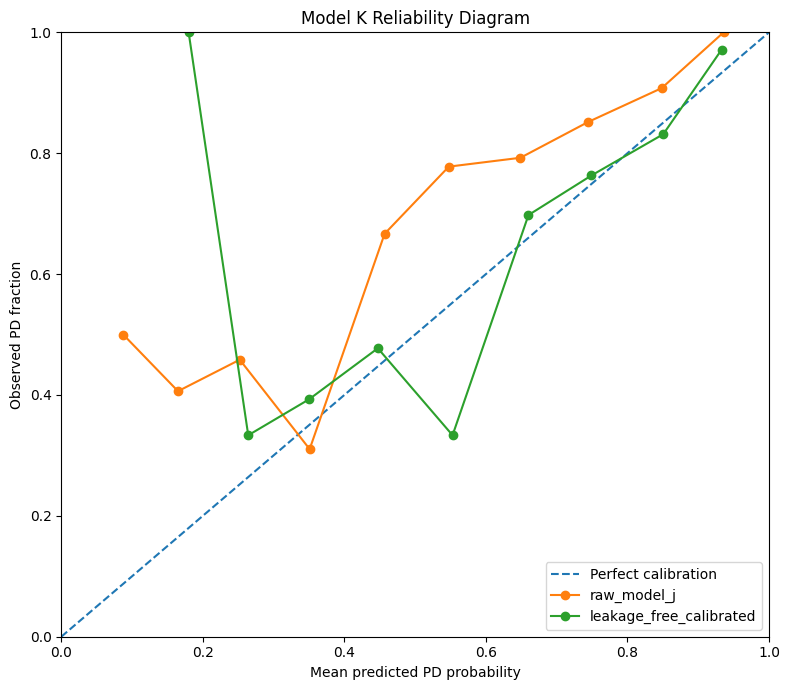

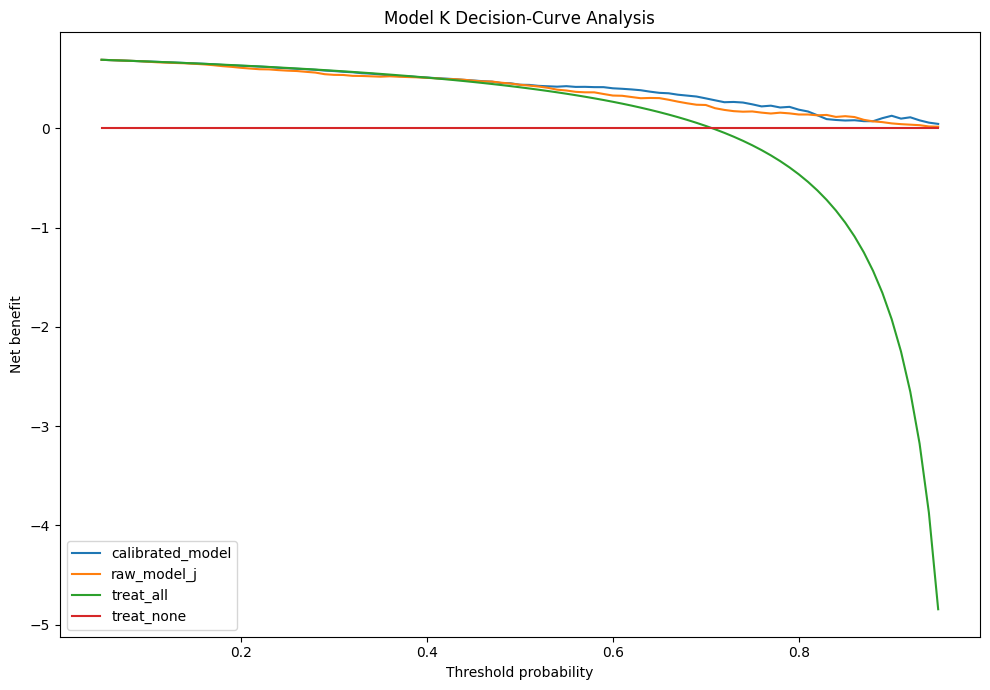

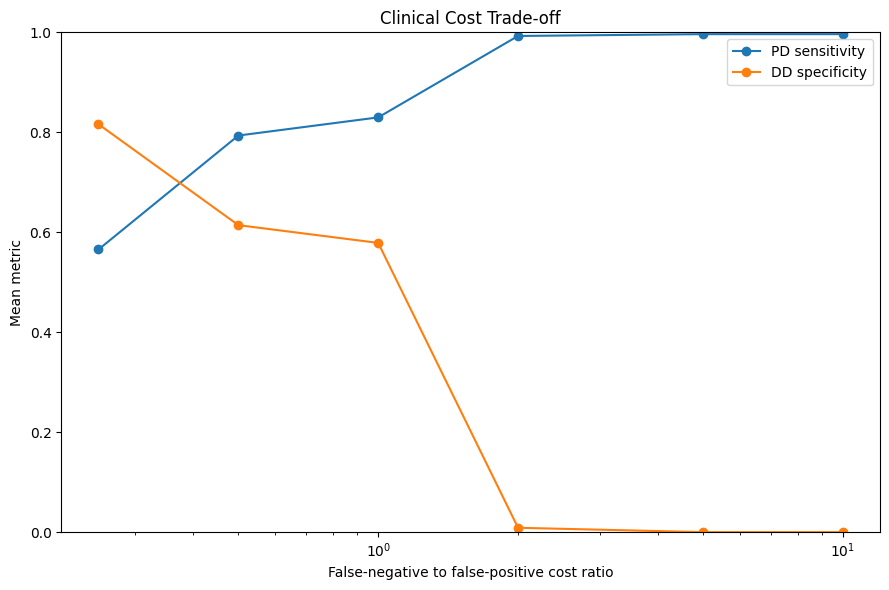

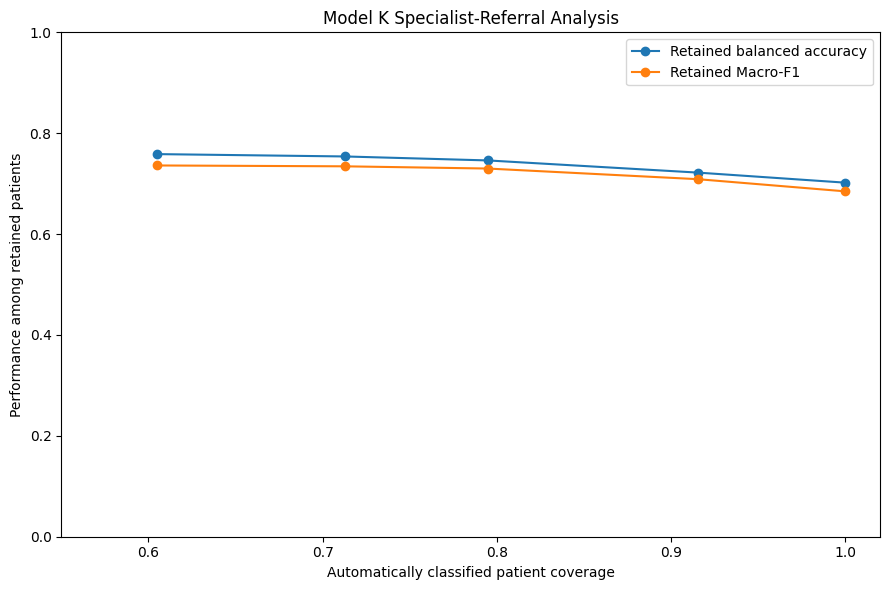

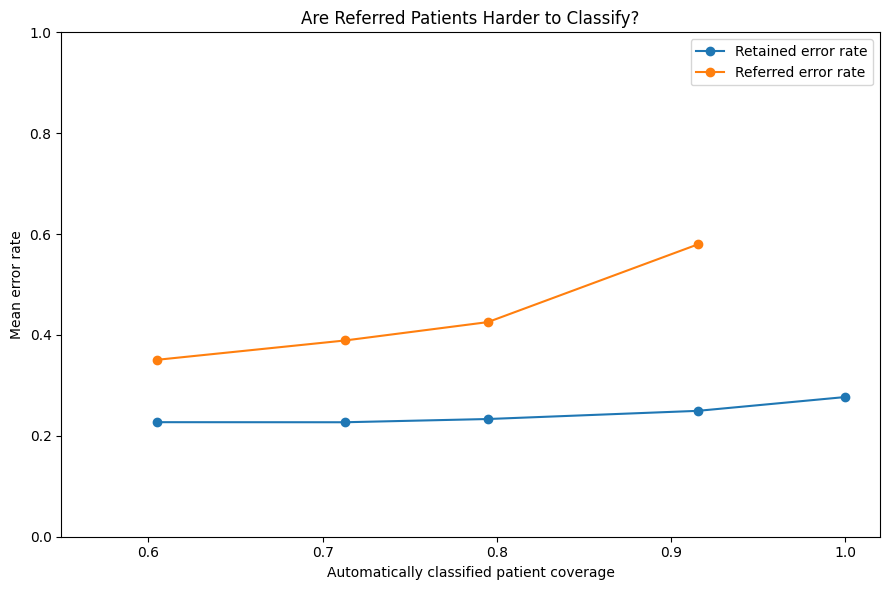


MODEL K COMPLETE

Overall comparison:

                            model  accuracy  balanced_accuracy  macro_f1  sensitivity_pd  specificity_dd  roc_auc  pr_auc  brier_score  ece_10_bins  true_negative  false_positive  false_negative  true_positive
                model_j_saved_raw    0.7333             0.7266    0.7033          0.7428          0.7105   0.7702  0.8894       0.1898       0.1475             81              33              71            205
    raw_fold_reselected_threshold    0.7410             0.7166    0.7033          0.7754          0.6579   0.7702  0.8894       0.1898       0.1475             75              39              62            214
selected_leakage_free_calibration    0.7231             0.7014    0.6860          0.7536          0.6491   0.7672  0.8882       0.1694       0.0452             74              40              68            208

Fold-specific calibration methods:

 test_outer_fold selected_calibration_method  raw_threshold  calibrated_threshold
 

In [ ]:
# ==================================================================================================
# MODEL K — LEAKAGE-FREE CALIBRATION, DECISION-CURVE, COST AND REFERRAL ANALYSIS
#
# Base model:
#   Model J — nms_items_only
#
# Calibration:
#   - Raw probabilities
#   - Platt scaling
#   - Isotonic regression
#   - Calibration method selected independently for each outer fold
#   - Method selection based on cross-fitted training Brier score and ECE
#
# Decision analysis:
#   - Reliability diagram
#   - Decision-curve analysis
#   - Model, treat-all and treat-none net benefit
#   - Standardized net benefit
#
# Cost analysis:
#   - Multiple false-negative to false-positive cost ratios
#   - Threshold selected from calibration-training data only
#   - Evaluated on untouched outer-test patients
#
# Referral analysis:
#   - 100%, 90%, 80%, 70%, 60% target retained coverage
#   - Least-confident cases referred to specialists
#   - Confidence cutoffs learned only from calibration-training patients
#
# Scientific safeguards:
#   - Same fixed five outer folds
#   - Current outer-test fold excluded from calibrator fitting and threshold selection
#   - Calibration selection uses cross-fitted predictions
#   - Each patient evaluated exactly once
# ==================================================================================================

import os
import sys
import gc
import time
import warnings
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    roc_curve
)

print("=" * 125)
print("MODEL K — CALIBRATION, DECISION-CURVE, COST AND SPECIALIST-REFERRAL ANALYSIS")
print("=" * 125)

# ==================================================================================================
# 1. CONFIGURATION
# ==================================================================================================

GLOBAL_SEED = 42
CALIBRATION_FOLDS = 5
N_BOOTSTRAPS = 2000

BASE_CONFIGURATION = "nms_items_only"

CLASSIFICATION_THRESHOLD_GRID = np.arange(
    0.10,
    0.901,
    0.0025
)

DECISION_THRESHOLD_GRID = np.arange(
    0.05,
    0.951,
    0.01
)

RELIABILITY_BIN_COUNT = 10

# Cost ratio means:
# false-negative cost : false-positive cost
COST_RATIOS = [
    0.25,
    0.50,
    1.00,
    2.00,
    5.00,
    10.00
]

# Fraction of patients automatically classified.
# Remaining patients are referred to a specialist.
TARGET_RETAINED_COVERAGES = [
    1.00,
    0.90,
    0.80,
    0.70,
    0.60
]

# ==================================================================================================
# 2. PATHS
# ==================================================================================================

BASE_DIR = Path(
    "/content/pads_dataset/"
    "pads-parkinsons-disease-smartwatch-dataset-1.0.0"
)

PROJECT_DIR = (
    BASE_DIR
    / "project_ready_data"
)

MODEL_J_DIR = (
    PROJECT_DIR
    / "proposed_model_results"
    / "model_j_nms_ablation_shap_subgroups"
)

MODEL_J_PREDICTION_FILE = (
    MODEL_J_DIR
    / "model_j_patient_predictions.csv"
)

FIXED_SPLIT_FILE = (
    PROJECT_DIR
    / "baseline_results"
    / "logistic_regression_5fold"
    / "fixed_outer_5fold_splits.csv"
)

OUTPUT_DIR = (
    PROJECT_DIR
    / "proposed_model_results"
    / "model_k_calibration_decision_cost_referral"
)

FIGURE_DIR = (
    OUTPUT_DIR
    / "figures"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)


def locate_required_file(
    expected_path,
    filename
):
    if expected_path.exists():
        return expected_path

    matches = list(
        BASE_DIR.rglob(filename)
    )

    if not matches:
        raise FileNotFoundError(
            f"Required file nahi mili: {filename}"
        )

    return matches[0]


MODEL_J_PREDICTION_FILE = locate_required_file(
    MODEL_J_PREDICTION_FILE,
    "model_j_patient_predictions.csv"
)

FIXED_SPLIT_FILE = locate_required_file(
    FIXED_SPLIT_FILE,
    "fixed_outer_5fold_splits.csv"
)

print("\nModel-J predictions:", MODEL_J_PREDICTION_FILE)
print("Fixed-fold file    :", FIXED_SPLIT_FILE)
print("Output directory   :", OUTPUT_DIR)

# ==================================================================================================
# 3. LOAD MODEL-J OOF PREDICTIONS
# ==================================================================================================

predictions_df = pd.read_csv(
    MODEL_J_PREDICTION_FILE,
    dtype={"patient_id": str}
)

predictions_df["patient_id"] = (
    predictions_df["patient_id"]
    .astype(str)
    .str.replace(
        ".0",
        "",
        regex=False
    )
    .str.zfill(3)
)

if "configuration" not in predictions_df.columns:
    raise ValueError(
        "Model-J patient file mein configuration column nahi hai."
    )

model_df = (
    predictions_df.loc[
        predictions_df[
            "configuration"
        ] == BASE_CONFIGURATION
    ]
    .copy()
)

if model_df.empty:
    raise ValueError(
        f"Configuration nahi mili: {BASE_CONFIGURATION}"
    )

model_df = (
    model_df
    .drop_duplicates(
        subset=["patient_id"],
        keep="last"
    )
    .sort_values(
        "patient_id"
    )
    .reset_index(
        drop=True
    )
)

required_columns = {
    "patient_id",
    "outer_fold",
    "true_label",
    "predicted_probability_pd",
    "predicted_label"
}

missing_columns = (
    required_columns
    - set(model_df.columns)
)

if missing_columns:
    raise ValueError(
        f"Missing prediction columns: {sorted(missing_columns)}"
    )

model_df["outer_fold"] = pd.to_numeric(
    model_df["outer_fold"],
    errors="raise"
).astype(int)

model_df["true_label"] = pd.to_numeric(
    model_df["true_label"],
    errors="raise"
).astype(int)

model_df["predicted_probability_pd"] = pd.to_numeric(
    model_df["predicted_probability_pd"],
    errors="raise"
).astype(float)

model_df["predicted_label"] = pd.to_numeric(
    model_df["predicted_label"],
    errors="raise"
).astype(int)

patient_ids = model_df[
    "patient_id"
].to_numpy()

outer_folds = model_df[
    "outer_fold"
].to_numpy(
    dtype=int
)

y = model_df[
    "true_label"
].to_numpy(
    dtype=int
)

raw_probability = model_df[
    "predicted_probability_pd"
].to_numpy(
    dtype=float
)

saved_model_j_prediction = model_df[
    "predicted_label"
].to_numpy(
    dtype=int
)

N_PATIENTS = len(model_df)

if N_PATIENTS != 390:
    print(
        "⚠️ Expected 390 patients, found:",
        N_PATIENTS
    )

if len(np.unique(patient_ids)) != N_PATIENTS:
    raise RuntimeError(
        "Duplicate patient IDs detected."
    )

if set(np.unique(outer_folds)) != {
    1, 2, 3, 4, 5
}:
    raise RuntimeError(
        f"Unexpected outer folds: {sorted(np.unique(outer_folds))}"
    )

print("\nPatients:", N_PATIENTS)
print("PD      :", int(np.sum(y == 1)))
print("DD      :", int(np.sum(y == 0)))
print("Folds   :", sorted(np.unique(outer_folds)))

# ==================================================================================================
# 4. METRIC HELPERS
# ==================================================================================================

def expected_calibration_error(
    labels,
    probabilities,
    n_bins=10
):
    labels = np.asarray(
        labels,
        dtype=int
    )

    probabilities = np.asarray(
        probabilities,
        dtype=float
    )

    bin_edges = np.linspace(
        0.0,
        1.0,
        n_bins + 1
    )

    ece = 0.0

    for bin_index in range(n_bins):
        lower = bin_edges[bin_index]
        upper = bin_edges[
            bin_index + 1
        ]

        if bin_index == n_bins - 1:
            mask = (
                (probabilities >= lower)
                & (probabilities <= upper)
            )
        else:
            mask = (
                (probabilities >= lower)
                & (probabilities < upper)
            )

        if not np.any(mask):
            continue

        bin_accuracy = np.mean(
            labels[mask]
        )

        bin_confidence = np.mean(
            probabilities[mask]
        )

        ece += (
            np.mean(mask)
            * abs(
                bin_accuracy
                - bin_confidence
            )
        )

    return float(ece)


def calculate_metrics(
    labels,
    predictions,
    probabilities
):
    labels = np.asarray(
        labels,
        dtype=int
    )

    predictions = np.asarray(
        predictions,
        dtype=int
    )

    probabilities = np.asarray(
        probabilities,
        dtype=float
    )

    tn, fp, fn, tp = confusion_matrix(
        labels,
        predictions,
        labels=[0, 1]
    ).ravel()

    return {
        "accuracy": accuracy_score(
            labels,
            predictions
        ),

        "balanced_accuracy": balanced_accuracy_score(
            labels,
            predictions
        ),

        "macro_f1": f1_score(
            labels,
            predictions,
            average="macro",
            zero_division=0
        ),

        "sensitivity_pd": (
            tp / (tp + fn)
            if (tp + fn) > 0
            else np.nan
        ),

        "specificity_dd": (
            tn / (tn + fp)
            if (tn + fp) > 0
            else np.nan
        ),

        "precision_pd": precision_score(
            labels,
            predictions,
            pos_label=1,
            zero_division=0
        ),

        "roc_auc": roc_auc_score(
            labels,
            probabilities
        ),

        "pr_auc": average_precision_score(
            labels,
            probabilities
        ),

        "brier_score": brier_score_loss(
            labels,
            probabilities
        ),

        "ece_10_bins": expected_calibration_error(
            labels,
            probabilities,
            n_bins=10
        ),

        "true_negative": int(tn),
        "false_positive": int(fp),
        "false_negative": int(fn),
        "true_positive": int(tp)
    }


def select_balanced_threshold(
    labels,
    probabilities
):
    rows = []

    for threshold in CLASSIFICATION_THRESHOLD_GRID:
        predictions = (
            probabilities >= threshold
        ).astype(int)

        rows.append({
            "threshold": float(
                threshold
            ),

            "balanced_accuracy": balanced_accuracy_score(
                labels,
                predictions
            ),

            "macro_f1": f1_score(
                labels,
                predictions,
                average="macro",
                zero_division=0
            ),

            "distance_from_half": abs(
                threshold - 0.5
            )
        })

    threshold_df = pd.DataFrame(
        rows
    )

    best_row = (
        threshold_df
        .sort_values(
            [
                "balanced_accuracy",
                "macro_f1",
                "distance_from_half"
            ],
            ascending=[
                False,
                False,
                True
            ]
        )
        .iloc[0]
    )

    return (
        float(
            best_row[
                "threshold"
            ]
        ),
        threshold_df
    )


def fit_platt_calibrator(
    probabilities,
    labels
):
    probabilities = np.clip(
        np.asarray(
            probabilities,
            dtype=float
        ),
        1e-6,
        1 - 1e-6
    )

    logits = np.log(
        probabilities
        / (
            1 - probabilities
        )
    ).reshape(-1, 1)

    calibrator = LogisticRegression(
        C=1.0,
        penalty="l2",
        solver="liblinear",
        max_iter=5000,
        random_state=GLOBAL_SEED
    )

    calibrator.fit(
        logits,
        labels
    )

    return calibrator


def predict_platt(
    calibrator,
    probabilities
):
    probabilities = np.clip(
        np.asarray(
            probabilities,
            dtype=float
        ),
        1e-6,
        1 - 1e-6
    )

    logits = np.log(
        probabilities
        / (
            1 - probabilities
        )
    ).reshape(-1, 1)

    return calibrator.predict_proba(
        logits
    )[:, 1]


def fit_isotonic_calibrator(
    probabilities,
    labels
):
    calibrator = IsotonicRegression(
        y_min=0.0,
        y_max=1.0,
        out_of_bounds="clip"
    )

    calibrator.fit(
        probabilities,
        labels
    )

    return calibrator


def predict_isotonic(
    calibrator,
    probabilities
):
    return np.asarray(
        calibrator.predict(
            probabilities
        ),
        dtype=float
    )


def reliability_table(
    labels,
    probabilities,
    model_name,
    n_bins=10
):
    labels = np.asarray(
        labels,
        dtype=int
    )

    probabilities = np.asarray(
        probabilities,
        dtype=float
    )

    bin_edges = np.linspace(
        0.0,
        1.0,
        n_bins + 1
    )

    rows = []

    for bin_index in range(n_bins):
        lower = bin_edges[
            bin_index
        ]

        upper = bin_edges[
            bin_index + 1
        ]

        if bin_index == n_bins - 1:
            mask = (
                (probabilities >= lower)
                & (probabilities <= upper)
            )
        else:
            mask = (
                (probabilities >= lower)
                & (probabilities < upper)
            )

        patient_count = int(
            np.sum(mask)
        )

        if patient_count == 0:
            continue

        rows.append({
            "model": model_name,
            "bin_index": bin_index + 1,
            "bin_lower": lower,
            "bin_upper": upper,
            "patient_count": patient_count,
            "mean_predicted_probability": float(
                np.mean(
                    probabilities[mask]
                )
            ),
            "observed_pd_fraction": float(
                np.mean(
                    labels[mask]
                )
            ),
            "absolute_calibration_error": float(
                abs(
                    np.mean(
                        labels[mask]
                    )
                    - np.mean(
                        probabilities[mask]
                    )
                )
            )
        })

    return pd.DataFrame(
        rows
    )


def net_benefit(
    labels,
    probabilities,
    threshold
):
    predictions = (
        probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        labels,
        predictions,
        labels=[0, 1]
    ).ravel()

    patient_count = len(
        labels
    )

    odds = (
        threshold
        / (
            1 - threshold
        )
    )

    return (
        tp / patient_count
        - fp / patient_count
        * odds
    )


def treat_all_net_benefit(
    labels,
    threshold
):
    prevalence = float(
        np.mean(labels)
    )

    odds = (
        threshold
        / (
            1 - threshold
        )
    )

    return (
        prevalence
        - (
            1 - prevalence
        )
        * odds
    )


def normalized_confusion_cost(
    labels,
    predictions,
    false_negative_cost,
    false_positive_cost
):
    tn, fp, fn, tp = confusion_matrix(
        labels,
        predictions,
        labels=[0, 1]
    ).ravel()

    total_cost = (
        false_negative_cost
        * fn
        + false_positive_cost
        * fp
    )

    return float(
        total_cost
        / len(labels)
    )


def select_cost_threshold(
    labels,
    probabilities,
    false_negative_cost,
    false_positive_cost
):
    rows = []

    for threshold in CLASSIFICATION_THRESHOLD_GRID:
        predictions = (
            probabilities >= threshold
        ).astype(int)

        cost = normalized_confusion_cost(
            labels,
            predictions,
            false_negative_cost,
            false_positive_cost
        )

        rows.append({
            "threshold": float(
                threshold
            ),
            "normalized_cost": cost
        })

    table = pd.DataFrame(
        rows
    )

    best_row = (
        table
        .sort_values(
            [
                "normalized_cost",
                "threshold"
            ],
            ascending=[
                True,
                True
            ]
        )
        .iloc[0]
    )

    return (
        float(
            best_row[
                "threshold"
            ]
        ),
        table
    )

# ==================================================================================================
# 5. FOLD-WISE LEAKAGE-FREE CALIBRATION
# ==================================================================================================

calibrated_probability = np.full(
    N_PATIENTS,
    np.nan,
    dtype=float
)

calibrated_prediction = np.full(
    N_PATIENTS,
    -1,
    dtype=int
)

raw_reselected_prediction = np.full(
    N_PATIENTS,
    -1,
    dtype=int
)

calibration_method_rows = []
fold_metric_rows = []
classification_threshold_rows = []
calibration_training_rows = []

# Store fold-specific cross-fitted calibration-training probabilities.
fold_training_calibrated_probabilities = {}

for test_fold in sorted(
    np.unique(
        outer_folds
    )
):
    train_mask = (
        outer_folds != test_fold
    )

    test_mask = (
        outer_folds == test_fold
    )

    train_y = y[
        train_mask
    ]

    test_y = y[
        test_mask
    ]

    train_raw = raw_probability[
        train_mask
    ]

    test_raw = raw_probability[
        test_mask
    ]

    # ----------------------------------------------------------------------------------------------
    # Cross-fitted calibration on calibration-training patients.
    # ----------------------------------------------------------------------------------------------

    calibration_splitter = StratifiedKFold(
        n_splits=CALIBRATION_FOLDS,
        shuffle=True,
        random_state=(
            GLOBAL_SEED
            + int(test_fold) * 1000
        )
    )

    method_cross_fitted = {
        "raw": train_raw.copy(),
        "platt": np.full(
            len(train_y),
            np.nan,
            dtype=float
        ),
        "isotonic": np.full(
            len(train_y),
            np.nan,
            dtype=float
        )
    }

    for calibration_fold, (
        calibration_train_index,
        calibration_validation_index
    ) in enumerate(
        calibration_splitter.split(
            train_raw,
            train_y
        ),
        start=1
    ):
        inner_train_probability = train_raw[
            calibration_train_index
        ]

        inner_train_y = train_y[
            calibration_train_index
        ]

        inner_validation_probability = train_raw[
            calibration_validation_index
        ]

        # Platt
        platt_model = fit_platt_calibrator(
            inner_train_probability,
            inner_train_y
        )

        method_cross_fitted[
            "platt"
        ][
            calibration_validation_index
        ] = predict_platt(
            platt_model,
            inner_validation_probability
        )

        # Isotonic
        isotonic_model = fit_isotonic_calibrator(
            inner_train_probability,
            inner_train_y
        )

        method_cross_fitted[
            "isotonic"
        ][
            calibration_validation_index
        ] = predict_isotonic(
            isotonic_model,
            inner_validation_probability
        )

    # ----------------------------------------------------------------------------------------------
    # Choose calibration method on cross-fitted calibration-training probabilities.
    # ----------------------------------------------------------------------------------------------

    candidate_method_rows = []

    for method_name, method_probability in (
        method_cross_fitted.items()
    ):
        if np.isnan(
            method_probability
        ).any():
            raise RuntimeError(
                f"Missing calibration-training probabilities: "
                f"fold={test_fold}, method={method_name}"
            )

        candidate_method_rows.append({
            "test_outer_fold": int(
                test_fold
            ),
            "calibration_method": method_name,
            "brier_score": brier_score_loss(
                train_y,
                method_probability
            ),
            "ece_10_bins": expected_calibration_error(
                train_y,
                method_probability,
                n_bins=10
            ),
            "roc_auc": roc_auc_score(
                train_y,
                method_probability
            )
        })

    candidate_method_df = pd.DataFrame(
        candidate_method_rows
    )

    selected_method_row = (
        candidate_method_df
        .sort_values(
            [
                "brier_score",
                "ece_10_bins",
                "roc_auc"
            ],
            ascending=[
                True,
                True,
                False
            ]
        )
        .iloc[0]
    )

    selected_method = selected_method_row[
        "calibration_method"
    ]

    selected_train_calibrated_probability = (
        method_cross_fitted[
            selected_method
        ]
    )

    # Select classification threshold using only calibration-training patients.
    calibrated_threshold, _ = (
        select_balanced_threshold(
            train_y,
            selected_train_calibrated_probability
        )
    )

    raw_threshold, _ = (
        select_balanced_threshold(
            train_y,
            train_raw
        )
    )

    # ----------------------------------------------------------------------------------------------
    # Fit selected calibrator on all calibration-training patients.
    # ----------------------------------------------------------------------------------------------

    if selected_method == "raw":
        test_calibrated_probability = (
            test_raw.copy()
        )

    elif selected_method == "platt":
        final_calibrator = fit_platt_calibrator(
            train_raw,
            train_y
        )

        test_calibrated_probability = (
            predict_platt(
                final_calibrator,
                test_raw
            )
        )

    elif selected_method == "isotonic":
        final_calibrator = (
            fit_isotonic_calibrator(
                train_raw,
                train_y
            )
        )

        test_calibrated_probability = (
            predict_isotonic(
                final_calibrator,
                test_raw
            )
        )

    else:
        raise RuntimeError(
            f"Unexpected calibration method: {selected_method}"
        )

    test_calibrated_prediction = (
        test_calibrated_probability
        >= calibrated_threshold
    ).astype(int)

    test_raw_reselected_prediction = (
        test_raw
        >= raw_threshold
    ).astype(int)

    calibrated_probability[
        test_mask
    ] = test_calibrated_probability

    calibrated_prediction[
        test_mask
    ] = test_calibrated_prediction

    raw_reselected_prediction[
        test_mask
    ] = test_raw_reselected_prediction

    fold_training_calibrated_probabilities[
        int(test_fold)
    ] = {
        "patient_ids": patient_ids[
            train_mask
        ],
        "labels": train_y,
        "probabilities": (
            selected_train_calibrated_probability
        ),
        "selected_method": selected_method,
        "classification_threshold": (
            calibrated_threshold
        )
    }

    candidate_method_df[
        "selected"
    ] = (
        candidate_method_df[
            "calibration_method"
        ] == selected_method
    )

    calibration_method_rows.append(
        candidate_method_df
    )

    classification_threshold_rows.append({
        "test_outer_fold": int(
            test_fold
        ),
        "selected_calibration_method": (
            selected_method
        ),
        "raw_threshold": raw_threshold,
        "calibrated_threshold": calibrated_threshold
    })

    for method_name, method_probability in (
        method_cross_fitted.items()
    ):
        for local_index in range(
            len(train_y)
        ):
            calibration_training_rows.append({
                "test_outer_fold": int(
                    test_fold
                ),
                "patient_id": patient_ids[
                    train_mask
                ][
                    local_index
                ],
                "true_label": int(
                    train_y[
                        local_index
                    ]
                ),
                "calibration_method": (
                    method_name
                ),
                "cross_fitted_probability": float(
                    method_probability[
                        local_index
                    ]
                ),
                "selected_method": int(
                    method_name
                    == selected_method
                )
            })

    raw_fold_metrics = calculate_metrics(
        test_y,
        test_raw_reselected_prediction,
        test_raw
    )

    calibrated_fold_metrics = calculate_metrics(
        test_y,
        test_calibrated_prediction,
        test_calibrated_probability
    )

    fold_metric_rows.append({
        "outer_fold": int(
            test_fold
        ),
        "model": "raw_reselected_threshold",
        "calibration_method": "raw",
        "threshold": raw_threshold,
        **raw_fold_metrics
    })

    fold_metric_rows.append({
        "outer_fold": int(
            test_fold
        ),
        "model": "selected_calibrated",
        "calibration_method": (
            selected_method
        ),
        "threshold": calibrated_threshold,
        **calibrated_fold_metrics
    })

    print("\n" + "-" * 105)
    print(
        f"OUTER FOLD {test_fold}"
    )
    print("-" * 105)

    print(
        "Selected calibration:",
        selected_method
    )

    print(
        "Calibration-training Brier:",
        round(
            float(
                selected_method_row[
                    "brier_score"
                ]
            ),
            4
        )
    )

    print(
        "Selected threshold:",
        round(
            calibrated_threshold,
            4
        )
    )

    print(
        "Test BA:",
        round(
            calibrated_fold_metrics[
                "balanced_accuracy"
            ],
            4
        )
    )

    print(
        "Test Brier:",
        round(
            calibrated_fold_metrics[
                "brier_score"
            ],
            4
        )
    )

# Verification
if np.isnan(
    calibrated_probability
).any():
    raise RuntimeError(
        "Some calibrated outer-test probabilities are missing."
    )

if np.any(
    calibrated_prediction < 0
):
    raise RuntimeError(
        "Some calibrated outer-test predictions are missing."
    )

# ==================================================================================================
# 6. OVERALL RAW AND CALIBRATED RESULTS
# ==================================================================================================

overall_rows = []

saved_raw_metrics = calculate_metrics(
    y,
    saved_model_j_prediction,
    raw_probability
)

raw_reselected_metrics = calculate_metrics(
    y,
    raw_reselected_prediction,
    raw_probability
)

calibrated_metrics = calculate_metrics(
    y,
    calibrated_prediction,
    calibrated_probability
)

overall_rows.append({
    "model": "model_j_saved_raw",
    **saved_raw_metrics
})

overall_rows.append({
    "model": "raw_fold_reselected_threshold",
    **raw_reselected_metrics
})

overall_rows.append({
    "model": "selected_leakage_free_calibration",
    **calibrated_metrics
})

overall_df = pd.DataFrame(
    overall_rows
)

fold_results_df = pd.DataFrame(
    fold_metric_rows
)

calibration_methods_df = pd.concat(
    calibration_method_rows,
    ignore_index=True
)

classification_thresholds_df = pd.DataFrame(
    classification_threshold_rows
)

calibration_training_df = pd.DataFrame(
    calibration_training_rows
)

# ==================================================================================================
# 7. RELIABILITY ANALYSIS
# ==================================================================================================

reliability_raw_df = reliability_table(
    y,
    raw_probability,
    model_name="raw_model_j",
    n_bins=RELIABILITY_BIN_COUNT
)

reliability_calibrated_df = reliability_table(
    y,
    calibrated_probability,
    model_name="leakage_free_calibrated",
    n_bins=RELIABILITY_BIN_COUNT
)

reliability_df = pd.concat(
    [
        reliability_raw_df,
        reliability_calibrated_df
    ],
    ignore_index=True
)

# ==================================================================================================
# 8. DECISION-CURVE ANALYSIS
# ==================================================================================================

decision_curve_rows = []

for threshold in DECISION_THRESHOLD_GRID:
    model_nb = net_benefit(
        y,
        calibrated_probability,
        threshold
    )

    raw_nb = net_benefit(
        y,
        raw_probability,
        threshold
    )

    treat_all_nb = treat_all_net_benefit(
        y,
        threshold
    )

    treat_none_nb = 0.0

    prevalence = float(
        np.mean(y)
    )

    standardized_model_nb = (
        model_nb / prevalence
        if prevalence > 0
        else np.nan
    )

    standardized_raw_nb = (
        raw_nb / prevalence
        if prevalence > 0
        else np.nan
    )

    decision_curve_rows.extend([
        {
            "threshold_probability": float(
                threshold
            ),
            "strategy": "calibrated_model",
            "net_benefit": float(
                model_nb
            ),
            "standardized_net_benefit": float(
                standardized_model_nb
            )
        },
        {
            "threshold_probability": float(
                threshold
            ),
            "strategy": "raw_model_j",
            "net_benefit": float(
                raw_nb
            ),
            "standardized_net_benefit": float(
                standardized_raw_nb
            )
        },
        {
            "threshold_probability": float(
                threshold
            ),
            "strategy": "treat_all",
            "net_benefit": float(
                treat_all_nb
            ),
            "standardized_net_benefit": (
                float(
                    treat_all_nb / prevalence
                )
                if prevalence > 0
                else np.nan
            )
        },
        {
            "threshold_probability": float(
                threshold
            ),
            "strategy": "treat_none",
            "net_benefit": float(
                treat_none_nb
            ),
            "standardized_net_benefit": 0.0
        }
    ])

decision_curve_df = pd.DataFrame(
    decision_curve_rows
)

# Clinically useful threshold ranges where calibrated model beats both alternatives.
useful_threshold_rows = []

for threshold in DECISION_THRESHOLD_GRID:
    subset = decision_curve_df.loc[
        decision_curve_df[
            "threshold_probability"
        ] == threshold
    ].set_index(
        "strategy"
    )

    calibrated_nb = subset.loc[
        "calibrated_model",
        "net_benefit"
    ]

    treat_all_nb = subset.loc[
        "treat_all",
        "net_benefit"
    ]

    treat_none_nb = subset.loc[
        "treat_none",
        "net_benefit"
    ]

    useful_threshold_rows.append({
        "threshold_probability": float(
            threshold
        ),
        "calibrated_net_benefit": float(
            calibrated_nb
        ),
        "treat_all_net_benefit": float(
            treat_all_nb
        ),
        "treat_none_net_benefit": float(
            treat_none_nb
        ),
        "beats_treat_all": bool(
            calibrated_nb > treat_all_nb
        ),
        "beats_treat_none": bool(
            calibrated_nb > treat_none_nb
        ),
        "beats_both": bool(
            calibrated_nb > treat_all_nb
            and calibrated_nb > treat_none_nb
        )
    })

useful_threshold_df = pd.DataFrame(
    useful_threshold_rows
)

# ==================================================================================================
# 9. CONFUSION-COST ANALYSIS
# ==================================================================================================

cost_rows = []

for test_fold in sorted(
    np.unique(
        outer_folds
    )
):
    train_information = (
        fold_training_calibrated_probabilities[
            int(test_fold)
        ]
    )

    train_y = train_information[
        "labels"
    ]

    train_probability = train_information[
        "probabilities"
    ]

    test_mask = (
        outer_folds == test_fold
    )

    test_y = y[
        test_mask
    ]

    test_probability = calibrated_probability[
        test_mask
    ]

    for false_negative_cost in COST_RATIOS:
        false_positive_cost = 1.0

        selected_cost_threshold, _ = (
            select_cost_threshold(
                train_y,
                train_probability,
                false_negative_cost=(
                    false_negative_cost
                ),
                false_positive_cost=(
                    false_positive_cost
                )
            )
        )

        test_prediction = (
            test_probability
            >= selected_cost_threshold
        ).astype(int)

        metrics = calculate_metrics(
            test_y,
            test_prediction,
            test_probability
        )

        test_cost = normalized_confusion_cost(
            test_y,
            test_prediction,
            false_negative_cost=(
                false_negative_cost
            ),
            false_positive_cost=(
                false_positive_cost
            )
        )

        cost_rows.append({
            "outer_fold": int(
                test_fold
            ),
            "false_negative_cost": float(
                false_negative_cost
            ),
            "false_positive_cost": float(
                false_positive_cost
            ),
            "cost_ratio_fn_to_fp": float(
                false_negative_cost
                / false_positive_cost
            ),
            "selected_threshold": float(
                selected_cost_threshold
            ),
            "normalized_test_cost": float(
                test_cost
            ),
            "balanced_accuracy": metrics[
                "balanced_accuracy"
            ],
            "macro_f1": metrics[
                "macro_f1"
            ],
            "sensitivity_pd": metrics[
                "sensitivity_pd"
            ],
            "specificity_dd": metrics[
                "specificity_dd"
            ],
            "false_negative": metrics[
                "false_negative"
            ],
            "false_positive": metrics[
                "false_positive"
            ]
        })

cost_by_fold_df = pd.DataFrame(
    cost_rows
)

cost_summary_df = (
    cost_by_fold_df
    .groupby(
        "cost_ratio_fn_to_fp",
        as_index=False
    )
    .agg(
        mean_selected_threshold=(
            "selected_threshold",
            "mean"
        ),
        mean_normalized_test_cost=(
            "normalized_test_cost",
            "mean"
        ),
        mean_balanced_accuracy=(
            "balanced_accuracy",
            "mean"
        ),
        mean_macro_f1=(
            "macro_f1",
            "mean"
        ),
        mean_sensitivity_pd=(
            "sensitivity_pd",
            "mean"
        ),
        mean_specificity_dd=(
            "specificity_dd",
            "mean"
        ),
        total_false_negative=(
            "false_negative",
            "sum"
        ),
        total_false_positive=(
            "false_positive",
            "sum"
        )
    )
)

# ==================================================================================================
# 10. SPECIALIST-REFERRAL / SELECTIVE-PREDICTION ANALYSIS
# ==================================================================================================

referral_rows = []
referral_patient_rows = []

for test_fold in sorted(
    np.unique(
        outer_folds
    )
):
    train_information = (
        fold_training_calibrated_probabilities[
            int(test_fold)
        ]
    )

    train_y = train_information[
        "labels"
    ]

    train_probability = train_information[
        "probabilities"
    ]

    classification_threshold = (
        train_information[
            "classification_threshold"
        ]
    )

    test_mask = (
        outer_folds == test_fold
    )

    test_patient_ids = patient_ids[
        test_mask
    ]

    test_y = y[
        test_mask
    ]

    test_probability = calibrated_probability[
        test_mask
    ]

    # Confidence relative to the fold-specific clinical classification threshold.
    train_confidence = np.abs(
        train_probability
        - classification_threshold
    )

    test_confidence = np.abs(
        test_probability
        - classification_threshold
    )

    test_prediction = (
        test_probability
        >= classification_threshold
    ).astype(int)

    for target_coverage in TARGET_RETAINED_COVERAGES:
        if target_coverage >= 1.0:
            confidence_cutoff = -np.inf

        else:
            referral_fraction = (
                1.0 - target_coverage
            )

            confidence_cutoff = float(
                np.quantile(
                    train_confidence,
                    referral_fraction
                )
            )

        retained_mask = (
            test_confidence
            >= confidence_cutoff
        )

        referred_mask = (
            ~retained_mask
        )

        retained_count = int(
            np.sum(retained_mask)
        )

        referred_count = int(
            np.sum(referred_mask)
        )

        actual_coverage = (
            retained_count
            / len(test_y)
        )

        if (
            retained_count > 0
            and len(
                np.unique(
                    test_y[
                        retained_mask
                    ]
                )
            ) == 2
        ):
            retained_metrics = calculate_metrics(
                test_y[
                    retained_mask
                ],
                test_prediction[
                    retained_mask
                ],
                test_probability[
                    retained_mask
                ]
            )

        else:
            retained_metrics = {
                "accuracy": np.nan,
                "balanced_accuracy": np.nan,
                "macro_f1": np.nan,
                "sensitivity_pd": np.nan,
                "specificity_dd": np.nan,
                "precision_pd": np.nan,
                "roc_auc": np.nan,
                "pr_auc": np.nan,
                "brier_score": np.nan,
                "ece_10_bins": np.nan,
                "true_negative": np.nan,
                "false_positive": np.nan,
                "false_negative": np.nan,
                "true_positive": np.nan
            }

        referred_error_rate = (
            float(
                np.mean(
                    test_prediction[
                        referred_mask
                    ]
                    != test_y[
                        referred_mask
                    ]
                )
            )
            if referred_count > 0
            else np.nan
        )

        retained_error_rate = (
            float(
                np.mean(
                    test_prediction[
                        retained_mask
                    ]
                    != test_y[
                        retained_mask
                    ]
                )
            )
            if retained_count > 0
            else np.nan
        )

        referral_rows.append({
            "outer_fold": int(
                test_fold
            ),
            "target_retained_coverage": float(
                target_coverage
            ),
            "actual_retained_coverage": float(
                actual_coverage
            ),
            "confidence_cutoff": float(
                confidence_cutoff
            ),
            "retained_patients": retained_count,
            "referred_patients": referred_count,
            "retained_balanced_accuracy": (
                retained_metrics[
                    "balanced_accuracy"
                ]
            ),
            "retained_macro_f1": (
                retained_metrics[
                    "macro_f1"
                ]
            ),
            "retained_sensitivity_pd": (
                retained_metrics[
                    "sensitivity_pd"
                ]
            ),
            "retained_specificity_dd": (
                retained_metrics[
                    "specificity_dd"
                ]
            ),
            "retained_roc_auc": (
                retained_metrics[
                    "roc_auc"
                ]
            ),
            "retained_brier_score": (
                retained_metrics[
                    "brier_score"
                ]
            ),
            "retained_error_rate": (
                retained_error_rate
            ),
            "referred_error_rate": (
                referred_error_rate
            )
        })

        for local_index in range(
            len(test_y)
        ):
            referral_patient_rows.append({
                "patient_id": test_patient_ids[
                    local_index
                ],
                "outer_fold": int(
                    test_fold
                ),
                "target_retained_coverage": float(
                    target_coverage
                ),
                "true_label": int(
                    test_y[
                        local_index
                    ]
                ),
                "probability_pd": float(
                    test_probability[
                        local_index
                    ]
                ),
                "classification_threshold": float(
                    classification_threshold
                ),
                "confidence": float(
                    test_confidence[
                        local_index
                    ]
                ),
                "confidence_cutoff": float(
                    confidence_cutoff
                ),
                "predicted_label": int(
                    test_prediction[
                        local_index
                    ]
                ),
                "referred_to_specialist": int(
                    referred_mask[
                        local_index
                    ]
                ),
                "correct_prediction": int(
                    test_prediction[
                        local_index
                    ]
                    == test_y[
                        local_index
                    ]
                )
            })

referral_by_fold_df = pd.DataFrame(
    referral_rows
)

referral_patient_df = pd.DataFrame(
    referral_patient_rows
)

referral_summary_df = (
    referral_by_fold_df
    .groupby(
        "target_retained_coverage",
        as_index=False
    )
    .agg(
        mean_actual_retained_coverage=(
            "actual_retained_coverage",
            "mean"
        ),
        total_retained_patients=(
            "retained_patients",
            "sum"
        ),
        total_referred_patients=(
            "referred_patients",
            "sum"
        ),
        mean_retained_balanced_accuracy=(
            "retained_balanced_accuracy",
            "mean"
        ),
        mean_retained_macro_f1=(
            "retained_macro_f1",
            "mean"
        ),
        mean_retained_sensitivity_pd=(
            "retained_sensitivity_pd",
            "mean"
        ),
        mean_retained_specificity_dd=(
            "retained_specificity_dd",
            "mean"
        ),
        mean_retained_roc_auc=(
            "retained_roc_auc",
            "mean"
        ),
        mean_retained_brier_score=(
            "retained_brier_score",
            "mean"
        ),
        mean_retained_error_rate=(
            "retained_error_rate",
            "mean"
        ),
        mean_referred_error_rate=(
            "referred_error_rate",
            "mean"
        )
    )
)

# ==================================================================================================
# 11. BOOTSTRAP CONFIDENCE INTERVALS
# ==================================================================================================

bootstrap_rng = np.random.default_rng(
    GLOBAL_SEED
)

bootstrap_rows = []
paired_delta_rows = []

for bootstrap_iteration in range(
    N_BOOTSTRAPS
):
    sampled_indices = bootstrap_rng.integers(
        0,
        N_PATIENTS,
        size=N_PATIENTS
    )

    sampled_y = y[
        sampled_indices
    ]

    if len(
        np.unique(
            sampled_y
        )
    ) < 2:
        continue

    raw_metrics = calculate_metrics(
        sampled_y,
        saved_model_j_prediction[
            sampled_indices
        ],
        raw_probability[
            sampled_indices
        ]
    )

    calibrated_bootstrap_metrics = (
        calculate_metrics(
            sampled_y,
            calibrated_prediction[
                sampled_indices
            ],
            calibrated_probability[
                sampled_indices
            ]
        )
    )

    bootstrap_rows.append({
        "bootstrap_iteration": (
            bootstrap_iteration
        ),
        "model": "raw_model_j",
        **raw_metrics
    })

    bootstrap_rows.append({
        "bootstrap_iteration": (
            bootstrap_iteration
        ),
        "model": "calibrated_model_k",
        **calibrated_bootstrap_metrics
    })

    paired_delta_rows.append({
        "bootstrap_iteration": (
            bootstrap_iteration
        ),
        "balanced_accuracy_delta": (
            calibrated_bootstrap_metrics[
                "balanced_accuracy"
            ]
            - raw_metrics[
                "balanced_accuracy"
            ]
        ),
        "macro_f1_delta": (
            calibrated_bootstrap_metrics[
                "macro_f1"
            ]
            - raw_metrics[
                "macro_f1"
            ]
        ),
        "brier_delta": (
            calibrated_bootstrap_metrics[
                "brier_score"
            ]
            - raw_metrics[
                "brier_score"
            ]
        ),
        "ece_delta": (
            calibrated_bootstrap_metrics[
                "ece_10_bins"
            ]
            - raw_metrics[
                "ece_10_bins"
            ]
        )
    })

bootstrap_df = pd.DataFrame(
    bootstrap_rows
)

paired_delta_df = pd.DataFrame(
    paired_delta_rows
)

ci_rows = []

for model_name in [
    "raw_model_j",
    "calibrated_model_k"
]:
    model_subset = bootstrap_df.loc[
        bootstrap_df[
            "model"
        ] == model_name
    ]

    for metric_name in [
        "accuracy",
        "balanced_accuracy",
        "macro_f1",
        "sensitivity_pd",
        "specificity_dd",
        "roc_auc",
        "pr_auc",
        "brier_score",
        "ece_10_bins"
    ]:
        values = (
            model_subset[
                metric_name
            ]
            .dropna()
            .to_numpy()
        )

        ci_rows.append({
            "model": model_name,
            "metric": metric_name,
            "ci_95_lower": float(
                np.percentile(
                    values,
                    2.5
                )
            ),
            "ci_95_upper": float(
                np.percentile(
                    values,
                    97.5
                )
            )
        })

confidence_intervals_df = pd.DataFrame(
    ci_rows
)

paired_summary_rows = []

for metric_name in [
    "balanced_accuracy_delta",
    "macro_f1_delta",
    "brier_delta",
    "ece_delta"
]:
    values = paired_delta_df[
        metric_name
    ].to_numpy()

    paired_summary_rows.append({
        "metric": metric_name,
        "mean_bootstrap_delta": float(
            np.mean(values)
        ),
        "ci_95_lower": float(
            np.percentile(
                values,
                2.5
            )
        ),
        "ci_95_upper": float(
            np.percentile(
                values,
                97.5
            )
        ),
        "probability_delta_above_zero": float(
            np.mean(
                values > 0
            )
        )
    })

paired_summary_df = pd.DataFrame(
    paired_summary_rows
)

# ==================================================================================================
# 12. PATIENT-LEVEL OUTPUT
# ==================================================================================================

patient_output_df = pd.DataFrame({
    "patient_id": patient_ids,
    "outer_fold": outer_folds,
    "true_label": y,
    "raw_probability_pd": raw_probability,
    "model_j_saved_prediction": (
        saved_model_j_prediction
    ),
    "raw_reselected_prediction": (
        raw_reselected_prediction
    ),
    "calibrated_probability_pd": (
        calibrated_probability
    ),
    "calibrated_prediction": (
        calibrated_prediction
    ),
    "raw_absolute_error": np.abs(
        y - raw_probability
    ),
    "calibrated_absolute_error": np.abs(
        y - calibrated_probability
    ),
    "raw_correct": (
        saved_model_j_prediction == y
    ).astype(int),
    "calibrated_correct": (
        calibrated_prediction == y
    ).astype(int)
})

# ==================================================================================================
# 13. SAVE ALL TABLES
# ==================================================================================================

overall_df.to_csv(
    OUTPUT_DIR
    / "model_k_overall_comparison.csv",
    index=False
)

fold_results_df.to_csv(
    OUTPUT_DIR
    / "model_k_fold_results.csv",
    index=False
)

calibration_methods_df.to_csv(
    OUTPUT_DIR
    / "model_k_calibration_method_selection.csv",
    index=False
)

classification_thresholds_df.to_csv(
    OUTPUT_DIR
    / "model_k_classification_thresholds.csv",
    index=False
)

calibration_training_df.to_csv(
    OUTPUT_DIR
    / "model_k_cross_fitted_calibration_training_predictions.csv",
    index=False
)

patient_output_df.to_csv(
    OUTPUT_DIR
    / "model_k_patient_predictions.csv",
    index=False
)

reliability_df.to_csv(
    OUTPUT_DIR
    / "model_k_reliability_table.csv",
    index=False
)

decision_curve_df.to_csv(
    OUTPUT_DIR
    / "model_k_decision_curve.csv",
    index=False
)

useful_threshold_df.to_csv(
    OUTPUT_DIR
    / "model_k_decision_curve_useful_thresholds.csv",
    index=False
)

cost_by_fold_df.to_csv(
    OUTPUT_DIR
    / "model_k_confusion_cost_by_fold.csv",
    index=False
)

cost_summary_df.to_csv(
    OUTPUT_DIR
    / "model_k_confusion_cost_summary.csv",
    index=False
)

referral_by_fold_df.to_csv(
    OUTPUT_DIR
    / "model_k_referral_analysis_by_fold.csv",
    index=False
)

referral_summary_df.to_csv(
    OUTPUT_DIR
    / "model_k_referral_summary.csv",
    index=False
)

referral_patient_df.to_csv(
    OUTPUT_DIR
    / "model_k_referral_patient_decisions.csv",
    index=False
)

bootstrap_df.to_csv(
    OUTPUT_DIR
    / "model_k_bootstrap_metrics.csv",
    index=False
)

confidence_intervals_df.to_csv(
    OUTPUT_DIR
    / "model_k_confidence_intervals_95.csv",
    index=False
)

paired_delta_df.to_csv(
    OUTPUT_DIR
    / "model_k_paired_bootstrap_deltas.csv",
    index=False
)

paired_summary_df.to_csv(
    OUTPUT_DIR
    / "model_k_paired_bootstrap_summary.csv",
    index=False
)

# ==================================================================================================
# 14. FIGURES
# ==================================================================================================

# --------------------------------------------------------------------------------------------------
# Reliability diagram
# --------------------------------------------------------------------------------------------------

plt.figure(
    figsize=(8, 7)
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

for model_name in [
    "raw_model_j",
    "leakage_free_calibrated"
]:
    subset = reliability_df.loc[
        reliability_df[
            "model"
        ] == model_name
    ]

    plt.plot(
        subset[
            "mean_predicted_probability"
        ],
        subset[
            "observed_pd_fraction"
        ],
        marker="o",
        label=model_name
    )

plt.xlabel(
    "Mean predicted PD probability"
)

plt.ylabel(
    "Observed PD fraction"
)

plt.title(
    "Model K Reliability Diagram"
)

plt.xlim(
    0,
    1
)

plt.ylim(
    0,
    1
)

plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "01_model_k_reliability_diagram.png",
    dpi=240,
    bbox_inches="tight"
)

plt.show()
plt.close()

# --------------------------------------------------------------------------------------------------
# Decision curve
# --------------------------------------------------------------------------------------------------

plt.figure(
    figsize=(10, 7)
)

for strategy_name in [
    "calibrated_model",
    "raw_model_j",
    "treat_all",
    "treat_none"
]:
    subset = decision_curve_df.loc[
        decision_curve_df[
            "strategy"
        ] == strategy_name
    ]

    plt.plot(
        subset[
            "threshold_probability"
        ],
        subset[
            "net_benefit"
        ],
        label=strategy_name
    )

plt.xlabel(
    "Threshold probability"
)

plt.ylabel(
    "Net benefit"
)

plt.title(
    "Model K Decision-Curve Analysis"
)

plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "02_model_k_decision_curve.png",
    dpi=240,
    bbox_inches="tight"
)

plt.show()
plt.close()

# --------------------------------------------------------------------------------------------------
# Cost sensitivity/specificity trade-off
# --------------------------------------------------------------------------------------------------

plt.figure(
    figsize=(9, 6)
)

plt.plot(
    cost_summary_df[
        "cost_ratio_fn_to_fp"
    ],
    cost_summary_df[
        "mean_sensitivity_pd"
    ],
    marker="o",
    label="PD sensitivity"
)

plt.plot(
    cost_summary_df[
        "cost_ratio_fn_to_fp"
    ],
    cost_summary_df[
        "mean_specificity_dd"
    ],
    marker="o",
    label="DD specificity"
)

plt.xscale(
    "log"
)

plt.xlabel(
    "False-negative to false-positive cost ratio"
)

plt.ylabel(
    "Mean metric"
)

plt.title(
    "Clinical Cost Trade-off"
)

plt.ylim(
    0,
    1
)

plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "03_model_k_cost_tradeoff.png",
    dpi=240,
    bbox_inches="tight"
)

plt.show()
plt.close()

# --------------------------------------------------------------------------------------------------
# Referral performance
# --------------------------------------------------------------------------------------------------

plt.figure(
    figsize=(9, 6)
)

plt.plot(
    referral_summary_df[
        "mean_actual_retained_coverage"
    ],
    referral_summary_df[
        "mean_retained_balanced_accuracy"
    ],
    marker="o",
    label="Retained balanced accuracy"
)

plt.plot(
    referral_summary_df[
        "mean_actual_retained_coverage"
    ],
    referral_summary_df[
        "mean_retained_macro_f1"
    ],
    marker="o",
    label="Retained Macro-F1"
)

plt.xlabel(
    "Automatically classified patient coverage"
)

plt.ylabel(
    "Performance among retained patients"
)

plt.title(
    "Model K Specialist-Referral Analysis"
)

plt.xlim(
    0.55,
    1.02
)

plt.ylim(
    0,
    1
)

plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "04_model_k_referral_performance.png",
    dpi=240,
    bbox_inches="tight"
)

plt.show()
plt.close()

# --------------------------------------------------------------------------------------------------
# Referred vs retained error rate
# --------------------------------------------------------------------------------------------------

plt.figure(
    figsize=(9, 6)
)

plt.plot(
    referral_summary_df[
        "mean_actual_retained_coverage"
    ],
    referral_summary_df[
        "mean_retained_error_rate"
    ],
    marker="o",
    label="Retained error rate"
)

plt.plot(
    referral_summary_df[
        "mean_actual_retained_coverage"
    ],
    referral_summary_df[
        "mean_referred_error_rate"
    ],
    marker="o",
    label="Referred error rate"
)

plt.xlabel(
    "Automatically classified patient coverage"
)

plt.ylabel(
    "Mean error rate"
)

plt.title(
    "Are Referred Patients Harder to Classify?"
)

plt.xlim(
    0.55,
    1.02
)

plt.ylim(
    0,
    1
)

plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "05_model_k_referred_vs_retained_error.png",
    dpi=240,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ==================================================================================================
# 15. FINAL OUTPUT
# ==================================================================================================

print("\n" + "=" * 125)
print("MODEL K COMPLETE")
print("=" * 125)

display_columns = [
    "model",
    "accuracy",
    "balanced_accuracy",
    "macro_f1",
    "sensitivity_pd",
    "specificity_dd",
    "roc_auc",
    "pr_auc",
    "brier_score",
    "ece_10_bins",
    "true_negative",
    "false_positive",
    "false_negative",
    "true_positive"
]

print("\nOverall comparison:\n")

print(
    overall_df[
        display_columns
    ]
    .round(4)
    .to_string(
        index=False
    )
)

print("\nFold-specific calibration methods:\n")

print(
    classification_thresholds_df
    .round(4)
    .to_string(
        index=False
    )
)

print("\nCalibration-method selection scores:\n")

print(
    calibration_methods_df
    .sort_values(
        [
            "test_outer_fold",
            "brier_score"
        ]
    )
    .round(4)
    .to_string(
        index=False
    )
)

print("\nPaired bootstrap: calibrated minus raw:\n")

print(
    paired_summary_df
    .round(4)
    .to_string(
        index=False
    )
)

print("\nConfusion-cost summary:\n")

print(
    cost_summary_df
    .round(4)
    .to_string(
        index=False
    )
)

print("\nSpecialist-referral summary:\n")

print(
    referral_summary_df
    .round(4)
    .to_string(
        index=False
    )
)

useful_range = useful_threshold_df.loc[
    useful_threshold_df[
        "beats_both"
    ]
]

if not useful_range.empty:
    print(
        "\nCalibrated model beats both treat-all and treat-none from threshold:"
    )

    print(
        f"{useful_range['threshold_probability'].min():.2f} "
        f"to "
        f"{useful_range['threshold_probability'].max():.2f}"
    )

else:
    print(
        "\nNo tested threshold range beat both treat-all and treat-none."
    )

print("\nScientific safeguards:")
print("- Model-J nms_items_only untouched OOF probabilities used.")
print("- Current outer test fold excluded from calibration training.")
print("- Platt and isotonic selection used cross-fitted calibration-training predictions.")
print("- Calibration method selected using Brier score and ECE.")
print("- Classification threshold selected without current outer-test patients.")
print("- Decision-curve analysis includes treat-all and treat-none.")
print("- Clinical costs evaluated under multiple FN:FP ratios.")
print("- Referral confidence cutoffs learned from calibration-training patients.")
print("- Each patient evaluated exactly once.")
print("- 2,000 patient-level bootstrap samples.")

print("\nSaved files:")

for saved_file in sorted(
    OUTPUT_DIR.rglob("*")
):
    if saved_file.is_file():
        print(
            " -",
            saved_file.relative_to(
                OUTPUT_DIR
            )
        )

print(
    "\n✅ MODEL K CALIBRATION, DECISION, COST AND REFERRAL ANALYSIS FINISHED."
)

## Model L - questionnaire reduction (uses a Google Drive checkpoint; edit the path if needed)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
MODEL L — CPU MINIMAL NMS QUESTIONNAIRE WITH CHECKPOINT/RESUME
XGBoost version: 3.3.0
✅ CPU execution forced.

Feature file       : /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/feature_engineering/pads_engineered_features.csv
Fixed-fold file    : /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/baseline_results/logistic_regression_5fold/fixed_outer_5fold_splits.csv
Questionnaire path : /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/questionnaire
Drive checkpoint   : /content/drive/MyDrive/PADS_Model_L_CPU_Checkpoint/model_l_checkpoint.pkl
Drive output       : /content/drive/MyDrive/PADS_Model_L_CPU_Checkpoint

Patients: 390
PD      : 276
DD      : 114

Questionnaire files: 469
Matched patients   : 390/390
✅ Fixed five outer folds verified.

🆕 No check

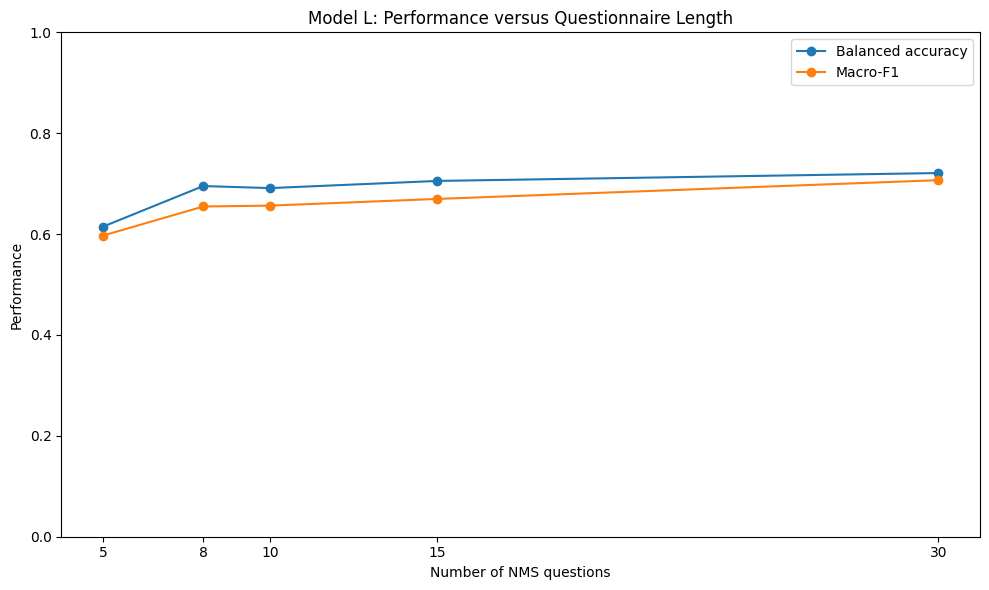

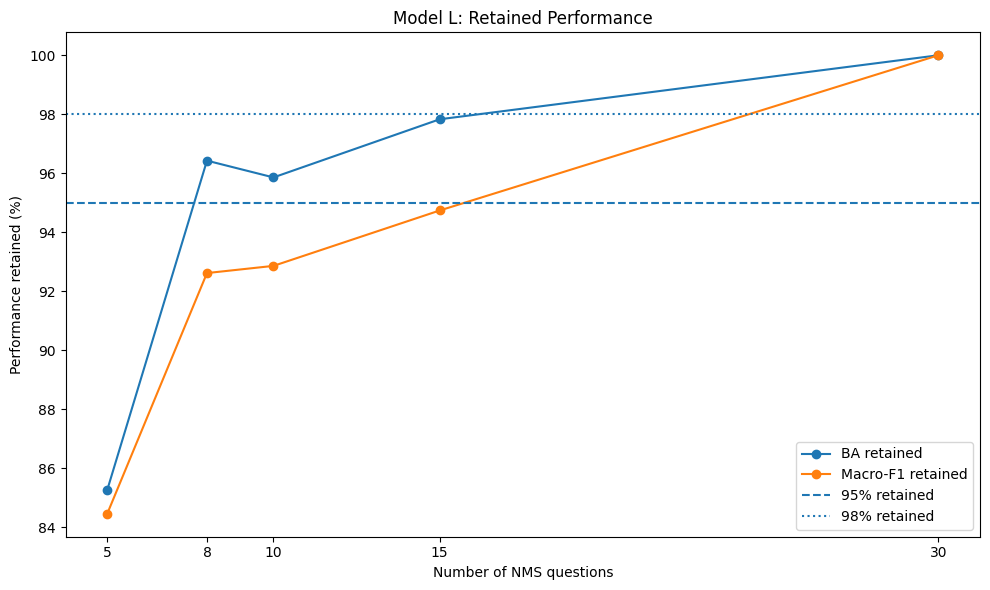


MODEL L COMPLETE

Overall questionnaire-length comparison:

 question_count  question_reduction_percent  accuracy  balanced_accuracy  macro_f1  sensitivity_pd  specificity_dd  roc_auc  pr_auc  brier_score  ece_10_bins  balanced_accuracy_retained_percent  macro_f1_retained_percent
              5                     83.3333    0.6333             0.6148    0.5971          0.6594          0.5702   0.6873  0.8241       0.2189       0.1628                             85.2684                    84.4642
              8                     73.3333    0.6744             0.6953    0.6547          0.6449          0.7456   0.7267  0.8557       0.2137       0.1673                             96.4295                    92.6205
             10                     66.6667    0.6795             0.6912    0.6564          0.6630          0.7193   0.7491  0.8511       0.1982       0.1536                             95.8609                    92.8639
             15                     50.0000    0.6923  

In [ ]:
# ==================================================================================================
# MODEL L — CPU + AUTOMATIC GOOGLE DRIVE CHECKPOINT/RESUME
#
# Compares: Top-5, Top-8, Top-10, Top-15, All-30 NMS questions
# Validation: fixed 5 outer folds + nested 5-fold training
# Saves after every outer fold to Google Drive
# Safe to rerun after Colab disconnect: completed folds will be skipped
# ==================================================================================================

from google.colab import drive
drive.mount("/content/drive")

import sys, subprocess, json, ast, time, gc, random, warnings, pickle, shutil
from pathlib import Path
from functools import partial

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

try:
    import xgboost as xgb
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "xgboost"])
    import xgboost as xgb

from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score, precision_score,
    confusion_matrix, roc_auc_score, average_precision_score,
    brier_score_loss, roc_curve
)

print("=" * 125)
print("MODEL L — CPU MINIMAL NMS QUESTIONNAIRE WITH CHECKPOINT/RESUME")
print("=" * 125)
print("XGBoost version:", xgb.__version__)
print("✅ CPU execution forced.")

# ==================================================================================================
# CONFIGURATION
# ==================================================================================================

GLOBAL_SEED = 42
INNER_FOLDS = 5
N_BOOTSTRAPS = 3000

QUESTION_COUNTS = [5, 8, 10, 15, 30]

NON_INFERIORITY_MARGIN_BA = 0.03
NON_INFERIORITY_MARGIN_F1 = 0.03

THRESHOLD_GRID = np.arange(0.20, 0.801, 0.005)

PARAMETER_CANDIDATES = [
    {
        "n_estimators": 250,
        "max_depth": 2,
        "learning_rate": 0.03,
        "min_child_weight": 4,
        "subsample": 0.85,
        "colsample_bytree": 0.85,
        "reg_alpha": 0.25,
        "reg_lambda": 3.0
    },
    {
        "n_estimators": 400,
        "max_depth": 2,
        "learning_rate": 0.02,
        "min_child_weight": 5,
        "subsample": 0.80,
        "colsample_bytree": 0.80,
        "reg_alpha": 0.50,
        "reg_lambda": 4.0
    },
    {
        "n_estimators": 450,
        "max_depth": 3,
        "learning_rate": 0.025,
        "min_child_weight": 5,
        "subsample": 0.80,
        "colsample_bytree": 0.75,
        "reg_alpha": 0.50,
        "reg_lambda": 4.0
    },
    {
        "n_estimators": 500,
        "max_depth": 3,
        "learning_rate": 0.015,
        "min_child_weight": 7,
        "subsample": 0.80,
        "colsample_bytree": 0.70,
        "reg_alpha": 1.00,
        "reg_lambda": 6.0
    }
]

random.seed(GLOBAL_SEED)
np.random.seed(GLOBAL_SEED)

# ==================================================================================================
# PATHS
# ==================================================================================================

BASE_DIR = Path(
    "/content/pads_dataset/"
    "pads-parkinsons-disease-smartwatch-dataset-1.0.0"
)

PROJECT_DIR = BASE_DIR / "project_ready_data"

FEATURE_FILE = (
    PROJECT_DIR
    / "feature_engineering"
    / "pads_engineered_features.csv"
)

FIXED_SPLIT_FILE = (
    PROJECT_DIR
    / "baseline_results"
    / "logistic_regression_5fold"
    / "fixed_outer_5fold_splits.csv"
)

QUESTIONNAIRE_DIR = BASE_DIR / "questionnaire"

LOCAL_OUTPUT_DIR = (
    PROJECT_DIR
    / "proposed_model_results"
    / "model_l_minimal_nms_questionnaire_cpu"
)

DRIVE_OUTPUT_DIR = Path(
    "/content/drive/MyDrive/"
    "PADS_Model_L_CPU_Checkpoint"
)

LOCAL_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DRIVE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

LOCAL_FIGURE_DIR = LOCAL_OUTPUT_DIR / "figures"
DRIVE_FIGURE_DIR = DRIVE_OUTPUT_DIR / "figures"

LOCAL_FIGURE_DIR.mkdir(parents=True, exist_ok=True)
DRIVE_FIGURE_DIR.mkdir(parents=True, exist_ok=True)

CHECKPOINT_FILE = DRIVE_OUTPUT_DIR / "model_l_checkpoint.pkl"

print("\nFeature file       :", FEATURE_FILE)
print("Fixed-fold file    :", FIXED_SPLIT_FILE)
print("Questionnaire path :", QUESTIONNAIRE_DIR)
print("Drive checkpoint   :", CHECKPOINT_FILE)
print("Drive output       :", DRIVE_OUTPUT_DIR)

for required_path in [
    FEATURE_FILE,
    FIXED_SPLIT_FILE,
    QUESTIONNAIRE_DIR
]:
    if not required_path.exists():
        raise FileNotFoundError(
            f"Required path missing:\n{required_path}"
        )

# ==================================================================================================
# LOAD COHORT
# ==================================================================================================

data = pd.read_csv(FEATURE_FILE)

PATIENT_ID_COLUMN = next(
    (
        col for col in
        ["patient_id", "id", "patient", "Patient_ID"]
        if col in data.columns
    ),
    None
)

TARGET_COLUMN = next(
    (
        col for col in
        ["y", "label", "target", "condition_2class", "diagnostic_group"]
        if col in data.columns
    ),
    None
)

if PATIENT_ID_COLUMN is None:
    raise ValueError("Patient-ID column nahi mili.")

if TARGET_COLUMN is None:
    raise ValueError("Target column nahi mila.")

data[PATIENT_ID_COLUMN] = (
    data[PATIENT_ID_COLUMN]
    .astype(str)
    .str.replace(".0", "", regex=False)
    .str.zfill(3)
)

if pd.api.types.is_numeric_dtype(data[TARGET_COLUMN]):

    target_numeric = pd.to_numeric(
        data[TARGET_COLUMN],
        errors="coerce"
    )

    unique_values = set(
        target_numeric.dropna().unique()
    )

    if unique_values.issubset({0, 1}):
        y = target_numeric.astype(int).to_numpy()

    elif unique_values.issubset({1, 2}):
        y = (target_numeric == 1).astype(int).to_numpy()

    else:
        raise ValueError(
            f"Unexpected target values: {sorted(unique_values)}"
        )

else:

    normalized_target = (
        data[TARGET_COLUMN]
        .astype(str)
        .str.lower()
        .str.strip()
    )

    label_map = {
        "pd": 1,
        "parkinson": 1,
        "parkinsons": 1,
        "parkinson's": 1,
        "1": 1,
        "dd": 0,
        "differential diagnosis": 0,
        "differential-diagnosis": 0,
        "other movement disorders": 0,
        "0": 0
    }

    mapped = normalized_target.map(label_map)

    if mapped.isna().any():
        raise ValueError(
            f"Unknown labels: {sorted(normalized_target[mapped.isna()].unique())}"
        )

    y = mapped.astype(int).to_numpy()

patient_ids = data[PATIENT_ID_COLUMN].to_numpy()
N_PATIENTS = len(patient_ids)

patient_to_index = {
    patient_id: index
    for index, patient_id in enumerate(patient_ids)
}

if len(np.unique(patient_ids)) != N_PATIENTS:
    raise RuntimeError("Duplicate patient IDs detected.")

print("\nPatients:", N_PATIENTS)
print("PD      :", int(np.sum(y == 1)))
print("DD      :", int(np.sum(y == 0)))

# ==================================================================================================
# PARSE QUESTIONNAIRE
# ==================================================================================================

questionnaire_files = sorted(
    QUESTIONNAIRE_DIR.glob("questionnaire_response_*.json")
)

if not questionnaire_files:
    questionnaire_files = sorted(
        BASE_DIR.rglob("questionnaire_response_*.json")
    )

questionnaire_rows = []
question_text_rows = []

for questionnaire_file in questionnaire_files:

    try:
        raw_object = json.loads(
            questionnaire_file.read_text(encoding="utf-8")
        )

        if isinstance(raw_object, list):
            raw_rows = raw_object

        elif isinstance(raw_object, dict):

            if isinstance(raw_object.get("item"), list):
                raw_rows = raw_object["item"]

            elif isinstance(raw_object.get("items"), list):
                raw_rows = raw_object["items"]

            elif isinstance(raw_object.get("entry"), list):
                raw_rows = raw_object["entry"]

            else:
                raw_rows = [raw_object]

        else:
            continue

        subject_id = None
        patient_row = {}

        for raw_row in raw_rows:

            if not isinstance(raw_row, dict):
                continue

            if subject_id is None:

                subject_candidate = (
                    raw_row.get("subject_id")
                    or raw_row.get("patient_id")
                    or raw_row.get("participant_id")
                )

                if subject_candidate is not None:
                    subject_id = (
                        str(subject_candidate)
                        .replace(".0", "")
                        .zfill(3)
                    )

            item = raw_row.get("item", raw_row)

            if isinstance(item, str):

                try:
                    item = ast.literal_eval(item)

                except Exception:

                    try:
                        item = json.loads(item)

                    except Exception:
                        continue

            if not isinstance(item, dict):
                continue

            link_id = (
                item.get("link_id")
                or item.get("linkId")
                or item.get("id")
            )

            if link_id is None:
                continue

            answer = item.get("answer")

            question_text = (
                item.get("text")
                or item.get("question")
                or ""
            )

            link_id = str(link_id).zfill(2)

            if isinstance(answer, bool):
                numeric_answer = int(answer)

            elif answer is None:
                numeric_answer = np.nan

            elif isinstance(answer, (int, float)):
                numeric_answer = float(answer)

            else:
                numeric_answer = {
                    "true": 1,
                    "yes": 1,
                    "1": 1,
                    "present": 1,
                    "false": 0,
                    "no": 0,
                    "0": 0,
                    "absent": 0
                }.get(
                    str(answer).strip().lower(),
                    np.nan
                )

            feature_name = f"nms_{link_id}"

            patient_row[feature_name] = numeric_answer

            question_text_rows.append({
                "feature": feature_name,
                "link_id": link_id,
                "question_text": question_text
            })

        if subject_id is None:
            subject_id = (
                questionnaire_file.stem
                .replace("questionnaire_response_", "")
                .zfill(3)
            )

        patient_row["patient_id"] = subject_id
        questionnaire_rows.append(patient_row)

    except Exception as error:
        print(
            "Could not parse:",
            questionnaire_file.name,
            str(error)[:100]
        )

questionnaire_df = pd.DataFrame(questionnaire_rows)

questionnaire_df["patient_id"] = (
    questionnaire_df["patient_id"]
    .astype(str)
    .str.replace(".0", "", regex=False)
    .str.zfill(3)
)

questionnaire_df = (
    questionnaire_df
    .drop_duplicates(subset=["patient_id"], keep="last")
    .set_index("patient_id")
)

NMS_COLUMNS = [
    f"nms_{index:02d}"
    for index in range(1, 31)
]

for column in NMS_COLUMNS:
    if column not in questionnaire_df.columns:
        questionnaire_df[column] = np.nan

questionnaire_df = questionnaire_df[NMS_COLUMNS].apply(
    pd.to_numeric,
    errors="coerce"
)

matched_patients = len(
    set(patient_ids).intersection(questionnaire_df.index)
)

print("\nQuestionnaire files:", len(questionnaire_files))
print("Matched patients   :", f"{matched_patients}/{N_PATIENTS}")

if matched_patients != N_PATIENTS:
    raise RuntimeError("Questionnaire matching 390/390 nahi hui.")

X_nms_df = (
    questionnaire_df
    .reindex(patient_ids)
    .reset_index(drop=True)
)

question_text_df = (
    pd.DataFrame(question_text_rows)
    .drop_duplicates(subset=["feature"])
    .sort_values("feature")
)

# ==================================================================================================
# FIXED OUTER FOLDS
# ==================================================================================================

fixed_splits = pd.read_csv(
    FIXED_SPLIT_FILE,
    dtype={"patient_id": str}
)

fixed_splits["patient_id"] = (
    fixed_splits["patient_id"]
    .astype(str)
    .str.replace(".0", "", regex=False)
    .str.zfill(3)
)

fixed_splits["fold"] = pd.to_numeric(
    fixed_splits["fold"],
    errors="raise"
).astype(int)

fixed_splits["role"] = (
    fixed_splits["role"]
    .astype(str)
    .str.lower()
    .str.strip()
)

AVAILABLE_FOLDS = sorted(
    fixed_splits["fold"].unique()
)

if list(AVAILABLE_FOLDS) != [1, 2, 3, 4, 5]:
    raise RuntimeError(
        f"Unexpected folds: {AVAILABLE_FOLDS}"
    )

if set(fixed_splits["patient_id"]) != set(patient_ids):
    raise RuntimeError(
        "Fixed-fold IDs and feature-table IDs do not match."
    )

test_frequency = (
    fixed_splits.loc[
        fixed_splits["role"] == "test"
    ]
    .groupby("patient_id")
    .size()
)

if (
    len(test_frequency) != N_PATIENTS
    or not (test_frequency == 1).all()
):
    raise RuntimeError(
        "Every patient must appear as outer-test exactly once."
    )

print("✅ Fixed five outer folds verified.")

# ==================================================================================================
# HELPERS
# ==================================================================================================

def ece_score(labels, probabilities, bins=10):

    labels = np.asarray(labels, dtype=int)
    probabilities = np.asarray(probabilities, dtype=float)

    edges = np.linspace(0, 1, bins + 1)
    result = 0.0

    for index in range(bins):

        lower = edges[index]
        upper = edges[index + 1]

        if index == bins - 1:
            mask = (
                (probabilities >= lower)
                & (probabilities <= upper)
            )
        else:
            mask = (
                (probabilities >= lower)
                & (probabilities < upper)
            )

        if np.any(mask):
            result += (
                np.mean(mask)
                * abs(
                    np.mean(labels[mask])
                    - np.mean(probabilities[mask])
                )
            )

    return float(result)


def calculate_metrics(labels, predictions, probabilities):

    tn, fp, fn, tp = confusion_matrix(
        labels,
        predictions,
        labels=[0, 1]
    ).ravel()

    return {
        "accuracy": accuracy_score(labels, predictions),

        "balanced_accuracy": balanced_accuracy_score(
            labels,
            predictions
        ),

        "macro_f1": f1_score(
            labels,
            predictions,
            average="macro",
            zero_division=0
        ),

        "sensitivity_pd": (
            tp / (tp + fn)
            if (tp + fn) > 0
            else np.nan
        ),

        "specificity_dd": (
            tn / (tn + fp)
            if (tn + fp) > 0
            else np.nan
        ),

        "precision_pd": precision_score(
            labels,
            predictions,
            pos_label=1,
            zero_division=0
        ),

        "roc_auc": roc_auc_score(labels, probabilities),

        "pr_auc": average_precision_score(
            labels,
            probabilities
        ),

        "brier_score": brier_score_loss(
            labels,
            probabilities
        ),

        "ece_10_bins": ece_score(
            labels,
            probabilities,
            10
        ),

        "true_negative": int(tn),
        "false_positive": int(fp),
        "false_negative": int(fn),
        "true_positive": int(tp)
    }


def select_threshold(labels, probabilities):

    rows = []

    for threshold in THRESHOLD_GRID:

        predictions = (
            probabilities >= threshold
        ).astype(int)

        rows.append({
            "threshold": float(threshold),

            "balanced_accuracy": balanced_accuracy_score(
                labels,
                predictions
            ),

            "macro_f1": f1_score(
                labels,
                predictions,
                average="macro",
                zero_division=0
            ),

            "distance": abs(threshold - 0.5)
        })

    table = pd.DataFrame(rows)

    best = (
        table
        .sort_values(
            ["balanced_accuracy", "macro_f1", "distance"],
            ascending=[False, False, True]
        )
        .iloc[0]
    )

    return float(best["threshold"])


def make_pipeline(parameters, question_count, seed):

    deterministic_mi = partial(
        mutual_info_classif,
        random_state=int(seed)
    )

    return Pipeline([
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "selector",
            SelectKBest(
                score_func=deterministic_mi,
                k=int(question_count)
            )
        ),
        (
            "classifier",
            xgb.XGBClassifier(
                **parameters,
                objective="binary:logistic",
                eval_metric="logloss",
                tree_method="hist",
                device="cpu",
                random_state=int(seed),
                n_jobs=-1,
                verbosity=0
            )
        )
    ])


def get_selected_features(pipeline, feature_names):

    mask = (
        pipeline
        .named_steps["selector"]
        .get_support()
    )

    return np.asarray(
        feature_names,
        dtype=object
    )[mask]


def save_checkpoint(state):

    with open(CHECKPOINT_FILE, "wb") as checkpoint_object:
        pickle.dump(state, checkpoint_object)

    print(
        "💾 Checkpoint saved:",
        CHECKPOINT_FILE
    )


def copy_results_to_drive():

    shutil.copytree(
        LOCAL_OUTPUT_DIR,
        DRIVE_OUTPUT_DIR / "final_results",
        dirs_exist_ok=True
    )

# ==================================================================================================
# INITIALIZE OR RESUME
# ==================================================================================================

MODEL_NAMES = [
    f"top_{count}"
    for count in QUESTION_COUNTS
]

if CHECKPOINT_FILE.exists():

    print("\n🔄 Existing checkpoint found. Resuming...")

    with open(CHECKPOINT_FILE, "rb") as checkpoint_object:
        state = pickle.load(checkpoint_object)

    probability_storage = state["probability_storage"]
    prediction_storage = state["prediction_storage"]
    patient_outer_fold = state["patient_outer_fold"]
    fold_result_rows = state["fold_result_rows"]
    inner_selection_rows = state["inner_selection_rows"]
    selected_question_rows = state["selected_question_rows"]
    threshold_rows = state["threshold_rows"]
    completed_folds = set(state["completed_folds"])

    print(
        "Completed folds:",
        sorted(completed_folds)
    )

else:

    print("\n🆕 No checkpoint found. Starting from Fold 1.")

    probability_storage = {
        model_name: np.full(
            N_PATIENTS,
            np.nan,
            dtype=float
        )
        for model_name in MODEL_NAMES
    }

    prediction_storage = {
        model_name: np.full(
            N_PATIENTS,
            -1,
            dtype=int
        )
        for model_name in MODEL_NAMES
    }

    patient_outer_fold = np.full(
        N_PATIENTS,
        -1,
        dtype=int
    )

    fold_result_rows = []
    inner_selection_rows = []
    selected_question_rows = []
    threshold_rows = []
    completed_folds = set()

total_start = time.time()

# ==================================================================================================
# OUTER-FOLD EXPERIMENT
# ==================================================================================================

for outer_fold in AVAILABLE_FOLDS:

    if outer_fold in completed_folds:

        print(
            f"\n⏭️ Outer Fold {outer_fold} already completed. Skipping."
        )

        continue

    fold_start = time.time()

    fold_table = fixed_splits.loc[
        fixed_splits["fold"] == outer_fold
    ]

    train_ids = fold_table.loc[
        fold_table["role"] == "train",
        "patient_id"
    ].tolist()

    test_ids = fold_table.loc[
        fold_table["role"] == "test",
        "patient_id"
    ].tolist()

    train_indices = np.array([
        patient_to_index[patient_id]
        for patient_id in train_ids
    ], dtype=int)

    test_indices = np.array([
        patient_to_index[patient_id]
        for patient_id in test_ids
    ], dtype=int)

    X_train = (
        X_nms_df.iloc[train_indices]
        .reset_index(drop=True)
    )

    X_test = (
        X_nms_df.iloc[test_indices]
        .reset_index(drop=True)
    )

    y_train = y[train_indices]
    y_test = y[test_indices]

    inner_splitter = StratifiedKFold(
        n_splits=INNER_FOLDS,
        shuffle=True,
        random_state=(
            GLOBAL_SEED
            + outer_fold * 1000
        )
    )

    inner_splits = list(
        inner_splitter.split(X_train, y_train)
    )

    print("\n" + "-" * 112)
    print(f"OUTER FOLD {outer_fold}/5 — CPU")
    print("-" * 112)

    for question_count in QUESTION_COUNTS:

        model_name = f"top_{question_count}"
        candidate_rows = []

        for parameter_index, parameters in enumerate(
            PARAMETER_CANDIDATES
        ):

            candidate_oof = np.full(
                len(train_indices),
                np.nan,
                dtype=float
            )

            for inner_fold, (
                inner_train_relative,
                inner_validation_relative
            ) in enumerate(inner_splits, start=1):

                pipeline = make_pipeline(
                    parameters,
                    question_count,
                    seed=(
                        GLOBAL_SEED
                        + outer_fold * 100000
                        + question_count * 1000
                        + parameter_index * 100
                        + inner_fold
                    )
                )

                sample_weights = compute_sample_weight(
                    class_weight="balanced",
                    y=y_train[inner_train_relative]
                )

                pipeline.fit(
                    X_train.iloc[inner_train_relative],
                    y_train[inner_train_relative],
                    classifier__sample_weight=sample_weights
                )

                candidate_oof[
                    inner_validation_relative
                ] = pipeline.predict_proba(
                    X_train.iloc[
                        inner_validation_relative
                    ]
                )[:, 1]

                del pipeline
                gc.collect()

            threshold = select_threshold(
                y_train,
                candidate_oof
            )

            candidate_predictions = (
                candidate_oof >= threshold
            ).astype(int)

            metrics = calculate_metrics(
                y_train,
                candidate_predictions,
                candidate_oof
            )

            candidate_rows.append({
                "outer_fold": outer_fold,
                "question_count": question_count,
                "parameter_index": parameter_index,
                "parameters": json.dumps(parameters),
                "threshold": threshold,
                "inner_balanced_accuracy": metrics[
                    "balanced_accuracy"
                ],
                "inner_macro_f1": metrics["macro_f1"],
                "inner_roc_auc": metrics["roc_auc"],
                "inner_brier_score": metrics["brier_score"]
            })

        candidate_df = pd.DataFrame(candidate_rows)

        best_candidate = (
            candidate_df
            .sort_values(
                [
                    "inner_balanced_accuracy",
                    "inner_macro_f1",
                    "inner_roc_auc",
                    "inner_brier_score"
                ],
                ascending=[False, False, False, True]
            )
            .iloc[0]
        )

        best_parameters = json.loads(
            best_candidate["parameters"]
        )

        inner_selection_rows.extend(candidate_rows)

        selected_oof = np.full(
            len(train_indices),
            np.nan,
            dtype=float
        )

        for inner_fold, (
            inner_train_relative,
            inner_validation_relative
        ) in enumerate(inner_splits, start=1):

            pipeline = make_pipeline(
                best_parameters,
                question_count,
                seed=(
                    GLOBAL_SEED
                    + outer_fold * 200000
                    + question_count * 1000
                    + inner_fold
                )
            )

            sample_weights = compute_sample_weight(
                class_weight="balanced",
                y=y_train[inner_train_relative]
            )

            pipeline.fit(
                X_train.iloc[inner_train_relative],
                y_train[inner_train_relative],
                classifier__sample_weight=sample_weights
            )

            selected_oof[
                inner_validation_relative
            ] = pipeline.predict_proba(
                X_train.iloc[inner_validation_relative]
            )[:, 1]

            del pipeline
            gc.collect()

        selected_threshold = select_threshold(
            y_train,
            selected_oof
        )

        final_pipeline = make_pipeline(
            best_parameters,
            question_count,
            seed=(
                GLOBAL_SEED
                + outer_fold * 300000
                + question_count * 1000
            )
        )

        final_weights = compute_sample_weight(
            class_weight="balanced",
            y=y_train
        )

        final_pipeline.fit(
            X_train,
            y_train,
            classifier__sample_weight=final_weights
        )

        test_probability = final_pipeline.predict_proba(
            X_test
        )[:, 1]

        test_prediction = (
            test_probability >= selected_threshold
        ).astype(int)

        probability_storage[
            model_name
        ][test_indices] = test_probability

        prediction_storage[
            model_name
        ][test_indices] = test_prediction

        metrics = calculate_metrics(
            y_test,
            test_prediction,
            test_probability
        )

        selected_questions = get_selected_features(
            final_pipeline,
            X_train.columns
        )

        for selected_rank, feature_name in enumerate(
            selected_questions,
            start=1
        ):

            selected_question_rows.append({
                "outer_fold": outer_fold,
                "question_count": question_count,
                "selected_rank": selected_rank,
                "feature": str(feature_name)
            })

        fold_result_rows.append({
            "outer_fold": outer_fold,
            "question_count": question_count,
            "model": model_name,
            "threshold": selected_threshold,
            "balanced_accuracy": metrics[
                "balanced_accuracy"
            ],
            "macro_f1": metrics["macro_f1"],
            "sensitivity_pd": metrics[
                "sensitivity_pd"
            ],
            "specificity_dd": metrics[
                "specificity_dd"
            ],
            "roc_auc": metrics["roc_auc"],
            "pr_auc": metrics["pr_auc"],
            "brier_score": metrics["brier_score"],
            "ece_10_bins": metrics["ece_10_bins"],
            "selected_parameter_index": int(
                best_candidate["parameter_index"]
            )
        })

        threshold_rows.append({
            "outer_fold": outer_fold,
            "question_count": question_count,
            "threshold": selected_threshold
        })

        print(
            f"Top-{question_count:<2d} | "
            f"BA={metrics['balanced_accuracy']:.4f} | "
            f"F1={metrics['macro_f1']:.4f} | "
            f"Sens={metrics['sensitivity_pd']:.4f} | "
            f"Spec={metrics['specificity_dd']:.4f} | "
            f"AUC={metrics['roc_auc']:.4f}"
        )

        del final_pipeline
        gc.collect()

    patient_outer_fold[test_indices] = outer_fold
    completed_folds.add(outer_fold)

    state = {
        "probability_storage": probability_storage,
        "prediction_storage": prediction_storage,
        "patient_outer_fold": patient_outer_fold,
        "fold_result_rows": fold_result_rows,
        "inner_selection_rows": inner_selection_rows,
        "selected_question_rows": selected_question_rows,
        "threshold_rows": threshold_rows,
        "completed_folds": sorted(completed_folds)
    }

    save_checkpoint(state)

    pd.DataFrame(fold_result_rows).to_csv(
        DRIVE_OUTPUT_DIR
        / "model_l_partial_fold_results.csv",
        index=False
    )

    pd.DataFrame(selected_question_rows).to_csv(
        DRIVE_OUTPUT_DIR
        / "model_l_partial_selected_questions.csv",
        index=False
    )

    print(
        "Fold runtime:",
        f"{(time.time() - fold_start) / 60:.2f} minutes"
    )

# ==================================================================================================
# CHECK WHETHER ALL FOLDS FINISHED
# ==================================================================================================

if completed_folds != set(AVAILABLE_FOLDS):

    print("\n⚠️ Model L is not complete yet.")
    print("Completed folds:", sorted(completed_folds))
    print("Run this same cell again to resume.")

else:

    print(
        "\n✅ All five outer folds completed."
    )

    for model_name in MODEL_NAMES:

        if np.isnan(
            probability_storage[model_name]
        ).any():

            raise RuntimeError(
                f"Missing probabilities: {model_name}"
            )

        if np.any(
            prediction_storage[model_name] < 0
        ):

            raise RuntimeError(
                f"Missing predictions: {model_name}"
            )

    # ==============================================================================================
    # OVERALL RESULTS
    # ==============================================================================================

    overall_rows = []

    for question_count in QUESTION_COUNTS:

        model_name = f"top_{question_count}"

        metrics = calculate_metrics(
            y,
            prediction_storage[model_name],
            probability_storage[model_name]
        )

        overall_rows.append({
            "question_count": question_count,
            "model": model_name,

            "question_reduction_percent": (
                100.0
                * (30 - question_count)
                / 30.0
            ),

            **metrics
        })

    overall_df = pd.DataFrame(overall_rows)

    reference_row = (
        overall_df
        .set_index("question_count")
        .loc[30]
    )

    overall_df[
        "balanced_accuracy_retained_percent"
    ] = (
        100
        * overall_df["balanced_accuracy"]
        / reference_row["balanced_accuracy"]
    )

    overall_df[
        "macro_f1_retained_percent"
    ] = (
        100
        * overall_df["macro_f1"]
        / reference_row["macro_f1"]
    )

    fold_results_df = pd.DataFrame(
        fold_result_rows
    )

    selected_questions_df = pd.DataFrame(
        selected_question_rows
    )

    inner_selection_df = pd.DataFrame(
        inner_selection_rows
    )

    thresholds_df = pd.DataFrame(
        threshold_rows
    )

    question_stability_df = (
        selected_questions_df
        .groupby(
            ["question_count", "feature"],
            as_index=False
        )
        .agg(
            folds_selected=(
                "outer_fold",
                "nunique"
            ),
            mean_selected_rank=(
                "selected_rank",
                "mean"
            )
        )
        .merge(
            question_text_df[
                ["feature", "question_text"]
            ],
            on="feature",
            how="left"
        )
        .sort_values(
            [
                "question_count",
                "folds_selected",
                "mean_selected_rank"
            ],
            ascending=[True, False, True]
        )
    )

    # ==============================================================================================
    # PATIENT PREDICTIONS
    # ==============================================================================================

    patient_rows = []

    for patient_index in range(N_PATIENTS):

        for question_count in QUESTION_COUNTS:

            model_name = f"top_{question_count}"

            patient_rows.append({
                "patient_id": patient_ids[
                    patient_index
                ],

                "outer_fold": int(
                    patient_outer_fold[
                        patient_index
                    ]
                ),

                "true_label": int(
                    y[patient_index]
                ),

                "question_count": question_count,
                "model": model_name,

                "predicted_probability_pd": float(
                    probability_storage[
                        model_name
                    ][patient_index]
                ),

                "predicted_label": int(
                    prediction_storage[
                        model_name
                    ][patient_index]
                ),

                "correct_prediction": int(
                    prediction_storage[
                        model_name
                    ][patient_index]
                    == y[patient_index]
                )
            })

    patient_predictions_df = pd.DataFrame(
        patient_rows
    )

    # ==============================================================================================
    # PAIRED BOOTSTRAP / NON-INFERIORITY
    # ==============================================================================================

    bootstrap_rng = np.random.default_rng(
        GLOBAL_SEED
    )

    paired_rows = []

    for question_count in [5, 8, 10, 15]:

        candidate_model = f"top_{question_count}"

        for bootstrap_iteration in range(
            N_BOOTSTRAPS
        ):

            sampled_indices = bootstrap_rng.integers(
                0,
                N_PATIENTS,
                size=N_PATIENTS
            )

            sampled_y = y[sampled_indices]

            if len(np.unique(sampled_y)) < 2:
                continue

            candidate_ba = balanced_accuracy_score(
                sampled_y,
                prediction_storage[
                    candidate_model
                ][sampled_indices]
            )

            reference_ba = balanced_accuracy_score(
                sampled_y,
                prediction_storage[
                    "top_30"
                ][sampled_indices]
            )

            candidate_f1 = f1_score(
                sampled_y,
                prediction_storage[
                    candidate_model
                ][sampled_indices],
                average="macro",
                zero_division=0
            )

            reference_f1 = f1_score(
                sampled_y,
                prediction_storage[
                    "top_30"
                ][sampled_indices],
                average="macro",
                zero_division=0
            )

            paired_rows.append({
                "bootstrap_iteration": (
                    bootstrap_iteration
                ),
                "question_count": question_count,
                "balanced_accuracy_delta": (
                    candidate_ba - reference_ba
                ),
                "macro_f1_delta": (
                    candidate_f1 - reference_f1
                )
            })

    paired_bootstrap_df = pd.DataFrame(
        paired_rows
    )

    paired_summary_rows = []

    indexed_overall = overall_df.set_index(
        "question_count"
    )

    for question_count in [5, 8, 10, 15]:

        subset = paired_bootstrap_df.loc[
            paired_bootstrap_df[
                "question_count"
            ] == question_count
        ]

        for metric, result_column, margin in [
            (
                "balanced_accuracy_delta",
                "balanced_accuracy",
                NON_INFERIORITY_MARGIN_BA
            ),
            (
                "macro_f1_delta",
                "macro_f1",
                NON_INFERIORITY_MARGIN_F1
            )
        ]:

            values = subset[metric].to_numpy()

            observed_delta = (
                indexed_overall.loc[
                    question_count,
                    result_column
                ]
                - indexed_overall.loc[
                    30,
                    result_column
                ]
            )

            ci_lower = float(
                np.percentile(values, 2.5)
            )

            ci_upper = float(
                np.percentile(values, 97.5)
            )

            paired_summary_rows.append({
                "question_count": question_count,
                "reference_question_count": 30,
                "metric": metric,
                "observed_delta": observed_delta,
                "ci_95_lower": ci_lower,
                "ci_95_upper": ci_upper,
                "non_inferiority_margin": margin,
                "non_inferior": bool(
                    ci_lower > -margin
                ),
                "probability_delta_above_zero": float(
                    np.mean(values > 0)
                ),
                "probability_within_margin": float(
                    np.mean(values > -margin)
                )
            })

    paired_summary_df = pd.DataFrame(
        paired_summary_rows
    )

    ba_noninferior = set(
        paired_summary_df.loc[
            (
                paired_summary_df["metric"]
                == "balanced_accuracy_delta"
            )
            & (
                paired_summary_df["non_inferior"]
            ),
            "question_count"
        ]
    )

    f1_noninferior = set(
        paired_summary_df.loc[
            (
                paired_summary_df["metric"]
                == "macro_f1_delta"
            )
            & (
                paired_summary_df["non_inferior"]
            ),
            "question_count"
        ]
    )

    joint_noninferior = sorted(
        ba_noninferior.intersection(
            f1_noninferior
        )
    )

    recommended_question_count = (
        joint_noninferior[0]
        if joint_noninferior
        else 30
    )

    recommended_questions_df = (
        question_stability_df.loc[
            question_stability_df[
                "question_count"
            ] == recommended_question_count
        ]
        .sort_values(
            [
                "folds_selected",
                "mean_selected_rank"
            ],
            ascending=[False, True]
        )
    )

    # ==============================================================================================
    # SAVE LOCALLY
    # ==============================================================================================

    output_tables = {
        "model_l_overall_question_count_comparison.csv": overall_df,
        "model_l_fold_results.csv": fold_results_df,
        "model_l_inner_parameter_selection.csv": inner_selection_df,
        "model_l_selected_questions_by_fold.csv": selected_questions_df,
        "model_l_question_selection_stability.csv": question_stability_df,
        "model_l_thresholds_by_fold.csv": thresholds_df,
        "model_l_patient_predictions.csv": patient_predictions_df,
        "model_l_paired_bootstrap_vs_30_items.csv": paired_bootstrap_df,
        "model_l_noninferiority_summary.csv": paired_summary_df,
        "model_l_recommended_minimal_questionnaire.csv": recommended_questions_df
    }

    for filename, table in output_tables.items():

        table.to_csv(
            LOCAL_OUTPUT_DIR / filename,
            index=False
        )

    question_text_df.to_csv(
        LOCAL_OUTPUT_DIR
        / "model_l_question_text_mapping.csv",
        index=False
    )

    # ==============================================================================================
    # FIGURES
    # ==============================================================================================

    plt.figure(figsize=(10, 6))

    plt.plot(
        overall_df["question_count"],
        overall_df["balanced_accuracy"],
        marker="o",
        label="Balanced accuracy"
    )

    plt.plot(
        overall_df["question_count"],
        overall_df["macro_f1"],
        marker="o",
        label="Macro-F1"
    )

    plt.xlabel("Number of NMS questions")
    plt.ylabel("Performance")
    plt.title(
        "Model L: Performance versus Questionnaire Length"
    )
    plt.xticks(QUESTION_COUNTS)
    plt.ylim(0, 1)
    plt.legend()
    plt.tight_layout()

    plt.savefig(
        LOCAL_FIGURE_DIR
        / "01_performance_vs_question_count.png",
        dpi=240,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

    plt.figure(figsize=(10, 6))

    plt.plot(
        overall_df["question_count"],
        overall_df[
            "balanced_accuracy_retained_percent"
        ],
        marker="o",
        label="BA retained"
    )

    plt.plot(
        overall_df["question_count"],
        overall_df[
            "macro_f1_retained_percent"
        ],
        marker="o",
        label="Macro-F1 retained"
    )

    plt.axhline(
        95,
        linestyle="--",
        label="95% retained"
    )

    plt.axhline(
        98,
        linestyle=":",
        label="98% retained"
    )

    plt.xlabel("Number of NMS questions")
    plt.ylabel("Performance retained (%)")
    plt.title("Model L: Retained Performance")
    plt.xticks(QUESTION_COUNTS)
    plt.legend()
    plt.tight_layout()

    plt.savefig(
        LOCAL_FIGURE_DIR
        / "02_retained_performance.png",
        dpi=240,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

    # ==============================================================================================
    # COPY COMPLETE RESULTS TO DRIVE
    # ==============================================================================================

    copy_results_to_drive()

    final_zip_base = str(
        DRIVE_OUTPUT_DIR
        / "Model_L_Final_Results"
    )

    shutil.make_archive(
        final_zip_base,
        "zip",
        LOCAL_OUTPUT_DIR
    )

    # ==============================================================================================
    # FINAL PRINT
    # ==============================================================================================

    print("\n" + "=" * 125)
    print("MODEL L COMPLETE")
    print("=" * 125)

    print("\nOverall questionnaire-length comparison:\n")

    print(
        overall_df[
            [
                "question_count",
                "question_reduction_percent",
                "accuracy",
                "balanced_accuracy",
                "macro_f1",
                "sensitivity_pd",
                "specificity_dd",
                "roc_auc",
                "pr_auc",
                "brier_score",
                "ece_10_bins",
                "balanced_accuracy_retained_percent",
                "macro_f1_retained_percent"
            ]
        ]
        .sort_values("question_count")
        .round(4)
        .to_string(index=False)
    )

    print("\nNon-inferiority versus all 30 items:\n")

    print(
        paired_summary_df
        .sort_values(
            ["question_count", "metric"]
        )
        .round(4)
        .to_string(index=False)
    )

    print(
        "\nRecommended question count:",
        recommended_question_count
    )

    print("\nRecommended stable questions:\n")

    print(
        recommended_questions_df[
            [
                "feature",
                "folds_selected",
                "mean_selected_rank",
                "question_text"
            ]
        ]
        .head(recommended_question_count)
        .round(3)
        .to_string(index=False)
    )

    print(
        "\nDrive results folder:",
        DRIVE_OUTPUT_DIR / "final_results"
    )

    print(
        "Drive ZIP:",
        DRIVE_OUTPUT_DIR
        / "Model_L_Final_Results.zip"
    )

    print(
        "\nTotal current-session runtime:",
        f"{(time.time() - total_start) / 60:.2f} minutes"
    )

    print(
        "\n✅ MODEL L FINISHED AND SAVED TO GOOGLE DRIVE."
    )

## Paired patient-level bootstrap comparison

In [ ]:
# ================================================================================================
# PAIRED PATIENT-LEVEL BOOTSTRAP COMPARISON
# Proposed NMS-XGB vs strongest questionnaire baselines
#
# Compares:
#   1. Proposed NMS-XGB vs Random Forest
#   2. Proposed NMS-XGB vs XGBoost Baseline
#
# Primary metric:
#   Balanced Accuracy
#
# Bootstrap:
#   2,000 participant-level paired resamples
#
# IMPORTANT:
#   - Uses the SAME patients in every resample
#   - Baseline predictions are loaded from the saved questionnaire baseline experiment
#   - Proposed NMS-XGB predictions must come from Model J OOF predictions
# ================================================================================================

import os
import numpy as np
import pandas as pd
from pathlib import Path

from sklearn.metrics import (
    balanced_accuracy_score,
    accuracy_score,
    f1_score,
    roc_auc_score
)

# --------------------------------------------------------------------------------
# CONFIG
# --------------------------------------------------------------------------------

SEED = 42
N_BOOT = 2000

rng = np.random.default_rng(SEED)

# --------------------------------------------------------------------------------
# LOCATE PROJECT DIRECTORY
# --------------------------------------------------------------------------------

possible_roots = list(
    Path("/content").rglob(
        "pads-parkinsons-disease-smartwatch-dataset-1.0.0"
    )
)

if not possible_roots:
    raise FileNotFoundError(
        "PADS dataset folder not found under /content."
    )

BASE_DIR = possible_roots[0]

PROJECT_DIR = (
    BASE_DIR
    / "project_ready_data"
)

BASELINE_FILE = (
    PROJECT_DIR
    / "baseline_results"
    / "questionnaire_only_baselines_nested"
    / "questionnaire_baseline_patient_oof_predictions.csv"
)

if not BASELINE_FILE.exists():
    raise FileNotFoundError(
        "Questionnaire baseline OOF prediction file not found:\n"
        + str(BASELINE_FILE)
    )

# --------------------------------------------------------------------------------
# LOCATE MODEL J / NMS-XGB OOF PREDICTION FILE
# --------------------------------------------------------------------------------

candidate_names = [
    "model_j_oof_predictions.csv",
    "nms_xgb_oof_predictions.csv",
    "Model_J_oof_predictions.csv",
    "model_j_patient_predictions.csv",
    "nms_xgb_patient_predictions.csv",
    "primary_model_oof_predictions.csv",
    "oof_predictions_model_j.csv"
]

proposed_file = None

for name in candidate_names:
    matches = list(
        PROJECT_DIR.rglob(name)
    )
    if matches:
        proposed_file = matches[0]
        break

# broader search if exact filenames do not exist
if proposed_file is None:

    csv_files = list(
        PROJECT_DIR.rglob("*.csv")
    )

    for f in csv_files:
        lower_name = f.name.lower()

        if (
            ("model_j" in lower_name or "nms_xgb" in lower_name)
            and
            ("oof" in lower_name or "prediction" in lower_name)
        ):
            proposed_file = f
            break

if proposed_file is None:
    raise FileNotFoundError(
        "\nCould not automatically locate Model J / NMS-XGB "
        "patient-level OOF prediction file.\n\n"
        "Please check your Model J output folder and set:\n\n"
        "proposed_file = Path('/content/.../your_model_j_oof_predictions.csv')\n"
    )

print("=" * 100)
print("PAIRED BOOTSTRAP COMPARISON")
print("=" * 100)

print("\nBaseline file:")
print(BASELINE_FILE)

print("\nProposed NMS-XGB file:")
print(proposed_file)

# --------------------------------------------------------------------------------
# LOAD BASELINE PREDICTIONS
# --------------------------------------------------------------------------------

baseline_df = pd.read_csv(
    BASELINE_FILE
)

# normalize patient id
baseline_df["patient_id"] = (
    baseline_df["patient_id"]
    .astype(str)
    .str.replace(".0", "", regex=False)
    .str.zfill(3)
)

# expected baseline columns
required_baseline_cols = [
    "patient_id",
    "true_label",
    "random_forest_probability",
    "random_forest_prediction",
    "xgboost_baseline_probability",
    "xgboost_baseline_prediction"
]

missing = [
    c for c in required_baseline_cols
    if c not in baseline_df.columns
]

if missing:
    print("\nAvailable baseline columns:")
    print(list(baseline_df.columns))

    raise RuntimeError(
        "\nMissing expected baseline columns: "
        + ", ".join(missing)
    )

# --------------------------------------------------------------------------------
# LOAD PROPOSED NMS-XGB PREDICTIONS
# --------------------------------------------------------------------------------

proposed_df = pd.read_csv(
    proposed_file
)

print("\nAvailable proposed-model columns:")
print(list(proposed_df.columns))

# detect patient id
patient_col_candidates = [
    "patient_id",
    "id",
    "patient",
    "subject_id"
]

proposed_patient_col = next(
    (
        c for c in patient_col_candidates
        if c in proposed_df.columns
    ),
    None
)

if proposed_patient_col is None:
    raise RuntimeError(
        "Could not detect patient ID column "
        "in proposed-model file."
    )

proposed_df[proposed_patient_col] = (
    proposed_df[proposed_patient_col]
    .astype(str)
    .str.replace(".0", "", regex=False)
    .str.zfill(3)
)

# --------------------------------------------------------------------------------
# AUTO-DETECT TRUE LABEL / PROBABILITY / PREDICTION COLUMNS
# --------------------------------------------------------------------------------

label_candidates = [
    "true_label",
    "y_true",
    "label",
    "target",
    "y"
]

prob_candidates = [
    "probability",
    "prob",
    "predicted_probability",
    "oof_probability",
    "pd_probability",
    "p_pd",
    "y_prob",
    "y_probability",
    "raw_probability"
]

pred_candidates = [
    "prediction",
    "pred",
    "predicted_class",
    "oof_prediction",
    "y_pred",
    "class_prediction"
]

label_col = next(
    (
        c for c in label_candidates
        if c in proposed_df.columns
    ),
    None
)

prob_col = next(
    (
        c for c in prob_candidates
        if c in proposed_df.columns
    ),
    None
)

pred_col = next(
    (
        c for c in pred_candidates
        if c in proposed_df.columns
    ),
    None
)

# fallback: search column names semantically
if prob_col is None:
    for c in proposed_df.columns:
        lc = c.lower()
        if "prob" in lc and "calibr" not in lc:
            prob_col = c
            break

if pred_col is None:
    for c in proposed_df.columns:
        lc = c.lower()
        if (
            ("pred" in lc or "class" in lc)
            and "prob" not in lc
        ):
            pred_col = c
            break

if label_col is None:
    for c in proposed_df.columns:
        lc = c.lower()
        if (
            "true" in lc
            or "label" in lc
            or "target" in lc
        ):
            label_col = c
            break

if prob_col is None:
    raise RuntimeError(
        "Could not detect proposed NMS-XGB probability column."
    )

if pred_col is None:
    raise RuntimeError(
        "Could not detect proposed NMS-XGB prediction column."
    )

print("\nDetected proposed-model columns:")
print("Patient ID :", proposed_patient_col)
print("Label      :", label_col)
print("Probability:", prob_col)
print("Prediction :", pred_col)

# --------------------------------------------------------------------------------
# KEEP ONLY REQUIRED PROPOSED COLUMNS
# --------------------------------------------------------------------------------

keep_cols = [
    proposed_patient_col,
    prob_col,
    pred_col
]

if label_col is not None:
    keep_cols.append(label_col)

proposed_keep = (
    proposed_df[keep_cols]
    .copy()
)

rename_map = {
    proposed_patient_col:
        "patient_id",

    prob_col:
        "nms_xgb_probability",

    pred_col:
        "nms_xgb_prediction"
}

if label_col is not None:
    rename_map[
        label_col
    ] = "proposed_true_label"

proposed_keep = (
    proposed_keep.rename(
        columns=rename_map
    )
)

# --------------------------------------------------------------------------------
# MERGE EXACTLY BY PATIENT ID
# --------------------------------------------------------------------------------

merged = baseline_df.merge(
    proposed_keep,
    on="patient_id",
    how="inner",
    validate="one_to_one"
)

print("\nMatched patients:", len(merged))

if len(merged) != 390:
    raise RuntimeError(
        f"Expected 390 matched patients, got {len(merged)}."
    )

# verify labels if proposed label exists
if "proposed_true_label" in merged.columns:

    if not np.array_equal(
        merged["true_label"].astype(int).to_numpy(),
        merged["proposed_true_label"].astype(int).to_numpy()
    ):
        raise RuntimeError(
            "True-label mismatch between baseline "
            "and proposed prediction files."
        )

# --------------------------------------------------------------------------------
# ARRAYS
# --------------------------------------------------------------------------------

y_true = (
    merged["true_label"]
    .astype(int)
    .to_numpy()
)

nms_pred = (
    merged["nms_xgb_prediction"]
    .astype(int)
    .to_numpy()
)

nms_prob = (
    merged["nms_xgb_probability"]
    .astype(float)
    .to_numpy()
)

rf_pred = (
    merged["random_forest_prediction"]
    .astype(int)
    .to_numpy()
)

rf_prob = (
    merged["random_forest_probability"]
    .astype(float)
    .to_numpy()
)

xgb_pred = (
    merged["xgboost_baseline_prediction"]
    .astype(int)
    .to_numpy()
)

xgb_prob = (
    merged["xgboost_baseline_probability"]
    .astype(float)
    .to_numpy()
)

# --------------------------------------------------------------------------------
# OBSERVED METRICS
# --------------------------------------------------------------------------------

def metric_summary(
    y,
    prediction,
    probability
):

    return {
        "Accuracy":
            accuracy_score(
                y,
                prediction
            ),

        "BA":
            balanced_accuracy_score(
                y,
                prediction
            ),

        "Macro-F1":
            f1_score(
                y,
                prediction,
                average="macro",
                zero_division=0
            ),

        "ROC-AUC":
            roc_auc_score(
                y,
                probability
            )
    }


observed = pd.DataFrame([
    {
        "Model": "Proposed NMS-XGB",
        **metric_summary(
            y_true,
            nms_pred,
            nms_prob
        )
    },
    {
        "Model": "Random Forest",
        **metric_summary(
            y_true,
            rf_pred,
            rf_prob
        )
    },
    {
        "Model": "XGBoost Baseline",
        **metric_summary(
            y_true,
            xgb_pred,
            xgb_prob
        )
    }
])

print("\nObserved pooled performance:")
display(
    observed.round(4)
)

# --------------------------------------------------------------------------------
# PAIRED PARTICIPANT-LEVEL BOOTSTRAP
# --------------------------------------------------------------------------------

comparisons = {
    "NMS-XGB vs Random Forest": {
        "baseline_pred": rf_pred,
        "baseline_prob": rf_prob
    },

    "NMS-XGB vs XGBoost Baseline": {
        "baseline_pred": xgb_pred,
        "baseline_prob": xgb_prob
    }
}

bootstrap_results = []

N = len(y_true)

for comparison_name, comparison_data in comparisons.items():

    baseline_pred = (
        comparison_data[
            "baseline_pred"
        ]
    )

    baseline_prob = (
        comparison_data[
            "baseline_prob"
        ]
    )

    observed_nms_ba = (
        balanced_accuracy_score(
            y_true,
            nms_pred
        )
    )

    observed_base_ba = (
        balanced_accuracy_score(
            y_true,
            baseline_pred
        )
    )

    observed_delta = (
        observed_nms_ba
        - observed_base_ba
    )

    bootstrap_deltas = []

    attempts = 0

    while (
        len(bootstrap_deltas)
        < N_BOOT
    ):

        attempts += 1

        indices = rng.integers(
            0,
            N,
            size=N
        )

        y_boot = y_true[
            indices
        ]

        # Both diagnostic classes must exist
        if len(
            np.unique(
                y_boot
            )
        ) < 2:
            continue

        nms_boot_pred = (
            nms_pred[
                indices
            ]
        )

        base_boot_pred = (
            baseline_pred[
                indices
            ]
        )

        nms_ba = (
            balanced_accuracy_score(
                y_boot,
                nms_boot_pred
            )
        )

        base_ba = (
            balanced_accuracy_score(
                y_boot,
                base_boot_pred
            )
        )

        bootstrap_deltas.append(
            nms_ba
            - base_ba
        )

    bootstrap_deltas = np.asarray(
        bootstrap_deltas
    )

    ci_low = np.percentile(
        bootstrap_deltas,
        2.5
    )

    ci_high = np.percentile(
        bootstrap_deltas,
        97.5
    )

    # Two-sided bootstrap sign probability
    p_lower = np.mean(
        bootstrap_deltas <= 0
    )

    p_upper = np.mean(
        bootstrap_deltas >= 0
    )

    approximate_p = min(
        1.0,
        2 * min(
            p_lower,
            p_upper
        )
    )

    bootstrap_results.append({
        "Comparison":
            comparison_name,

        "NMS-XGB BA":
            observed_nms_ba,

        "Baseline BA":
            observed_base_ba,

        "Delta BA":
            observed_delta,

        "95% CI Lower":
            ci_low,

        "95% CI Upper":
            ci_high,

        "Approx. bootstrap p":
            approximate_p,

        "CI excludes 0":
            (
                ci_low > 0
                or ci_high < 0
            )
    })

bootstrap_df = pd.DataFrame(
    bootstrap_results
)

print("\n" + "=" * 100)
print("PAIRED BOOTSTRAP RESULTS")
print("=" * 100)

display(
    bootstrap_df.round(4)
)

# --------------------------------------------------------------------------------
# SAVE
# --------------------------------------------------------------------------------

OUTPUT_DIR = (
    PROJECT_DIR
    / "baseline_results"
    / "questionnaire_only_baselines_nested"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

bootstrap_df.to_csv(
    OUTPUT_DIR
    / "paired_bootstrap_nms_xgb_vs_questionnaire_baselines.csv",
    index=False
)

merged.to_csv(
    OUTPUT_DIR
    / "paired_bootstrap_merged_patient_predictions.csv",
    index=False
)

print("\nSaved to:")
print(OUTPUT_DIR)

# --------------------------------------------------------------------------------
# INTERPRETATION
# --------------------------------------------------------------------------------

print("\nInterpretation:")
print("- If the 95% CI for Delta BA crosses 0,")
print("  write: 'NMS-XGB achieved the highest observed balanced accuracy,")
print("  but the paired difference was not statistically supported.'")
print("")
print("- If the complete 95% CI is above 0,")
print("  stronger evidence supports higher balanced accuracy for NMS-XGB.")

FileNotFoundError: 
Could not automatically locate Model J / NMS-XGB patient-level OOF prediction file.

Please check your Model J output folder and set:

proposed_file = Path('/content/.../your_model_j_oof_predictions.csv')


## Enhanced NMS-XGB

In [ ]:
# ==========================================================================================
# ENHANCED NMS-XGB
# Nested SelectKBest + training-only SMOTE + nested XGBoost tuning + threshold tuning
#
# Goal:
#   Strengthen the EXISTING questionnaire-only NMS-XGB with minimum methodological changes.
#
# IMPORTANT:
#   - No outer-test information is used for feature selection, SMOTE, hyperparameter tuning,
#     or threshold selection.
#   - SelectKBest and SMOTE occur ONLY inside the training pipeline.
#   - Same fixed 5 patient-level outer folds are used.
#   - Primary metric = Balanced Accuracy.
#
# Output:
#   Final untouched pooled OOF performance across all 390 participants.
# ==========================================================================================

import sys, subprocess, json, ast, warnings, random, gc
from pathlib import Path

warnings.filterwarnings("ignore")

# ------------------------------------------------------------------------------------------
# INSTALL
# ------------------------------------------------------------------------------------------

packages = {
    "xgboost": "xgboost",
    "imblearn": "imbalanced-learn"
}

for module, pkg in packages.items():
    try:
        __import__(module)
    except ImportError:
        subprocess.check_call(
            [sys.executable, "-m", "pip", "install", "-q", pkg]
        )

import numpy as np
import pandas as pd
import xgboost as xgb

from sklearn.model_selection import StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    brier_score_loss
)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.utils.class_weight import compute_sample_weight

# ==========================================================================================
# 1. SETTINGS
# ==========================================================================================

SEED = 42
INNER_FOLDS = 5

np.random.seed(SEED)
random.seed(SEED)

THRESHOLDS = np.arange(
    0.20,
    0.801,
    0.005
)

# Candidate feature counts.
K_VALUES = [
    10,
    15,
    17,
    20,
    25,
    30
]

# Try both:
#   False = no SMOTE
#   True  = training-only SMOTE
SMOTE_OPTIONS = [
    False,
    True
]

# Keep search moderate to avoid overfitting a small cohort.
XGB_CONFIGS = [

    {
        "n_estimators": 250,
        "max_depth": 2,
        "learning_rate": 0.030,
        "min_child_weight": 4,
        "subsample": 0.85,
        "colsample_bytree": 0.85,
        "reg_alpha": 0.25,
        "reg_lambda": 3.0
    },

    {
        "n_estimators": 400,
        "max_depth": 2,
        "learning_rate": 0.020,
        "min_child_weight": 5,
        "subsample": 0.80,
        "colsample_bytree": 0.80,
        "reg_alpha": 0.50,
        "reg_lambda": 4.0
    },

    {
        "n_estimators": 450,
        "max_depth": 3,
        "learning_rate": 0.025,
        "min_child_weight": 5,
        "subsample": 0.80,
        "colsample_bytree": 0.75,
        "reg_alpha": 0.50,
        "reg_lambda": 4.0
    },

    {
        "n_estimators": 500,
        "max_depth": 3,
        "learning_rate": 0.015,
        "min_child_weight": 7,
        "subsample": 0.80,
        "colsample_bytree": 0.70,
        "reg_alpha": 1.00,
        "reg_lambda": 6.0
    }
]

print("=" * 115)
print("ENHANCED NMS-XGB")
print("Nested ANOVA feature selection + training-only SMOTE + nested XGBoost tuning")
print("=" * 115)

# ==========================================================================================
# 2. LOCATE DATA
# ==========================================================================================

roots = list(
    Path("/content").rglob(
        "pads-parkinsons-disease-smartwatch-dataset-1.0.0"
    )
)

if not roots:
    raise FileNotFoundError(
        "PADS dataset folder not found under /content."
    )

BASE_DIR = roots[0]

PROJECT_DIR = (
    BASE_DIR
    / "project_ready_data"
)

feature_matches = list(
    BASE_DIR.rglob(
        "pads_engineered_features.csv"
    )
)

split_matches = list(
    BASE_DIR.rglob(
        "fixed_outer_5fold_splits.csv"
    )
)

questionnaire_files = sorted(
    BASE_DIR.rglob(
        "questionnaire_response_*.json"
    )
)

if not feature_matches:
    raise FileNotFoundError(
        "pads_engineered_features.csv not found."
    )

if not split_matches:
    raise FileNotFoundError(
        "fixed_outer_5fold_splits.csv not found."
    )

if not questionnaire_files:
    raise FileNotFoundError(
        "Questionnaire JSON files not found."
    )

FEATURE_FILE = feature_matches[0]
SPLIT_FILE = split_matches[0]

OUTPUT_DIR = (
    PROJECT_DIR
    / "baseline_results"
    / "enhanced_nms_xgb"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Dataset :", BASE_DIR)
print("Cohort  :", FEATURE_FILE)
print("Folds   :", SPLIT_FILE)

# ==========================================================================================
# 3. LOAD COHORT
# ==========================================================================================

cohort = pd.read_csv(
    FEATURE_FILE
)

patient_col = next(
    (
        c for c in [
            "patient_id",
            "id",
            "patient",
            "Patient_ID"
        ]
        if c in cohort.columns
    ),
    None
)

target_col = next(
    (
        c for c in [
            "y",
            "label",
            "target",
            "condition_2class",
            "diagnostic_group"
        ]
        if c in cohort.columns
    ),
    None
)

if patient_col is None:
    raise RuntimeError(
        "Patient ID column not found."
    )

if target_col is None:
    raise RuntimeError(
        "Target column not found."
    )

cohort[patient_col] = (
    cohort[patient_col]
    .astype(str)
    .str.replace(
        ".0",
        "",
        regex=False
    )
    .str.zfill(3)
)

# ------------------------------------------------------------------------------------------
# TARGET ENCODING
# ------------------------------------------------------------------------------------------

if pd.api.types.is_numeric_dtype(
    cohort[target_col]
):

    temp_y = pd.to_numeric(
        cohort[target_col]
    )

    values = set(
        temp_y.unique()
    )

    if values.issubset(
        {0, 1}
    ):
        y = temp_y.astype(int).to_numpy()

    elif values.issubset(
        {1, 2}
    ):
        y = (
            temp_y == 1
        ).astype(int).to_numpy()

    else:
        raise RuntimeError(
            f"Unexpected numeric labels: {values}"
        )

else:

    labels = (
        cohort[target_col]
        .astype(str)
        .str.lower()
        .str.strip()
    )

    mapping = {
        "pd": 1,
        "parkinson": 1,
        "parkinsons": 1,
        "parkinson's": 1,

        "dd": 0,
        "differential diagnosis": 0,
        "differential-diagnosis": 0
    }

    mapped = labels.map(
        mapping
    )

    if mapped.isna().any():
        raise RuntimeError(
            "Unrecognized diagnostic labels: "
            + str(
                labels[
                    mapped.isna()
                ].unique()
            )
        )

    y = mapped.astype(int).to_numpy()

patient_ids = (
    cohort[patient_col]
    .to_numpy()
)

N = len(
    patient_ids
)

patient_to_index = {
    pid: i
    for i, pid
    in enumerate(patient_ids)
}

print(
    f"\nCohort: {N} participants"
)

print(
    f"PD={np.sum(y == 1)}, "
    f"DD={np.sum(y == 0)}"
)

# ==========================================================================================
# 4. PARSE 30 QUESTIONNAIRE ITEMS
# ==========================================================================================

rows = []

for file in questionnaire_files:

    try:

        obj = json.loads(
            file.read_text(
                encoding="utf-8"
            )
        )

        if isinstance(
            obj,
            list
        ):
            records = obj

        elif isinstance(
            obj,
            dict
        ):

            if isinstance(
                obj.get("item"),
                list
            ):
                records = obj["item"]

            elif isinstance(
                obj.get("items"),
                list
            ):
                records = obj["items"]

            elif isinstance(
                obj.get("entry"),
                list
            ):
                records = obj["entry"]

            else:
                records = [obj]

        else:
            continue

        pid = None
        row = {}

        for record in records:

            if not isinstance(
                record,
                dict
            ):
                continue

            if pid is None:

                candidate = (
                    record.get("subject_id")
                    or record.get("patient_id")
                    or record.get("participant_id")
                )

                if candidate is not None:
                    pid = (
                        str(candidate)
                        .replace(".0", "")
                        .zfill(3)
                    )

            item = record.get(
                "item",
                record
            )

            if isinstance(
                item,
                str
            ):

                try:
                    item = ast.literal_eval(
                        item
                    )
                except Exception:
                    try:
                        item = json.loads(
                            item
                        )
                    except Exception:
                        continue

            if not isinstance(
                item,
                dict
            ):
                continue

            link = (
                item.get("link_id")
                or item.get("linkId")
                or item.get("id")
            )

            if link is None:
                continue

            link = str(
                link
            ).zfill(2)

            answer = item.get(
                "answer"
            )

            if isinstance(
                answer,
                bool
            ):
                answer = int(
                    answer
                )

            elif answer is None:
                answer = np.nan

            elif isinstance(
                answer,
                (int, float)
            ):
                answer = float(
                    answer
                )

            else:

                mapper = {
                    "yes": 1,
                    "true": 1,
                    "present": 1,
                    "1": 1,

                    "no": 0,
                    "false": 0,
                    "absent": 0,
                    "0": 0
                }

                answer = mapper.get(
                    str(answer)
                    .lower()
                    .strip(),
                    np.nan
                )

            row[
                f"nms_{link}"
            ] = answer

        if pid is None:

            pid = (
                file.stem
                .replace(
                    "questionnaire_response_",
                    ""
                )
                .zfill(3)
            )

        row[
            "patient_id"
        ] = pid

        rows.append(
            row
        )

    except Exception:
        pass

qdf = pd.DataFrame(
    rows
)

qdf[
    "patient_id"
] = (
    qdf[
        "patient_id"
    ]
    .astype(str)
    .str.replace(
        ".0",
        "",
        regex=False
    )
    .str.zfill(3)
)

qdf = (
    qdf
    .drop_duplicates(
        "patient_id",
        keep="last"
    )
    .set_index(
        "patient_id"
    )
)

NMS_COLUMNS = [
    f"nms_{i:02d}"
    for i in range(
        1,
        31
    )
]

for column in NMS_COLUMNS:

    if column not in qdf.columns:
        qdf[column] = np.nan

X = (
    qdf[
        NMS_COLUMNS
    ]
    .apply(
        pd.to_numeric,
        errors="coerce"
    )
    .reindex(
        patient_ids
    )
    .reset_index(
        drop=True
    )
)

if len(
    X
) != N:
    raise RuntimeError(
        "Questionnaire/cohort alignment failed."
    )

print(
    "Questionnaire matrix:",
    X.shape
)

print(
    "Missing questionnaire entries:",
    int(X.isna().sum().sum())
)

# ==========================================================================================
# 5. LOAD SAME FIXED OUTER FOLDS
# ==========================================================================================

splits = pd.read_csv(
    SPLIT_FILE,
    dtype={
        "patient_id": str
    }
)

splits[
    "patient_id"
] = (
    splits[
        "patient_id"
    ]
    .astype(str)
    .str.replace(
        ".0",
        "",
        regex=False
    )
    .str.zfill(3)
)

splits[
    "fold"
] = pd.to_numeric(
    splits["fold"]
).astype(int)

splits[
    "role"
] = (
    splits[
        "role"
    ]
    .astype(str)
    .str.lower()
    .str.strip()
)

FOLDS = sorted(
    splits["fold"].unique()
)

if FOLDS != [
    1, 2, 3, 4, 5
]:
    raise RuntimeError(
        "Expected fixed folds 1–5."
    )

print(
    "✅ Fixed five patient-level folds loaded."
)

# ==========================================================================================
# 6. HELPERS
# ==========================================================================================

def choose_threshold(
    y_true,
    probabilities
):

    candidates = []

    for threshold in THRESHOLDS:

        pred = (
            probabilities
            >= threshold
        ).astype(int)

        candidates.append(
            (
                balanced_accuracy_score(
                    y_true,
                    pred
                ),
                f1_score(
                    y_true,
                    pred,
                    average="macro",
                    zero_division=0
                ),
                -abs(
                    threshold
                    - 0.5
                ),
                threshold
            )
        )

    candidates.sort(
        reverse=True
    )

    return float(
        candidates[0][3]
    )


def ece_score(
    y_true,
    probs,
    bins=10
):

    edges = np.linspace(
        0,
        1,
        bins + 1
    )

    result = 0.0

    for b in range(
        bins
    ):

        if b == (
            bins - 1
        ):

            mask = (
                (probs >= edges[b])
                &
                (probs <= edges[b + 1])
            )

        else:

            mask = (
                (probs >= edges[b])
                &
                (probs < edges[b + 1])
            )

        if not np.any(
            mask
        ):
            continue

        result += (
            np.mean(mask)
            *
            abs(
                np.mean(
                    y_true[mask]
                )
                -
                np.mean(
                    probs[mask]
                )
            )
        )

    return result


def pooled_metrics(
    y_true,
    prob,
    pred
):

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        pred,
        labels=[
            0,
            1
        ]
    ).ravel()

    return {

        "Accuracy":
            accuracy_score(
                y_true,
                pred
            ),

        "BA":
            balanced_accuracy_score(
                y_true,
                pred
            ),

        "Macro-F1":
            f1_score(
                y_true,
                pred,
                average="macro",
                zero_division=0
            ),

        "Sensitivity":
            tp / (
                tp + fn
            ),

        "Specificity":
            tn / (
                tn + fp
            ),

        "ROC-AUC":
            roc_auc_score(
                y_true,
                prob
            ),

        "PR-AUC":
            average_precision_score(
                y_true,
                prob
            ),

        "Brier":
            brier_score_loss(
                y_true,
                prob
            ),

        "ECE":
            ece_score(
                y_true,
                prob
            ),

        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp)
    }

# ==========================================================================================
# 7. INNER-CV CANDIDATE EVALUATION
# ==========================================================================================

oof_prob = np.full(
    N,
    np.nan
)

oof_pred = np.full(
    N,
    -1,
    dtype=int
)

selection_log = []

for outer_fold in FOLDS:

    print(
        "\n"
        + "=" * 115
    )

    print(
        f"OUTER FOLD {outer_fold}/5"
    )

    print(
        "=" * 115
    )

    fold_df = splits.loc[
        splits["fold"]
        == outer_fold
    ]

    train_ids = (
        fold_df.loc[
            fold_df[
                "role"
            ] == "train",
            "patient_id"
        ]
        .tolist()
    )

    test_ids = (
        fold_df.loc[
            fold_df[
                "role"
            ] == "test",
            "patient_id"
        ]
        .tolist()
    )

    train_idx = np.array(
        [
            patient_to_index[
                pid
            ]
            for pid in train_ids
        ]
    )

    test_idx = np.array(
        [
            patient_to_index[
                pid
            ]
            for pid in test_ids
        ]
    )

    X_train = (
        X.iloc[
            train_idx
        ]
        .reset_index(
            drop=True
        )
    )

    X_test = (
        X.iloc[
            test_idx
        ]
        .reset_index(
            drop=True
        )
    )

    y_train = y[
        train_idx
    ]

    y_test = y[
        test_idx
    ]

    inner_cv = StratifiedKFold(
        n_splits=
            INNER_FOLDS,
        shuffle=True,
        random_state=
            SEED
            + outer_fold * 100
    )

    inner_splits = list(
        inner_cv.split(
            X_train,
            y_train
        )
    )

    candidate_results = []

    candidate_number = 0

    for k in K_VALUES:

        for use_smote in SMOTE_OPTIONS:

            for config_index, config in enumerate(
                XGB_CONFIGS
            ):

                candidate_number += 1

                inner_prob = np.full(
                    len(y_train),
                    np.nan
                )

                for inner_fold, (
                    inner_train_idx,
                    inner_valid_idx
                ) in enumerate(
                    inner_splits,
                    start=1
                ):

                    steps = [

                        (
                            "imputer",
                            SimpleImputer(
                                strategy="median"
                            )
                        ),

                        (
                            "selector",
                            SelectKBest(
                                score_func=
                                    f_classif,
                                k=k
                            )
                        )
                    ]

                    if use_smote:

                        steps.append(
                            (
                                "smote",
                                SMOTE(
                                    sampling_strategy=
                                        1.0,
                                    random_state=
                                        SEED
                                        + outer_fold * 1000
                                        + inner_fold
                                )
                            )
                        )

                    model = (
                        xgb.XGBClassifier(

                            **config,

                            objective=
                                "binary:logistic",

                            eval_metric=
                                "logloss",

                            tree_method=
                                "hist",

                            random_state=
                                SEED
                                + outer_fold * 10000
                                + candidate_number * 10
                                + inner_fold,

                            n_jobs=2,

                            verbosity=0
                        )
                    )

                    steps.append(
                        (
                            "xgb",
                            model
                        )
                    )

                    pipeline = ImbPipeline(
                        steps
                    )

                    fit_kwargs = {}

                    # If SMOTE is NOT used, use balanced sample weights.
                    if not use_smote:

                        weights = (
                            compute_sample_weight(
                                class_weight=
                                    "balanced",
                                y=
                                    y_train[
                                        inner_train_idx
                                    ]
                            )
                        )

                        fit_kwargs[
                            "xgb__sample_weight"
                        ] = weights

                    pipeline.fit(
                        X_train.iloc[
                            inner_train_idx
                        ],
                        y_train[
                            inner_train_idx
                        ],
                        **fit_kwargs
                    )

                    inner_prob[
                        inner_valid_idx
                    ] = (
                        pipeline.predict_proba(
                            X_train.iloc[
                                inner_valid_idx
                            ]
                        )[:, 1]
                    )

                    del pipeline
                    gc.collect()

                threshold = choose_threshold(
                    y_train,
                    inner_prob
                )

                inner_pred = (
                    inner_prob
                    >= threshold
                ).astype(int)

                ba = (
                    balanced_accuracy_score(
                        y_train,
                        inner_pred
                    )
                )

                macro_f1 = (
                    f1_score(
                        y_train,
                        inner_pred,
                        average="macro",
                        zero_division=0
                    )
                )

                auc = (
                    roc_auc_score(
                        y_train,
                        inner_prob
                    )
                )

                candidate_results.append({

                    "k":
                        k,

                    "SMOTE":
                        use_smote,

                    "config_index":
                        config_index,

                    "parameters":
                        config,

                    "threshold":
                        threshold,

                    "BA":
                        ba,

                    "Macro-F1":
                        macro_f1,

                    "ROC-AUC":
                        auc
                })

    search_df = pd.DataFrame(
        candidate_results
    )

    best = (
        search_df
        .sort_values(
            [
                "BA",
                "Macro-F1",
                "ROC-AUC"
            ],
            ascending=[
                False,
                False,
                False
            ]
        )
        .iloc[0]
    )

    best_k = int(
        best["k"]
    )

    best_smote = bool(
        best["SMOTE"]
    )

    best_config = (
        best["parameters"]
    )

    best_threshold = float(
        best["threshold"]
    )

    print(
        "Selected k       :",
        best_k
    )

    print(
        "Selected SMOTE   :",
        best_smote
    )

    print(
        "Selected XGB     :",
        best_config
    )

    print(
        f"Inner BA         : "
        f"{best['BA']:.4f}"
    )

    print(
        f"Threshold        : "
        f"{best_threshold:.3f}"
    )

    # ======================================================================================
    # 8. FINAL OUTER-FOLD REFIT
    # ======================================================================================

    final_steps = [

        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        ),

        (
            "selector",
            SelectKBest(
                score_func=
                    f_classif,
                k=
                    best_k
            )
        )
    ]

    if best_smote:

        final_steps.append(
            (
                "smote",
                SMOTE(
                    sampling_strategy=
                        1.0,
                    random_state=
                        SEED
                        + outer_fold * 10000
                )
            )
        )

    final_xgb = (
        xgb.XGBClassifier(

            **best_config,

            objective=
                "binary:logistic",

            eval_metric=
                "logloss",

            tree_method=
                "hist",

            random_state=
                SEED
                + outer_fold * 100000,

            n_jobs=2,

            verbosity=0
        )
    )

    final_steps.append(
        (
            "xgb",
            final_xgb
        )
    )

    final_pipeline = (
        ImbPipeline(
            final_steps
        )
    )

    final_fit_kwargs = {}

    if not best_smote:

        final_weights = (
            compute_sample_weight(
                class_weight=
                    "balanced",
                y=y_train
            )
        )

        final_fit_kwargs[
            "xgb__sample_weight"
        ] = final_weights

    final_pipeline.fit(
        X_train,
        y_train,
        **final_fit_kwargs
    )

    test_probability = (
        final_pipeline.predict_proba(
            X_test
        )[:, 1]
    )

    test_prediction = (
        test_probability
        >= best_threshold
    ).astype(int)

    oof_prob[
        test_idx
    ] = (
        test_probability
    )

    oof_pred[
        test_idx
    ] = (
        test_prediction
    )

    fold_ba = (
        balanced_accuracy_score(
            y_test,
            test_prediction
        )
    )

    print(
        f"Outer test BA    : "
        f"{fold_ba:.4f}"
    )

    selection_log.append({

        "outer_fold":
            outer_fold,

        "selected_k":
            best_k,

        "SMOTE":
            best_smote,

        "selected_threshold":
            best_threshold,

        "inner_BA":
            float(
                best["BA"]
            ),

        "outer_BA":
            fold_ba,

        "selected_XGB":
            json.dumps(
                best_config
            )
    })

# ==========================================================================================
# 9. VERIFY COMPLETE OOF RESULTS
# ==========================================================================================

if np.isnan(
    oof_prob
).any():

    raise RuntimeError(
        "Incomplete OOF probabilities."
    )

if (
    oof_pred < 0
).any():

    raise RuntimeError(
        "Incomplete OOF predictions."
    )

# ==========================================================================================
# 10. FINAL POOLED PERFORMANCE
# ==========================================================================================

final_metrics = (
    pooled_metrics(
        y,
        oof_prob,
        oof_pred
    )
)

result = pd.DataFrame([
    {
        "Model":
            "Enhanced NMS-XGB",

        **final_metrics
    }
])

print(
    "\n"
    + "=" * 115
)

print(
    "FINAL ENHANCED NMS-XGB — POOLED UNTOUCHED OOF RESULTS"
)

print(
    "=" * 115
)

display(
    result[
        [
            "Model",
            "Accuracy",
            "BA",
            "Macro-F1",
            "Sensitivity",
            "Specificity",
            "ROC-AUC",
            "PR-AUC",
            "Brier",
            "ECE"
        ]
    ].round(4)
)

print(
    "\nConfusion matrix counts:"
)

display(
    result[
        [
            "TN",
            "FP",
            "FN",
            "TP"
        ]
    ]
)

print(
    "\nSelected configuration by outer fold:"
)

selection_df = pd.DataFrame(
    selection_log
)

display(
    selection_df
)

# ==========================================================================================
# 11. SAVE PATIENT-LEVEL PREDICTIONS
# ==========================================================================================

prediction_df = pd.DataFrame({

    "patient_id":
        patient_ids,

    "true_label":
        y,

    "nms_xgb_probability":
        oof_prob,

    "nms_xgb_prediction":
        oof_pred
})

result.to_csv(
    OUTPUT_DIR
    / "enhanced_nms_xgb_pooled_results.csv",
    index=False
)

selection_df.to_csv(
    OUTPUT_DIR
    / "enhanced_nms_xgb_fold_selection.csv",
    index=False
)

prediction_df.to_csv(
    OUTPUT_DIR
    / "enhanced_nms_xgb_patient_oof_predictions.csv",
    index=False
)

print(
    "\nSaved to:"
)

print(
    OUTPUT_DIR
)

# ==========================================================================================
# 12. QUICK COMPARISON WITH CURRENT MODEL
# ==========================================================================================

CURRENT_BA = 0.7266

NEW_BA = float(
    final_metrics[
        "BA"
    ]
)

print(
    "\n"
    + "=" * 115
)

print(
    "COMPARISON WITH CURRENT NMS-XGB"
)

print(
    "=" * 115
)

print(
    f"Current NMS-XGB BA : "
    f"{CURRENT_BA:.4f}"
)

print(
    f"Enhanced NMS-XGB BA: "
    f"{NEW_BA:.4f}"
)

print(
    f"Difference          : "
    f"{NEW_BA - CURRENT_BA:+.4f}"
)

if NEW_BA >= 0.7822:

    print(
        "\n🔥 Enhanced model reached or exceeded 78.22% BA."
    )

elif NEW_BA > CURRENT_BA:

    print(
        "\n✅ Enhanced model improved over the current NMS-XGB."
    )

else:

    print(
        "\n⚠️ Enhanced version did not improve the untouched OOF BA."
    )

print(
    "\nDo not change the manuscript until this complete "
    "five-fold result is available."
)

ENHANCED NMS-XGB
Nested ANOVA feature selection + training-only SMOTE + nested XGBoost tuning
Dataset : /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0
Cohort  : /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/feature_engineering/pads_engineered_features.csv
Folds   : /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/baseline_results/logistic_regression_5fold/fixed_outer_5fold_splits.csv

Cohort: 390 participants
PD=276, DD=114
Questionnaire matrix: (390, 30)
Missing questionnaire entries: 0
✅ Fixed five patient-level folds loaded.

OUTER FOLD 1/5
Selected k       : 30
Selected SMOTE   : False
Selected XGB     : {'n_estimators': 500, 'max_depth': 3, 'learning_rate': 0.015, 'min_child_weight': 7, 'subsample': 0.8, 'colsample_bytree': 0.7, 'reg_alpha': 1.0, 'reg_lambda': 6.0}
Inner BA         : 0.7330
Threshold        : 0.530
Outer test BA    : 0.6771

OUTER FOLD 2/5
Selected k       

,Model,Accuracy,BA,Macro-F1,Sensitivity,Specificity,ROC-AUC,PR-AUC,Brier,ECE
0,Enhanced NMS-XGB,0.7308,0.7017,0.6903,0.7717,0.6316,0.77,0.8767,0.1838,0.1192



Confusion matrix counts:


,TN,FP,FN,TP
0,72,42,63,213



Selected configuration by outer fold:


,outer_fold,selected_k,SMOTE,selected_threshold,inner_BA,outer_BA,selected_XGB
0,1,30,False,0.530,0.733032,0.677075,"{""n_estimators"": 500, ""max_depth"": 3, ""learnin..."
1,2,20,True,0.495,0.697479,0.760474,"{""n_estimators"": 400, ""max_depth"": 2, ""learnin..."
2,3,30,False,0.475,0.731739,0.664427,"{""n_estimators"": 400, ""max_depth"": 2, ""learnin..."
3,4,10,True,0.470,0.724952,0.716996,"{""n_estimators"": 450, ""max_depth"": 3, ""learnin..."
4,5,30,False,0.520,0.727767,0.688312,"{""n_estimators"": 400, ""max_depth"": 2, ""learnin..."



Saved to:
/content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/baseline_results/enhanced_nms_xgb

COMPARISON WITH CURRENT NMS-XGB
Current NMS-XGB BA : 0.7266
Enhanced NMS-XGB BA: 0.7017
Difference          : -0.0249

⚠️ Enhanced version did not improve the untouched OOF BA.

Do not change the manuscript until this complete five-fold result is available.


## Stability-ensemble NMS-XGB

In [ ]:
# ==========================================================================================
# STABILITY-ENSEMBLE NMS-XGB
#
# Same 30 NMS questionnaire items
# NO SelectKBest
# NO SMOTE
#
# Method:
#   - Same fixed 5 patient-level outer folds
#   - Multiple regularized XGBoost configurations
#   - Inner 5-fold OOF evaluation only
#   - Select top 3 configurations inside each outer-training fold
#   - Average their probabilities
#   - Threshold selected from ensemble INNER OOF probabilities only
#   - Evaluate once on untouched outer test fold
#
# Goal:
#   Reduce model variance while keeping the existing NMS-XGB framework.
#
# Run AFTER previous Enhanced NMS-XGB cell.
# ==========================================================================================

import gc
import json
import numpy as np
import pandas as pd
import xgboost as xgb

from sklearn.model_selection import StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    brier_score_loss
)

# ==========================================================================================
# 1. CHECK REQUIRED OBJECTS
# ==========================================================================================

required = [
    "X",
    "y",
    "patient_ids",
    "patient_to_index",
    "splits",
    "FOLDS"
]

missing = [
    obj for obj in required
    if obj not in globals()
]

if missing:
    raise RuntimeError(
        "Previous Enhanced NMS-XGB cell pehle run karein. "
        "Missing objects: " + ", ".join(missing)
    )

SEED = 42
INNER_FOLDS = 5
TOP_MODELS = 3

THRESHOLD_GRID = np.arange(
    0.20,
    0.801,
    0.005
)

N = len(y)

print("=" * 115)
print("STABILITY-ENSEMBLE NMS-XGB")
print("30 NMS items | nested tuning | top-model probability averaging")
print("=" * 115)

print(
    f"\nParticipants = {N} | "
    f"PD = {np.sum(y==1)} | "
    f"DD = {np.sum(y==0)}"
)

# ==========================================================================================
# 2. CANDIDATE XGBOOST CONFIGURATIONS
#
# Moderate search space intentionally.
# ==========================================================================================

XGB_CONFIGS = [

    {
        "n_estimators": 250,
        "max_depth": 2,
        "learning_rate": 0.030,
        "min_child_weight": 3,
        "subsample": 0.90,
        "colsample_bytree": 0.90,
        "reg_alpha": 0.10,
        "reg_lambda": 2.0
    },

    {
        "n_estimators": 300,
        "max_depth": 2,
        "learning_rate": 0.025,
        "min_child_weight": 4,
        "subsample": 0.85,
        "colsample_bytree": 0.85,
        "reg_alpha": 0.25,
        "reg_lambda": 3.0
    },

    {
        "n_estimators": 400,
        "max_depth": 2,
        "learning_rate": 0.020,
        "min_child_weight": 5,
        "subsample": 0.80,
        "colsample_bytree": 0.80,
        "reg_alpha": 0.50,
        "reg_lambda": 4.0
    },

    {
        "n_estimators": 450,
        "max_depth": 3,
        "learning_rate": 0.025,
        "min_child_weight": 4,
        "subsample": 0.85,
        "colsample_bytree": 0.80,
        "reg_alpha": 0.25,
        "reg_lambda": 3.0
    },

    {
        "n_estimators": 450,
        "max_depth": 3,
        "learning_rate": 0.020,
        "min_child_weight": 5,
        "subsample": 0.80,
        "colsample_bytree": 0.75,
        "reg_alpha": 0.50,
        "reg_lambda": 4.0
    },

    {
        "n_estimators": 500,
        "max_depth": 3,
        "learning_rate": 0.015,
        "min_child_weight": 7,
        "subsample": 0.80,
        "colsample_bytree": 0.70,
        "reg_alpha": 1.00,
        "reg_lambda": 6.0
    },

    {
        "n_estimators": 550,
        "max_depth": 2,
        "learning_rate": 0.015,
        "min_child_weight": 6,
        "subsample": 0.85,
        "colsample_bytree": 0.80,
        "reg_alpha": 0.75,
        "reg_lambda": 5.0
    },

    {
        "n_estimators": 350,
        "max_depth": 4,
        "learning_rate": 0.020,
        "min_child_weight": 6,
        "subsample": 0.80,
        "colsample_bytree": 0.70,
        "reg_alpha": 0.75,
        "reg_lambda": 5.0
    }
]

# Test several training class-weight strengths.
#
# 1.0 = effectively unweighted
# values >1 put progressively more weight on DD/PD imbalance handling
#
# Because threshold is independently selected in training folds,
# this mainly tests whether training geometry improves discrimination.
WEIGHT_MULTIPLIERS = [
    0.75,
    1.00,
    1.25
]

# ==========================================================================================
# 3. HELPERS
# ==========================================================================================

def choose_threshold(y_true, probability):

    rows = []

    for threshold in THRESHOLD_GRID:

        pred = (
            probability >= threshold
        ).astype(int)

        rows.append({
            "threshold": threshold,

            "BA":
                balanced_accuracy_score(
                    y_true,
                    pred
                ),

            "MacroF1":
                f1_score(
                    y_true,
                    pred,
                    average="macro",
                    zero_division=0
                ),

            "distance":
                abs(
                    threshold - 0.50
                )
        })

    table = pd.DataFrame(rows)

    best = (
        table
        .sort_values(
            [
                "BA",
                "MacroF1",
                "distance"
            ],
            ascending=[
                False,
                False,
                True
            ]
        )
        .iloc[0]
    )

    return float(
        best["threshold"]
    )


def ece_score(
    y_true,
    probability,
    bins=10
):

    edges = np.linspace(
        0,
        1,
        bins + 1
    )

    ece = 0.0

    for b in range(bins):

        if b == bins - 1:

            mask = (
                (probability >= edges[b])
                &
                (probability <= edges[b+1])
            )

        else:

            mask = (
                (probability >= edges[b])
                &
                (probability < edges[b+1])
            )

        if not np.any(mask):
            continue

        ece += (
            np.mean(mask)
            *
            abs(
                np.mean(y_true[mask])
                -
                np.mean(probability[mask])
            )
        )

    return float(ece)


def calculate_metrics(
    y_true,
    probability,
    prediction
):

    tn, fp, fn, tp = (
        confusion_matrix(
            y_true,
            prediction,
            labels=[0,1]
        )
        .ravel()
    )

    return {

        "Accuracy":
            accuracy_score(
                y_true,
                prediction
            ),

        "BA":
            balanced_accuracy_score(
                y_true,
                prediction
            ),

        "Macro-F1":
            f1_score(
                y_true,
                prediction,
                average="macro",
                zero_division=0
            ),

        "Sensitivity":
            tp / (tp + fn),

        "Specificity":
            tn / (tn + fp),

        "ROC-AUC":
            roc_auc_score(
                y_true,
                probability
            ),

        "PR-AUC":
            average_precision_score(
                y_true,
                probability
            ),

        "Brier":
            brier_score_loss(
                y_true,
                probability
            ),

        "ECE":
            ece_score(
                y_true,
                probability
            ),

        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp)
    }


def make_model(
    config,
    seed
):

    return Pipeline([

        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        ),

        (
            "xgb",
            xgb.XGBClassifier(

                **config,

                objective=
                    "binary:logistic",

                eval_metric=
                    "logloss",

                tree_method=
                    "hist",

                random_state=
                    seed,

                n_jobs=2,

                verbosity=0
            )
        )
    ])


def make_weights(
    labels,
    multiplier
):

    base_weights = (
        compute_sample_weight(
            class_weight="balanced",
            y=labels
        )
    )

    # shrink or amplify the balancing strength
    return (
        1.0
        +
        multiplier
        *
        (
            base_weights - 1.0
        )
    )

# ==========================================================================================
# 4. OOF STORAGE
# ==========================================================================================

ensemble_oof_prob = np.full(
    N,
    np.nan
)

ensemble_oof_pred = np.full(
    N,
    -1,
    dtype=int
)

fold_log = []

# ==========================================================================================
# 5. OUTER CV
# ==========================================================================================

for outer_fold in FOLDS:

    print(
        "\n" + "=" * 115
    )

    print(
        f"OUTER FOLD {outer_fold}/5"
    )

    print(
        "=" * 115
    )

    fold_data = splits.loc[
        splits["fold"] == outer_fold
    ]

    train_ids = (
        fold_data.loc[
            fold_data["role"] == "train",
            "patient_id"
        ]
        .tolist()
    )

    test_ids = (
        fold_data.loc[
            fold_data["role"] == "test",
            "patient_id"
        ]
        .tolist()
    )

    train_idx = np.array(
        [
            patient_to_index[p]
            for p in train_ids
        ]
    )

    test_idx = np.array(
        [
            patient_to_index[p]
            for p in test_ids
        ]
    )

    X_train = (
        X.iloc[train_idx]
        .reset_index(drop=True)
    )

    X_test = (
        X.iloc[test_idx]
        .reset_index(drop=True)
    )

    y_train = y[
        train_idx
    ]

    y_test = y[
        test_idx
    ]

    inner_cv = StratifiedKFold(
        n_splits=
            INNER_FOLDS,

        shuffle=True,

        random_state=
            SEED
            + outer_fold * 1000
    )

    inner_splits = list(
        inner_cv.split(
            X_train,
            y_train
        )
    )

    candidate_records = []

    candidate_counter = 0

    # ======================================================================================
    # Evaluate every configuration on identical inner folds
    # ======================================================================================

    for config_index, config in enumerate(
        XGB_CONFIGS
    ):

        for weight_multiplier in (
            WEIGHT_MULTIPLIERS
        ):

            candidate_counter += 1

            candidate_oof = np.full(
                len(y_train),
                np.nan
            )

            for inner_fold, (
                inner_train_idx,
                inner_val_idx
            ) in enumerate(
                inner_splits,
                start=1
            ):

                seed = (
                    SEED
                    + outer_fold * 100000
                    + candidate_counter * 100
                    + inner_fold
                )

                model = make_model(
                    config,
                    seed
                )

                weights = make_weights(
                    y_train[
                        inner_train_idx
                    ],
                    weight_multiplier
                )

                model.fit(
                    X_train.iloc[
                        inner_train_idx
                    ],
                    y_train[
                        inner_train_idx
                    ],
                    xgb__sample_weight=
                        weights
                )

                candidate_oof[
                    inner_val_idx
                ] = (
                    model.predict_proba(
                        X_train.iloc[
                            inner_val_idx
                        ]
                    )[:,1]
                )

                del model
                gc.collect()

            threshold = choose_threshold(
                y_train,
                candidate_oof
            )

            candidate_pred = (
                candidate_oof
                >= threshold
            ).astype(int)

            candidate_ba = (
                balanced_accuracy_score(
                    y_train,
                    candidate_pred
                )
            )

            candidate_f1 = (
                f1_score(
                    y_train,
                    candidate_pred,
                    average="macro",
                    zero_division=0
                )
            )

            candidate_auc = (
                roc_auc_score(
                    y_train,
                    candidate_oof
                )
            )

            candidate_records.append({

                "config_index":
                    config_index,

                "weight_multiplier":
                    weight_multiplier,

                "parameters":
                    config,

                "individual_threshold":
                    threshold,

                "inner_BA":
                    candidate_ba,

                "inner_MacroF1":
                    candidate_f1,

                "inner_AUC":
                    candidate_auc,

                "inner_probability":
                    candidate_oof
            })

    # ======================================================================================
    # Rank candidates
    # ======================================================================================

    ranking_df = pd.DataFrame([
        {
            "record_index": i,

            "config_index":
                row[
                    "config_index"
                ],

            "weight_multiplier":
                row[
                    "weight_multiplier"
                ],

            "inner_BA":
                row[
                    "inner_BA"
                ],

            "inner_MacroF1":
                row[
                    "inner_MacroF1"
                ],

            "inner_AUC":
                row[
                    "inner_AUC"
                ]
        }

        for i, row in enumerate(
            candidate_records
        )
    ])

    ranking_df = (
        ranking_df
        .sort_values(
            [
                "inner_BA",
                "inner_MacroF1",
                "inner_AUC"
            ],
            ascending=[
                False,
                False,
                False
            ]
        )
        .reset_index(
            drop=True
        )
    )

    # Avoid selecting identical XGB configuration repeatedly
    # merely because weight multiplier differs.
    selected_indices = []
    selected_config_ids = set()

    for _, row in ranking_df.iterrows():

        config_id = int(
            row[
                "config_index"
            ]
        )

        if config_id in (
            selected_config_ids
        ):
            continue

        selected_indices.append(
            int(
                row[
                    "record_index"
                ]
            )
        )

        selected_config_ids.add(
            config_id
        )

        if (
            len(selected_indices)
            == TOP_MODELS
        ):
            break

    selected_candidates = [
        candidate_records[i]
        for i in selected_indices
    ]

    # ======================================================================================
    # Build ensemble INNER OOF probability
    # ======================================================================================

    ensemble_inner_prob = np.mean(

        [
            candidate[
                "inner_probability"
            ]

            for candidate in (
                selected_candidates
            )
        ],

        axis=0
    )

    ensemble_threshold = choose_threshold(
        y_train,
        ensemble_inner_prob
    )

    ensemble_inner_pred = (
        ensemble_inner_prob
        >= ensemble_threshold
    ).astype(int)

    ensemble_inner_ba = (
        balanced_accuracy_score(
            y_train,
            ensemble_inner_pred
        )
    )

    print(
        f"\nSelected top {TOP_MODELS} configurations:"
    )

    for rank, candidate in enumerate(
        selected_candidates,
        start=1
    ):

        print(
            f"  #{rank}: "
            f"config={candidate['config_index']} | "
            f"weight={candidate['weight_multiplier']} | "
            f"inner BA={candidate['inner_BA']:.4f}"
        )

    print(
        f"\nEnsemble inner BA : "
        f"{ensemble_inner_ba:.4f}"
    )

    print(
        f"Ensemble threshold: "
        f"{ensemble_threshold:.3f}"
    )

    # ======================================================================================
    # Refit selected models on complete outer training data
    # ======================================================================================

    outer_test_probabilities = []

    for rank, candidate in enumerate(
        selected_candidates,
        start=1
    ):

        model_seed = (
            SEED
            + outer_fold * 1000000
            + rank * 1000
        )

        final_model = make_model(
            candidate[
                "parameters"
            ],
            model_seed
        )

        final_weights = make_weights(
            y_train,
            candidate[
                "weight_multiplier"
            ]
        )

        final_model.fit(
            X_train,
            y_train,
            xgb__sample_weight=
                final_weights
        )

        test_prob = (
            final_model.predict_proba(
                X_test
            )[:,1]
        )

        outer_test_probabilities.append(
            test_prob
        )

        del final_model
        gc.collect()

    # Average probabilities
    ensemble_test_prob = np.mean(
        outer_test_probabilities,
        axis=0
    )

    ensemble_test_pred = (
        ensemble_test_prob
        >= ensemble_threshold
    ).astype(int)

    ensemble_oof_prob[
        test_idx
    ] = (
        ensemble_test_prob
    )

    ensemble_oof_pred[
        test_idx
    ] = (
        ensemble_test_pred
    )

    outer_ba = (
        balanced_accuracy_score(
            y_test,
            ensemble_test_pred
        )
    )

    print(
        f"Outer test BA     : "
        f"{outer_ba:.4f}"
    )

    fold_log.append({

        "outer_fold":
            outer_fold,

        "inner_ensemble_BA":
            ensemble_inner_ba,

        "selected_threshold":
            ensemble_threshold,

        "outer_BA":
            outer_ba,

        "selected_configurations":
            json.dumps(
                [
                    {
                        "config_index":
                            c[
                                "config_index"
                            ],

                        "weight_multiplier":
                            c[
                                "weight_multiplier"
                            ],

                        "inner_BA":
                            round(
                                c[
                                    "inner_BA"
                                ],
                                6
                            ),

                        "parameters":
                            c[
                                "parameters"
                            ]
                    }

                    for c in (
                        selected_candidates
                    )
                ]
            )
    })

# ==========================================================================================
# 6. VERIFY COMPLETE OOF
# ==========================================================================================

if np.isnan(
    ensemble_oof_prob
).any():

    raise RuntimeError(
        "Incomplete ensemble OOF probabilities."
    )

if (
    ensemble_oof_pred < 0
).any():

    raise RuntimeError(
        "Incomplete ensemble OOF predictions."
    )

print(
    "\n✅ One untouched ensemble prediction "
    "generated for every participant."
)

# ==========================================================================================
# 7. FINAL POOLED RESULT
# ==========================================================================================

metrics = calculate_metrics(
    y,
    ensemble_oof_prob,
    ensemble_oof_pred
)

results_df = pd.DataFrame([
    {
        "Model":
            "Stability-Ensemble NMS-XGB",

        **metrics
    }
])

print(
    "\n" + "=" * 115
)

print(
    "FINAL STABILITY-ENSEMBLE NMS-XGB RESULTS"
)

print(
    "=" * 115
)

display(
    results_df[
        [
            "Model",
            "Accuracy",
            "BA",
            "Macro-F1",
            "Sensitivity",
            "Specificity",
            "ROC-AUC",
            "PR-AUC",
            "Brier",
            "ECE"
        ]
    ].round(4)
)

print(
    "\nConfusion counts:"
)

display(
    results_df[
        [
            "TN",
            "FP",
            "FN",
            "TP"
        ]
    ]
)

fold_df = pd.DataFrame(
    fold_log
)

print(
    "\nFold-level results:"
)

display(
    fold_df[
        [
            "outer_fold",
            "inner_ensemble_BA",
            "selected_threshold",
            "outer_BA"
        ]
    ].round(4)
)

# ==========================================================================================
# 8. SAVE
# ==========================================================================================

try:

    OUTPUT_DIR = (
        PROJECT_DIR
        / "baseline_results"
        / "stability_ensemble_nms_xgb"
    )

    OUTPUT_DIR.mkdir(
        parents=True,
        exist_ok=True
    )

    results_df.to_csv(
        OUTPUT_DIR
        / "stability_ensemble_pooled_results.csv",
        index=False
    )

    fold_df.to_csv(
        OUTPUT_DIR
        / "stability_ensemble_fold_results.csv",
        index=False
    )

    pd.DataFrame({

        "patient_id":
            patient_ids,

        "true_label":
            y,

        "nms_ensemble_probability":
            ensemble_oof_prob,

        "nms_ensemble_prediction":
            ensemble_oof_pred

    }).to_csv(

        OUTPUT_DIR
        / "stability_ensemble_patient_oof_predictions.csv",

        index=False
    )

    print(
        "\nSaved to:",
        OUTPUT_DIR
    )

except Exception as e:

    print(
        "\nResults calculated successfully, "
        "but save step failed:",
        e
    )

# ==========================================================================================
# 9. CURRENT MODEL COMPARISON
# ==========================================================================================

CURRENT_BA = 0.7266
NEW_BA = float(
    metrics["BA"]
)

print(
    "\n" + "=" * 115
)

print(
    "COMPARISON WITH CURRENT PROPOSED NMS-XGB"
)

print(
    "=" * 115
)

print(
    f"Current NMS-XGB BA           : "
    f"{CURRENT_BA:.4f}"
)

print(
    f"Stability-Ensemble NMS-XGB BA: "
    f"{NEW_BA:.4f}"
)

print(
    f"Difference                    : "
    f"{NEW_BA-CURRENT_BA:+.4f}"
)

if NEW_BA >= 0.7822:

    print(
        "\n🔥 BA reached/exceeded 0.7822."
    )

elif NEW_BA > CURRENT_BA:

    print(
        "\n✅ Ensemble improved over current NMS-XGB."
    )

else:

    print(
        "\n⚠️ Ensemble did not improve current NMS-XGB."
    )

STABILITY-ENSEMBLE NMS-XGB
30 NMS items | nested tuning | top-model probability averaging

Participants = 390 | PD = 276 | DD = 114

OUTER FOLD 1/5

Selected top 3 configurations:
  #1: config=5 | weight=1.25 | inner BA=0.7524
  #2: config=7 | weight=0.75 | inner BA=0.7511
  #3: config=0 | weight=1.0 | inner BA=0.7414

Ensemble inner BA : 0.7534
Ensemble threshold: 0.500
Outer test BA     : 0.6917

OUTER FOLD 2/5

Selected top 3 configurations:
  #1: config=5 | weight=1.0 | inner BA=0.7369
  #2: config=7 | weight=1.0 | inner BA=0.7359
  #3: config=4 | weight=0.75 | inner BA=0.7269

Ensemble inner BA : 0.7350
Ensemble threshold: 0.430
Outer test BA     : 0.7913

OUTER FOLD 3/5

Selected top 3 configurations:
  #1: config=4 | weight=1.0 | inner BA=0.7437
  #2: config=7 | weight=1.0 | inner BA=0.7421
  #3: config=6 | weight=1.0 | inner BA=0.7418

Ensemble inner BA : 0.7395
Ensemble threshold: 0.495
Outer test BA     : 0.6498

OUTER FOLD 4/5

Selected top 3 configurations:
  #1: config=4 |

,Model,Accuracy,BA,Macro-F1,Sensitivity,Specificity,ROC-AUC,PR-AUC,Brier,ECE
0,Stability-Ensemble NMS-XGB,0.741,0.7218,0.7058,0.7681,0.6754,0.777,0.8919,0.1822,0.1253



Confusion counts:


,TN,FP,FN,TP
0,77,37,64,212



Fold-level results:


,outer_fold,inner_ensemble_BA,selected_threshold,outer_BA
0,1,0.7534,0.500,0.6917
1,2,0.7350,0.430,0.7913
2,3,0.7395,0.495,0.6498
3,4,0.7039,0.495,0.7569
4,5,0.7181,0.595,0.7208



Saved to: /content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/baseline_results/stability_ensemble_nms_xgb

COMPARISON WITH CURRENT PROPOSED NMS-XGB
Current NMS-XGB BA           : 0.7266
Stability-Ensemble NMS-XGB BA: 0.7218
Difference                    : -0.0048

⚠️ Ensemble did not improve current NMS-XGB.


## Repeated-seed stability and statistical comparison

In [ ]:
# ==================================================================================================
# REPEATED-SEED STABILITY + STATISTICAL COMPARISON
#
# Questionnaire-only PD-vs-DD models
#
# Models:
#   1. Logistic Regression
#   2. RBF-SVM
#   3. Random Forest
#   4. CatBoost
#   5. XGBoost Baseline
#   6. Proposed NMS-XGB  <-- paper model
#
# Design:
#   - SAME fixed 5 patient-level outer folds for every model and every seed
#   - 30 NMS questionnaire items for EVERY model
#   - Inner CV only for tuning / threshold selection
#   - Outer test folds remain untouched
#   - Multiple seeds evaluate stability, NOT a new model
#
# Statistical outputs:
#   - BA for each model at every seed
#   - mean ± SD
#   - median, min, max
#   - proposed-model win count
#   - paired Wilcoxon signed-rank test over seed-level BA
#   - paired mean BA difference and bootstrap 95% CI
#
# NOTE:
#   Seed-level tests are stability/sensitivity analyses.
#   They do NOT replace patient-level paired bootstrap inference.
# ==================================================================================================

import sys
import subprocess
import gc
import json
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

# --------------------------------------------------------------------------------------------------
# Packages
# --------------------------------------------------------------------------------------------------

try:
    import xgboost as xgb
except ImportError:
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "-q", "xgboost"]
    )
    import xgboost as xgb

try:
    from catboost import CatBoostClassifier
except ImportError:
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "-q", "catboost"]
    )
    from catboost import CatBoostClassifier

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.utils.class_weight import compute_sample_weight

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    brier_score_loss
)

from scipy.stats import wilcoxon


# ==================================================================================================
# 1. REQUIRED DATA
# ==================================================================================================

required_objects = [
    "X",
    "y",
    "patient_ids",
    "patient_to_index",
    "splits",
    "FOLDS"
]

missing_objects = [
    name
    for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise RuntimeError(
        "Run your previous questionnaire NMS-XGB data-preparation cell first.\n"
        "Missing objects: "
        + ", ".join(missing_objects)
    )

X = X.reset_index(drop=True).copy()
y = np.asarray(y, dtype=int)

N = len(y)

if X.shape[1] != 30:
    raise RuntimeError(
        f"Expected 30 NMS items but found {X.shape[1]}."
    )

if N != 390:
    raise RuntimeError(
        f"Expected 390 participants but found {N}."
    )

print("=" * 120)
print("REPEATED-SEED QUESTIONNAIRE MODEL STABILITY ANALYSIS")
print("=" * 120)

print(
    f"\nParticipants = {N}"
    f" | PD = {np.sum(y==1)}"
    f" | DD = {np.sum(y==0)}"
    f" | NMS items = {X.shape[1]}"
)

print(
    "Fixed outer folds:",
    FOLDS
)


# ==================================================================================================
# 2. SEEDS
#
# 10 seeds gives a useful stability analysis.
# If runtime is too long, temporarily change to first 5 seeds.
# ==================================================================================================

SEEDS = [
    11,
    29,
    47,
    71,
    101,
    131,
    173,
    211,
    251,
    307
]

INNER_FOLDS = 5

THRESHOLD_GRID = np.arange(
    0.20,
    0.801,
    0.005
)


# ==================================================================================================
# 3. FAIR BASELINE GRIDS
# ==================================================================================================

BASELINE_GRIDS = {

    "Logistic Regression": [
        {"C": 0.1},
        {"C": 1.0},
        {"C": 10.0}
    ],

    "RBF-SVM": [
        {
            "C": 0.5,
            "gamma": "scale"
        },
        {
            "C": 1.0,
            "gamma": "scale"
        },
        {
            "C": 2.0,
            "gamma": "scale"
        }
    ],

    "Random Forest": [
        {
            "n_estimators": 300,
            "max_depth": None,
            "min_samples_leaf": 1
        },
        {
            "n_estimators": 500,
            "max_depth": 6,
            "min_samples_leaf": 2
        },
        {
            "n_estimators": 500,
            "max_depth": 10,
            "min_samples_leaf": 2
        }
    ],

    "CatBoost": [
        {
            "iterations": 300,
            "depth": 3,
            "learning_rate": 0.03,
            "l2_leaf_reg": 3.0
        },
        {
            "iterations": 400,
            "depth": 4,
            "learning_rate": 0.03,
            "l2_leaf_reg": 5.0
        },
        {
            "iterations": 500,
            "depth": 5,
            "learning_rate": 0.02,
            "l2_leaf_reg": 7.0
        }
    ],

    "XGBoost Baseline": [
        {
            "n_estimators": 250,
            "max_depth": 2,
            "learning_rate": 0.030,
            "min_child_weight": 4,
            "subsample": 0.85,
            "colsample_bytree": 0.85,
            "reg_alpha": 0.0,
            "reg_lambda": 1.0
        },
        {
            "n_estimators": 400,
            "max_depth": 3,
            "learning_rate": 0.025,
            "min_child_weight": 5,
            "subsample": 0.80,
            "colsample_bytree": 0.80,
            "reg_alpha": 0.25,
            "reg_lambda": 2.0
        },
        {
            "n_estimators": 500,
            "max_depth": 3,
            "learning_rate": 0.015,
            "min_child_weight": 7,
            "subsample": 0.80,
            "colsample_bytree": 0.70,
            "reg_alpha": 0.50,
            "reg_lambda": 4.0
        }
    ]
}


# ==================================================================================================
# 4. PROPOSED NMS-XGB — PAPER CONFIGURATION SEARCH
#
# These are the four candidate configurations already used for the paper.
# No SMOTE.
# No SelectKBest.
# All 30 NMS items.
# ==================================================================================================

PROPOSED_CONFIGS = [

    {
        "n_estimators": 250,
        "max_depth": 2,
        "learning_rate": 0.030,
        "min_child_weight": 4,
        "subsample": 0.85,
        "colsample_bytree": 0.85,
        "reg_alpha": 0.25,
        "reg_lambda": 3.0
    },

    {
        "n_estimators": 400,
        "max_depth": 2,
        "learning_rate": 0.020,
        "min_child_weight": 5,
        "subsample": 0.80,
        "colsample_bytree": 0.80,
        "reg_alpha": 0.50,
        "reg_lambda": 4.0
    },

    {
        "n_estimators": 450,
        "max_depth": 3,
        "learning_rate": 0.025,
        "min_child_weight": 5,
        "subsample": 0.80,
        "colsample_bytree": 0.75,
        "reg_alpha": 0.50,
        "reg_lambda": 4.0
    },

    {
        "n_estimators": 500,
        "max_depth": 3,
        "learning_rate": 0.015,
        "min_child_weight": 7,
        "subsample": 0.80,
        "colsample_bytree": 0.70,
        "reg_alpha": 1.00,
        "reg_lambda": 6.0
    }
]

MODEL_NAMES = [
    "Logistic Regression",
    "RBF-SVM",
    "Random Forest",
    "CatBoost",
    "XGBoost Baseline",
    "Proposed NMS-XGB"
]


# ==================================================================================================
# 5. HELPERS
# ==================================================================================================

def choose_threshold(
    labels,
    probabilities
):

    rows = []

    for threshold in THRESHOLD_GRID:

        prediction = (
            probabilities >= threshold
        ).astype(int)

        rows.append({
            "threshold":
                float(threshold),

            "BA":
                balanced_accuracy_score(
                    labels,
                    prediction
                ),

            "MacroF1":
                f1_score(
                    labels,
                    prediction,
                    average="macro",
                    zero_division=0
                ),

            "distance":
                abs(
                    threshold - 0.5
                )
        })

    table = pd.DataFrame(rows)

    best = (
        table
        .sort_values(
            [
                "BA",
                "MacroF1",
                "distance"
            ],
            ascending=[
                False,
                False,
                True
            ]
        )
        .iloc[0]
    )

    return float(
        best["threshold"]
    )


def ece_score(
    labels,
    probabilities,
    n_bins=10
):

    edges = np.linspace(
        0,
        1,
        n_bins + 1
    )

    result = 0.0

    for i in range(n_bins):

        if i == n_bins - 1:

            mask = (
                (probabilities >= edges[i])
                &
                (probabilities <= edges[i+1])
            )

        else:

            mask = (
                (probabilities >= edges[i])
                &
                (probabilities < edges[i+1])
            )

        if not np.any(mask):
            continue

        result += (
            np.mean(mask)
            *
            abs(
                np.mean(labels[mask])
                -
                np.mean(probabilities[mask])
            )
        )

    return float(result)


def metrics(
    labels,
    probabilities,
    predictions
):

    tn, fp, fn, tp = (
        confusion_matrix(
            labels,
            predictions,
            labels=[0, 1]
        ).ravel()
    )

    return {

        "Accuracy":
            accuracy_score(
                labels,
                predictions
            ),

        "BA":
            balanced_accuracy_score(
                labels,
                predictions
            ),

        "Macro-F1":
            f1_score(
                labels,
                predictions,
                average="macro",
                zero_division=0
            ),

        "Sensitivity":
            tp / (tp + fn),

        "Specificity":
            tn / (tn + fp),

        "ROC-AUC":
            roc_auc_score(
                labels,
                probabilities
            ),

        "PR-AUC":
            average_precision_score(
                labels,
                probabilities
            ),

        "Brier":
            brier_score_loss(
                labels,
                probabilities
            ),

        "ECE":
            ece_score(
                labels,
                probabilities
            ),

        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp)
    }


# ==================================================================================================
# 6. MODEL FACTORY
# ==================================================================================================

def build_model(
    model_name,
    params,
    seed
):

    if model_name == "Logistic Regression":

        return Pipeline([
            (
                "imputer",
                SimpleImputer(
                    strategy="median"
                )
            ),
            (
                "scaler",
                StandardScaler()
            ),
            (
                "classifier",
                LogisticRegression(
                    C=params["C"],
                    class_weight="balanced",
                    solver="liblinear",
                    max_iter=5000,
                    random_state=seed
                )
            )
        ])

    elif model_name == "RBF-SVM":

        return Pipeline([
            (
                "imputer",
                SimpleImputer(
                    strategy="median"
                )
            ),
            (
                "scaler",
                StandardScaler()
            ),
            (
                "classifier",
                SVC(
                    C=params["C"],
                    gamma=params["gamma"],
                    kernel="rbf",
                    probability=True,
                    class_weight="balanced",
                    random_state=seed
                )
            )
        ])

    elif model_name == "Random Forest":

        return Pipeline([
            (
                "imputer",
                SimpleImputer(
                    strategy="median"
                )
            ),
            (
                "classifier",
                RandomForestClassifier(
                    n_estimators=
                        params["n_estimators"],

                    max_depth=
                        params["max_depth"],

                    min_samples_leaf=
                        params["min_samples_leaf"],

                    class_weight="balanced",

                    random_state=seed,

                    n_jobs=-1
                )
            )
        ])

    elif model_name == "CatBoost":

        return Pipeline([
            (
                "imputer",
                SimpleImputer(
                    strategy="median"
                )
            ),
            (
                "classifier",
                CatBoostClassifier(
                    iterations=
                        params["iterations"],

                    depth=
                        params["depth"],

                    learning_rate=
                        params["learning_rate"],

                    l2_leaf_reg=
                        params["l2_leaf_reg"],

                    loss_function="Logloss",
                    random_seed=seed,
                    verbose=False,
                    allow_writing_files=False,
                    thread_count=-1
                )
            )
        ])

    elif model_name in [
        "XGBoost Baseline",
        "Proposed NMS-XGB"
    ]:

        return Pipeline([
            (
                "imputer",
                SimpleImputer(
                    strategy="median"
                )
            ),
            (
                "classifier",
                xgb.XGBClassifier(
                    **params,

                    objective=
                        "binary:logistic",

                    eval_metric=
                        "logloss",

                    tree_method=
                        "hist",

                    random_state=
                        seed,

                    n_jobs=2,

                    verbosity=0
                )
            )
        ])

    else:

        raise ValueError(
            model_name
        )


def fit_model(
    model,
    model_name,
    x_train,
    labels
):

    if model_name in [
        "CatBoost",
        "XGBoost Baseline",
        "Proposed NMS-XGB"
    ]:

        weights = (
            compute_sample_weight(
                class_weight="balanced",
                y=labels
            )
        )

        model.fit(
            x_train,
            labels,
            classifier__sample_weight=
                weights
        )

    else:

        model.fit(
            x_train,
            labels
        )

    return model


# ==================================================================================================
# 7. RUN ONE COMPLETE SEED
# ==================================================================================================

def run_seed(
    analysis_seed
):

    seed_results = {}

    for model_index, model_name in enumerate(
        MODEL_NAMES
    ):

        print(
            f"    {model_name}"
        )

        oof_probability = np.full(
            N,
            np.nan,
            dtype=float
        )

        oof_prediction = np.full(
            N,
            -1,
            dtype=int
        )

        for outer_fold in FOLDS:

            fold_table = (
                splits.loc[
                    splits["fold"]
                    == outer_fold
                ]
            )

            train_ids = (
                fold_table.loc[
                    fold_table["role"]
                    == "train",
                    "patient_id"
                ].tolist()
            )

            test_ids = (
                fold_table.loc[
                    fold_table["role"]
                    == "test",
                    "patient_id"
                ].tolist()
            )

            train_idx = np.array(
                [
                    patient_to_index[p]
                    for p in train_ids
                ],
                dtype=int
            )

            test_idx = np.array(
                [
                    patient_to_index[p]
                    for p in test_ids
                ],
                dtype=int
            )

            X_train = (
                X.iloc[
                    train_idx
                ].reset_index(
                    drop=True
                )
            )

            X_test = (
                X.iloc[
                    test_idx
                ].reset_index(
                    drop=True
                )
            )

            y_train = y[
                train_idx
            ]

            inner_cv = (
                StratifiedKFold(
                    n_splits=
                        INNER_FOLDS,

                    shuffle=True,

                    random_state=
                        analysis_seed
                        + outer_fold * 1000
                )
            )

            inner_splits = list(
                inner_cv.split(
                    X_train,
                    y_train
                )
            )

            if model_name == "Proposed NMS-XGB":

                candidate_grid = (
                    PROPOSED_CONFIGS
                )

            else:

                candidate_grid = (
                    BASELINE_GRIDS[
                        model_name
                    ]
                )

            candidate_records = []

            # --------------------------------------------------------------------------------------
            # INNER HYPERPARAMETER SELECTION
            # --------------------------------------------------------------------------------------

            for candidate_index, params in enumerate(
                candidate_grid
            ):

                inner_oof_probability = (
                    np.full(
                        len(y_train),
                        np.nan
                    )
                )

                for inner_fold, (
                    inner_train_idx,
                    inner_valid_idx
                ) in enumerate(
                    inner_splits,
                    start=1
                ):

                    model_seed = (
                        analysis_seed * 100000
                        + model_index * 10000
                        + outer_fold * 1000
                        + candidate_index * 100
                        + inner_fold
                    )

                    model = build_model(
                        model_name,
                        params,
                        model_seed
                    )

                    model = fit_model(
                        model,
                        model_name,
                        X_train.iloc[
                            inner_train_idx
                        ],
                        y_train[
                            inner_train_idx
                        ]
                    )

                    inner_oof_probability[
                        inner_valid_idx
                    ] = (
                        model.predict_proba(
                            X_train.iloc[
                                inner_valid_idx
                            ]
                        )[:, 1]
                    )

                    del model
                    gc.collect()

                threshold = choose_threshold(
                    y_train,
                    inner_oof_probability
                )

                inner_prediction = (
                    inner_oof_probability
                    >= threshold
                ).astype(int)

                candidate_records.append({

                    "params":
                        params,

                    "threshold":
                        threshold,

                    "BA":
                        balanced_accuracy_score(
                            y_train,
                            inner_prediction
                        ),

                    "Macro-F1":
                        f1_score(
                            y_train,
                            inner_prediction,
                            average="macro",
                            zero_division=0
                        ),

                    "AUC":
                        roc_auc_score(
                            y_train,
                            inner_oof_probability
                        )
                })

            candidate_table = (
                pd.DataFrame(
                    candidate_records
                )
                .sort_values(
                    [
                        "BA",
                        "Macro-F1",
                        "AUC"
                    ],
                    ascending=[
                        False,
                        False,
                        False
                    ]
                )
            )

            best = (
                candidate_table.iloc[0]
            )

            best_params = (
                best["params"]
            )

            best_threshold = float(
                best["threshold"]
            )

            # --------------------------------------------------------------------------------------
            # OUTER TRAIN REFIT
            # --------------------------------------------------------------------------------------

            final_seed = (
                analysis_seed * 1000000
                + model_index * 10000
                + outer_fold * 100
            )

            final_model = build_model(
                model_name,
                best_params,
                final_seed
            )

            final_model = fit_model(
                final_model,
                model_name,
                X_train,
                y_train
            )

            test_probability = (
                final_model.predict_proba(
                    X_test
                )[:, 1]
            )

            test_prediction = (
                test_probability
                >= best_threshold
            ).astype(int)

            oof_probability[
                test_idx
            ] = (
                test_probability
            )

            oof_prediction[
                test_idx
            ] = (
                test_prediction
            )

            del final_model
            gc.collect()

        if np.isnan(
            oof_probability
        ).any():

            raise RuntimeError(
                f"Incomplete OOF probabilities "
                f"for {model_name}"
            )

        model_metrics = metrics(
            y,
            oof_probability,
            oof_prediction
        )

        seed_results[
            model_name
        ] = {
            **model_metrics,
            "probability":
                oof_probability.copy(),
            "prediction":
                oof_prediction.copy()
        }

    return seed_results


# ==================================================================================================
# 8. RUN ALL SEEDS
# ==================================================================================================

all_results = {}

summary_rows = []

for seed_number, seed in enumerate(
    SEEDS,
    start=1
):

    print(
        "\n"
        + "=" * 120
    )

    print(
        f"SEED {seed_number}/{len(SEEDS)} "
        f"= {seed}"
    )

    print(
        "=" * 120
    )

    seed_result = run_seed(
        seed
    )

    all_results[
        seed
    ] = seed_result

    for model_name in MODEL_NAMES:

        row = {
            "Seed":
                seed,

            "Model":
                model_name
        }

        for metric_name in [
            "Accuracy",
            "BA",
            "Macro-F1",
            "Sensitivity",
            "Specificity",
            "ROC-AUC",
            "PR-AUC",
            "Brier",
            "ECE"
        ]:

            row[
                metric_name
            ] = seed_result[
                model_name
            ][
                metric_name
            ]

        summary_rows.append(
            row
        )

seed_results_df = pd.DataFrame(
    summary_rows
)


# ==================================================================================================
# 9. SEED-BY-SEED BALANCED ACCURACY
# ==================================================================================================

ba_pivot = (
    seed_results_df
    .pivot(
        index="Seed",
        columns="Model",
        values="BA"
    )
)

print(
    "\n"
    + "=" * 120
)

print(
    "BALANCED ACCURACY FOR EACH RANDOM SEED"
)

print(
    "=" * 120
)

display(
    ba_pivot.round(4)
)


# ==================================================================================================
# 10. STABILITY SUMMARY
# ==================================================================================================

stability_rows = []

for model_name in MODEL_NAMES:

    values = (
        ba_pivot[
            model_name
        ]
        .to_numpy()
    )

    stability_rows.append({

        "Model":
            model_name,

        "Mean BA":
            np.mean(values),

        "SD":
            np.std(
                values,
                ddof=1
            ),

        "Median BA":
            np.median(values),

        "Minimum BA":
            np.min(values),

        "Maximum BA":
            np.max(values)
    })

stability_df = (
    pd.DataFrame(
        stability_rows
    )
    .sort_values(
        "Mean BA",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)

print(
    "\n"
    + "=" * 120
)

print(
    "MULTI-SEED STABILITY SUMMARY"
)

print(
    "=" * 120
)

display(
    stability_df.round(4)
)


# ==================================================================================================
# 11. HOW OFTEN DOES PROPOSED NMS-XGB WIN?
# ==================================================================================================

win_rows = []

for seed in ba_pivot.index:

    seed_row = (
        ba_pivot.loc[
            seed
        ]
    )

    best_ba = (
        seed_row.max()
    )

    winning_models = (
        seed_row[
            np.isclose(
                seed_row,
                best_ba
            )
        ]
        .index
        .tolist()
    )

    win_rows.append({

        "Seed":
            seed,

        "Best BA":
            best_ba,

        "Winner":
            ", ".join(
                winning_models
            ),

        "Proposed winner":
            (
                "Proposed NMS-XGB"
                in winning_models
            )
    })

wins_df = pd.DataFrame(
    win_rows
)

print(
    "\nSEED-LEVEL WINNERS:"
)

display(
    wins_df.round(4)
)

n_wins = int(
    wins_df[
        "Proposed winner"
    ].sum()
)

print(
    f"\nProposed NMS-XGB was best/tied-best "
    f"in {n_wins}/{len(SEEDS)} seeds."
)


# ==================================================================================================
# 12. PAIRED STATISTICAL TESTS ACROSS SEEDS
# ==================================================================================================

proposed_values = (
    ba_pivot[
        "Proposed NMS-XGB"
    ]
    .to_numpy()
)

comparison_rows = []

bootstrap_rng = (
    np.random.default_rng(
        2026
    )
)

N_BOOT = 10000

for baseline_name in [
    "Logistic Regression",
    "RBF-SVM",
    "Random Forest",
    "CatBoost",
    "XGBoost Baseline"
]:

    baseline_values = (
        ba_pivot[
            baseline_name
        ]
        .to_numpy()
    )

    differences = (
        proposed_values
        - baseline_values
    )

    mean_delta = (
        np.mean(
            differences
        )
    )

    # ----------------------------------------------------------------------------------------------
    # Paired bootstrap across seeds
    # ----------------------------------------------------------------------------------------------

    boot_means = np.empty(
        N_BOOT
    )

    for b in range(
        N_BOOT
    ):

        sampled_indices = (
            bootstrap_rng.integers(
                0,
                len(SEEDS),
                size=len(SEEDS)
            )
        )

        boot_means[
            b
        ] = np.mean(
            differences[
                sampled_indices
            ]
        )

    ci_low, ci_high = (
        np.percentile(
            boot_means,
            [
                2.5,
                97.5
            ]
        )
    )

    # ----------------------------------------------------------------------------------------------
    # Wilcoxon signed-rank test
    # H1: proposed BA > baseline BA
    # ----------------------------------------------------------------------------------------------

    try:

        wilcox = wilcoxon(
            proposed_values,
            baseline_values,
            alternative="greater",
            zero_method="wilcox"
        )

        wilcoxon_stat = (
            wilcox.statistic
        )

        p_value = (
            wilcox.pvalue
        )

    except Exception:

        wilcoxon_stat = (
            np.nan
        )

        p_value = (
            np.nan
        )

    comparison_rows.append({

        "Comparison":
            f"Proposed vs {baseline_name}",

        "Proposed mean BA":
            np.mean(
                proposed_values
            ),

        "Baseline mean BA":
            np.mean(
                baseline_values
            ),

        "Mean ΔBA":
            mean_delta,

        "95% CI low":
            ci_low,

        "95% CI high":
            ci_high,

        "Wilcoxon statistic":
            wilcoxon_stat,

        "One-sided p":
            p_value,

        "Proposed wins":
            int(
                np.sum(
                    differences > 0
                )
            ),

        "Ties":
            int(
                np.sum(
                    np.isclose(
                        differences,
                        0
                    )
                )
            ),

        "Baseline wins":
            int(
                np.sum(
                    differences < 0
                )
            )
    })

statistical_df = pd.DataFrame(
    comparison_rows
)

print(
    "\n"
    + "=" * 120
)

print(
    "PAIRED MULTI-SEED STATISTICAL COMPARISON"
)

print(
    "=" * 120
)

display(
    statistical_df.round(4)
)


# ==================================================================================================
# 13. BEST-SEED-AGNOSTIC CONCLUSION
# ==================================================================================================

proposed_mean = float(
    stability_df.loc[
        stability_df[
            "Model"
        ] == "Proposed NMS-XGB",
        "Mean BA"
    ].iloc[0]
)

best_baseline_row = (
    stability_df.loc[
        stability_df[
            "Model"
        ] != "Proposed NMS-XGB"
    ]
    .sort_values(
        "Mean BA",
        ascending=False
    )
    .iloc[0]
)

best_baseline_name = (
    best_baseline_row[
        "Model"
    ]
)

best_baseline_mean = float(
    best_baseline_row[
        "Mean BA"
    ]
)

print(
    "\n"
    + "=" * 120
)

print(
    "OVERALL STABILITY CONCLUSION"
)

print(
    "=" * 120
)

print(
    f"Proposed NMS-XGB mean BA : "
    f"{proposed_mean:.4f}"
)

print(
    f"Best baseline mean BA    : "
    f"{best_baseline_mean:.4f} "
    f"({best_baseline_name})"
)

print(
    f"Mean difference          : "
    f"{proposed_mean-best_baseline_mean:+.4f}"
)

if proposed_mean > best_baseline_mean:

    print(
        "\n✅ Proposed NMS-XGB has the highest "
        "mean balanced accuracy across the tested seeds."
    )

else:

    print(
        "\n⚠️ Proposed NMS-XGB does NOT have "
        "the highest mean balanced accuracy across seeds."
    )


# ==================================================================================================
# 14. SAVE ALL RESULTS
# ==================================================================================================

try:

    ROOTS = list(
        Path("/content").rglob(
            "pads-parkinsons-disease-smartwatch-dataset-1.0.0"
        )
    )

    if ROOTS:

        SAVE_DIR = (
            ROOTS[0]
            / "project_ready_data"
            / "baseline_results"
            / "multiseed_questionnaire_statistical_testing"
        )

    else:

        SAVE_DIR = Path(
            "/content/multiseed_questionnaire_statistical_testing"
        )

    SAVE_DIR.mkdir(
        parents=True,
        exist_ok=True
    )

    seed_results_df.to_csv(
        SAVE_DIR
        / "all_seed_model_metrics.csv",
        index=False
    )

    ba_pivot.to_csv(
        SAVE_DIR
        / "balanced_accuracy_by_seed.csv"
    )

    stability_df.to_csv(
        SAVE_DIR
        / "multiseed_stability_summary.csv",
        index=False
    )

    statistical_df.to_csv(
        SAVE_DIR
        / "proposed_vs_baselines_statistical_tests.csv",
        index=False
    )

    wins_df.to_csv(
        SAVE_DIR
        / "seed_level_model_winners.csv",
        index=False
    )

    print(
        "\nResults saved to:"
    )

    print(
        SAVE_DIR
    )

except Exception as e:

    print(
        "\nResults calculated, "
        "but saving failed:"
    )

    print(e)


# ==================================================================================================
# 15. IMPORTANT INTERPRETATION NOTE
# ==================================================================================================

print(
    "\n"
    + "-" * 120
)

print(
    "INTERPRETATION NOTE"
)

print(
    "-" * 120
)

print(
    "Use this repeated-seed analysis as a model-stability analysis."
)

print(
    "For the manuscript's main inferential claim, patient-level paired bootstrap "
    "comparison on untouched OOF predictions remains preferable."
)

print(
    "Do not claim statistical superiority merely from the highest single-seed BA."
)

REPEATED-SEED QUESTIONNAIRE MODEL STABILITY ANALYSIS

Participants = 390 | PD = 276 | DD = 114 | NMS items = 30
Fixed outer folds: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

SEED 1/10 = 11
    Logistic Regression
    RBF-SVM
    Random Forest
    CatBoost
    XGBoost Baseline
    Proposed NMS-XGB

SEED 2/10 = 29
    Logistic Regression
    RBF-SVM
    Random Forest
    CatBoost
    XGBoost Baseline
    Proposed NMS-XGB

SEED 3/10 = 47
    Logistic Regression
    RBF-SVM
    Random Forest
    CatBoost
    XGBoost Baseline
    Proposed NMS-XGB

SEED 4/10 = 71
    Logistic Regression
    RBF-SVM
    Random Forest
    CatBoost
    XGBoost Baseline
    Proposed NMS-XGB

SEED 5/10 = 101
    Logistic Regression
    RBF-SVM
    Random Forest
    CatBoost
    XGBoost Baseline
    Proposed NMS-XGB

SEED 6/10 = 131
    Logistic Regression
    RBF-SVM
    Random Forest
    CatBoost
    XGBoost Baseline
    Proposed NMS-XGB

SEED 7/10 = 173
    Logistic Regression
    RBF-SV

Model,CatBoost,Logistic Regression,Proposed NMS-XGB,RBF-SVM,Random Forest,XGBoost Baseline
Seed,,,,,,
11,0.6718,0.7109,0.6936,0.6659,0.7080,0.7042
29,0.6979,0.7168,0.7101,0.6833,0.7194,0.7169
47,0.7037,0.7186,0.7287,0.6965,0.7073,0.7177
71,0.6946,0.7202,0.7207,0.6851,0.7023,0.7203
101,0.6958,0.7111,0.7163,0.6662,0.7097,0.7076
131,0.7099,0.6943,0.7101,0.6922,0.7168,0.7076
173,0.7016,0.7173,0.7080,0.6809,0.6993,0.7227
211,0.6820,0.7026,0.7133,0.6734,0.7039,0.7242
251,0.7006,0.6880,0.7039,0.6822,0.7017,0.6897



MULTI-SEED STABILITY SUMMARY


,Model,Mean BA,SD,Median BA,Minimum BA,Maximum BA
0,XGBoost Baseline,0.7126,0.0105,0.7160,0.6897,0.7242
1,Proposed NMS-XGB,0.7122,0.0096,0.7117,0.6936,0.7287
2,Logistic Regression,0.7083,0.0109,0.7110,0.6880,0.7202
3,Random Forest,0.7079,0.0065,0.7077,0.6993,0.7194
4,CatBoost,0.6982,0.0142,0.6993,0.6718,0.7238
5,RBF-SVM,0.6823,0.0113,0.6827,0.6659,0.6977



SEED-LEVEL WINNERS:


,Seed,Best BA,Winner,Proposed winner
0,11,0.7109,Logistic Regression,False
1,29,0.7194,Random Forest,False
2,47,0.7287,Proposed NMS-XGB,True
3,71,0.7207,Proposed NMS-XGB,True
4,101,0.7163,Proposed NMS-XGB,True
5,131,0.7168,Random Forest,False
6,173,0.7227,XGBoost Baseline,False
7,211,0.7242,XGBoost Baseline,False
8,251,0.7039,Proposed NMS-XGB,True
9,307,0.7238,CatBoost,False



Proposed NMS-XGB was best/tied-best in 4/10 seeds.

PAIRED MULTI-SEED STATISTICAL COMPARISON


,Comparison,Proposed mean BA,Baseline mean BA,Mean ΔBA,95% CI low,95% CI high,Wilcoxon statistic,One-sided p,Proposed wins,Ties,Baseline wins
0,Proposed vs Logistic Regression,0.7122,0.7083,0.0038,-0.0033,0.0104,38.0,0.1611,7,0,3
1,Proposed vs RBF-SVM,0.7122,0.6823,0.0298,0.0244,0.0359,55.0,0.0010,10,0,0
2,Proposed vs Random Forest,0.7122,0.7079,0.0043,-0.0027,0.0109,37.5,0.1670,7,0,3
3,Proposed vs CatBoost,0.7122,0.6982,0.0140,0.0063,0.0213,51.0,0.0068,9,0,1
4,Proposed vs XGBoost Baseline,0.7122,0.7126,-0.0004,-0.0064,0.0055,28.0,0.5000,6,0,4



OVERALL STABILITY CONCLUSION
Proposed NMS-XGB mean BA : 0.7122
Best baseline mean BA    : 0.7126 (XGBoost Baseline)
Mean difference          : -0.0004

⚠️ Proposed NMS-XGB does NOT have the highest mean balanced accuracy across seeds.

Results saved to:
/content/pads_dataset/pads-parkinsons-disease-smartwatch-dataset-1.0.0/project_ready_data/baseline_results/multiseed_questionnaire_statistical_testing

------------------------------------------------------------------------------------------------------------------------
INTERPRETATION NOTE
------------------------------------------------------------------------------------------------------------------------
Use this repeated-seed analysis as a model-stability analysis.
For the manuscript's main inferential claim, patient-level paired bootstrap comparison on untouched OOF predictions remains preferable.
Do not claim statistical superiority merely from the highest single-seed BA.
